In [1]:
from scipy.special import gammaln
import copy
import matplotlib
import matplotlib as mpl
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd
import healpy as hp
from astropy.io import fits
from astropy import conf
from astropy.table import Table, vstack, hstack, join
from astropy.coordinates import Distance
from astropy.cosmology import Planck18, LambdaCDM
import numpy as np
import fitsio
import numpy.lib.recfunctions as rfn
import os
import pickle
import vast.catalog.void_catalog as void_catalog

In [2]:
plt.rcParams.update({'font.family':'serif',})
cmap = matplotlib.colormaps['cool']


## Generate Tables

In [3]:
#Load data

# previously '/global/homes/j/jkneiss/galaxy_table_DR2_voids.fits',

galaxy_data_path = '/global/cfs/cdirs/desi/users/hrincon/galaxy_environment/galaxy_table_DR2_voids.fits' # RB e corr for void flag

#galaxy_data_path = '/pscratch/sd/h/hrincon/galaxy_table_DR2_voids.fits' # no RB e corr for void flag

galaxy_table = Table.read(
    galaxy_data_path,
    format='fits'
)

#galaxy_table['TARGETID'] = galaxy_table['TARGETID'].astype(np.int64)

metallicity_table = Table.read('/global/cfs/cdirs/desi/users/dscholte/data_to_share/ohno/final-catalog-loa-combined-auroral.fits')


metallicity_table = metallicity_table[(metallicity_table['SURVEY']=='main')*(metallicity_table['PROGRAM']=='bright')]

galaxy_metallicity = join(metallicity_table, galaxy_table, keys=['TARGETID'] )


In [4]:
len(galaxy_table), len(galaxy_metallicity)

(4632835, 16309)

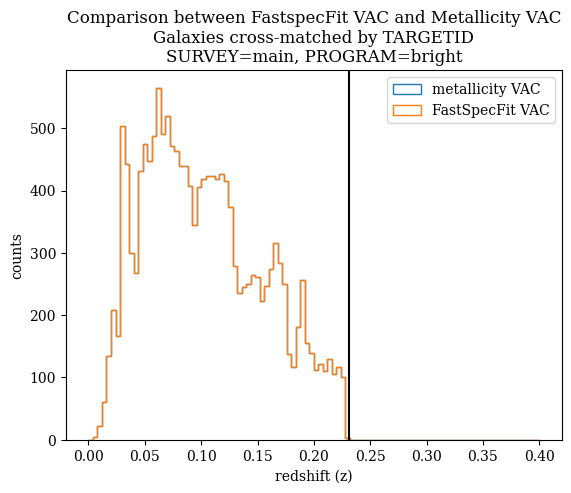

In [5]:
plt.hist(galaxy_metallicity['Z_1'],bins=100, histtype='step', range=(0,0.4), label='metallicity VAC');
plt.hist(galaxy_metallicity['REDSHIFT'],bins=100, histtype='step', range=(0,0.4), label='FastSpecFit VAC');
plt.axvline(0.231, color='k')
plt.xlabel('redshift (z)')
plt.ylabel('counts')
plt.legend(loc='upper right')
plt.title('Comparison between FastspecFit VAC and Metallicity VAC\nGalaxies cross-matched by TARGETID\nSURVEY=main, PROGRAM=bright');

In [7]:
#Fix metallicity table to data range
galaxy_metallicity = galaxy_metallicity[(galaxy_metallicity['OH_p50'] >= -90) & (galaxy_metallicity['NH_p50'] >= -90)]
galaxy_metallicity['OH_p50'] += 12


In [8]:
# counts after removal of invalid OH NO measurements
len(galaxy_metallicity)

16201

In [9]:
galaxy_table['X'].name  = 'X_POS'
galaxy_table['Y'].name  = 'Y_POS'
galaxy_table['Z'].name  = 'Z_POS'

galaxy_metallicity['X'].name = 'X_POS'
galaxy_metallicity['Y'].name = 'Y_POS'
galaxy_metallicity['Z_2'].name = 'Z_POS'

galaxy_table['REDSHIFT'].name = 'Z'

galaxy_metallicity['REDSHIFT'].name = 'Z'

In [11]:
# Use fastspectfit logmstar in metallicity table
galaxy_metallicity['LOGMSTAR_2'].name = 'LOGMSTAR'

In [12]:
# select BGS targets from full table
bgs_select_full = (galaxy_table['BGS_TARGET'] & 2**1 != 0) + (galaxy_table['BGS_TARGET'] & 2**0 != 0)

In [13]:
# select BGS targets from metallcity table
bgs_select = (galaxy_metallicity['BGS_TARGET'] & 2**1 != 0) + (galaxy_metallicity['BGS_TARGET'] & 2**0 != 0)

In [17]:
# extra sub-percent of galaxies are non-BGS bright time targets. May want to remove them from the analyis?
np.sum(bgs_select_full)/len(bgs_select_full),     np.sum(bgs_select)/len(bgs_select)

(0.9956039876231293, 0.994074439849392)

In [19]:
metal_void_count = len(galaxy_metallicity[bgs_select*(galaxy_metallicity['VF_FLAG']==0)])
full_void_count = len(galaxy_table[bgs_select_full*(galaxy_table['VF_FLAG']==0)])

metal_void_count, full_void_count

(8630, 3196511)

In [21]:
metal_wall_count = len(galaxy_metallicity[bgs_select*(galaxy_metallicity['VF_FLAG']==1)])
full_wall_count = len(galaxy_table[bgs_select_full*(galaxy_table['VF_FLAG']==1)])

metal_wall_count, full_wall_count

(7475, 1415958)

In [22]:
metal_void_count/full_void_count

0.002699818646017486

In [23]:
metal_wall_count/full_wall_count

0.005279111386072186

Text(0.5, 0, 'difference in stellar mass (log (M$_*$/M$_\\odot$))')

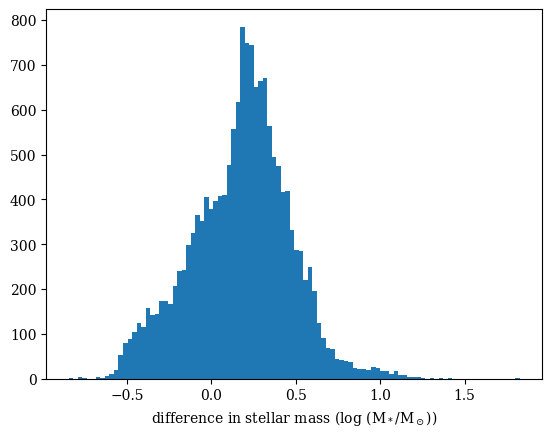

In [25]:
# Comparison of metallicity table's stallr mass and fastspecfit stellar mass
# Not sure why they disagree, but we are using the fastspecfit measure
plt.hist(galaxy_metallicity['LOGMSTAR_1'] - galaxy_metallicity['LOGMSTAR'], bins=100);
plt.xlabel(r'difference in stellar mass (log (M$_*$/M$_\odot$))')

## Define Helper Functions

In [19]:
def mknum (flt):
    """Formats a float for fits headers
    Parameters
    ----------
    flt : float
        float to be formatted
    Returns
    -------
    float
        Formatted float
    """
    if flt is None:
        return None

    #preserve 3 sig figs for numbers starting with "0."
    if abs(flt) < 1:
        return float(f"{flt:.3g}")
    #otherwise round to two decimal places
    else:
        return float(f"{flt:.2f}")

In [20]:
def get_bayes_factor(data_1, data_2, c = 5, max_depth=6, aj=lambda depth: depth**2, log_BF=False):
    """
    nonparamteric Bayes factors

    parameters:

    data_1 : arraylike
        Numpy array of data points sampled from the first distribution
    data_2 : arraylike
        Numpy array of data points sampled from the second distribution
    c : int 
        The tunable paramter c descibed in https://arxiv.org/abs/0910.5060v3
    max_depth : int
        The maximum depth of the partially specified Polya tree as described in https://arxiv.org/abs/0910.5060v3
        The Polya tree has a tree height of max_depth.
    aj : function
        The prescription for calculateing aj terms as a function of tree depth 
        as described in https://arxiv.org/abs/0910.5060v3
    log_BF: bool
        When False, the Bayes factor is returned, and when True, log10(Bayes factor) is returned
    """

    data_switch = len(data_1)
    combined_data = np.concatenate([data_1, data_2])
    del data_1, data_2

    # partition the data into quartiles
    quantiles = np.quantile(combined_data, np.linspace(0,1,2**max_depth + 1))

    # get the log bayes factor
    logbf = _get_bayes_factor(combined_data, data_switch, quantiles, low=0, high=1, c=c, depth=1, max_depth=max_depth, aj=aj)

    # return either the bayes factor or log bayes factor
    if log_BF:
        log10bf = logbf / 2.302585092994046 # np.log(10) = 2.302585092994046
        return log10bf
    else:
        bf = np.exp(logbf)
        return bf

def _get_bayes_factor(combined_data, data_switch, quantiles, low, high, c, depth, max_depth,aj):
    """
    helper function called by get_bayes_factor

    parameters:

    combined_data : arraylike
        Numpy array of data points sampled from the first and second distributions. 
        Data from the second distribution hould follow after data from the first
    data_switch : int
        The array index seperating the two sampled distributions in combined_data
    low : float
        The low quantile for the current Polya tree node
    high : float
        The high quantile for the current Polya tree node
    c : int 
        The tunable paramter c descibed in https://arxiv.org/abs/0910.5060v3
    depth : int
        The depth of the current node in the Polya tree
    max_depth : int
        The maximum depth of the partially specified Polya tree as described in https://arxiv.org/abs/0910.5060v3
    aj : function
        The prescription for calculateing aj terms as a function of tree depth 
        as described in https://arxiv.org/abs/0910.5060v3
    
    """
    
    if depth > max_depth: 
        return 0

    # seelct quartiles
    low_q = quantiles[int((2**max_depth ) * low)]
    mid_q = quantiles[int((2**max_depth ) * (low+high)/2)]
    high_q = quantiles[int((2**max_depth ) * high)]

    # count data in quartiles
    if high == 1:
        data_1_low = np.count_nonzero((combined_data[:data_switch]>=low_q)*(combined_data[:data_switch]<=mid_q))
        data_2_low = np.count_nonzero((combined_data[data_switch:]>=low_q)*(combined_data[data_switch:]<=mid_q))
        data_1_high = np.count_nonzero((combined_data[:data_switch]>=mid_q)*(combined_data[:data_switch]<=high_q))
        data_2_high = np.count_nonzero((combined_data[data_switch:]>=mid_q)*(combined_data[data_switch:]<=high_q))
    else:
        data_1_low = np.count_nonzero((combined_data[:data_switch]>=low_q)*(combined_data[:data_switch]<mid_q))
        data_2_low = np.count_nonzero((combined_data[data_switch:]>=low_q)*(combined_data[data_switch:]<mid_q))
        data_1_high = np.count_nonzero((combined_data[:data_switch]>=mid_q)*(combined_data[:data_switch]<high_q))
        data_2_high = np.count_nonzero((combined_data[data_switch:]>=mid_q)*(combined_data[data_switch:]<high_q))

    # calculate the n_j terms for the current binnings
    data_1_n_j = [data_1_low, data_1_high]
    data_2_n_j = [data_2_low, data_2_high]

    # truncate the tree where there is no data
    if np.sum(data_1_n_j) == 0 or np.sum(data_2_n_j) == 0:
        return 0

    # calculate the a_j term for the current tree depth
    a_j = c * aj(depth)

    # calculate b_j

    log_gamma_summand_1 = 2 * gammaln(a_j) - gammaln(2 * a_j)
    log_gamma_summand_2 = gammaln(a_j + data_1_n_j[0] + data_2_n_j[0]) + gammaln(a_j + data_1_n_j[1] + data_2_n_j[1]) 
    log_gamma_summand_3 = - gammaln(2*a_j + data_1_n_j[0] + data_2_n_j[0] + data_1_n_j[1] + data_2_n_j[1])
    log_gamma_summand_4 = gammaln(2*a_j + data_1_n_j[0] + data_1_n_j[1]) + gammaln(2*a_j + data_2_n_j[0] + data_2_n_j[1])
    log_gamma_summand_5 = - gammaln(a_j + data_1_n_j[0]) - gammaln(a_j + data_2_n_j[0]) - gammaln(a_j + data_1_n_j[1]) - gammaln(a_j + data_2_n_j[1])

    log_b_j = log_gamma_summand_1 + log_gamma_summand_2 + log_gamma_summand_3 + log_gamma_summand_4 + log_gamma_summand_5

    # calculate the product of b_j terms on the left partition of the tree
    log_left_tree_b_j = _get_bayes_factor(combined_data, data_switch, quantiles, low, (low+high)/2, c, depth+1, max_depth, aj)

    # calculate the product of b_j terms on the right partition of the tree
    log_right_tree_b_j = _get_bayes_factor(combined_data, data_switch, quantiles, (low+high)/2, high, c, depth+1, max_depth, aj)

    # calculate the product of the b_j terms
    summed_b_j = log_b_j + log_left_tree_b_j + log_right_tree_b_j

    return summed_b_j


In [21]:
def get_property(prop_name, algorithm, environment, sample, metallicity=False):
    """ 
    select galaxy property

    prop_name: name of property

    algorithm: name of void-finding algorithm ('VF' is only choice currently)

    environment: name of galaxy environment for selection (void, wall, or all)

    sample: DESI tracer used for selection ('BGS', 'BGS Bright', 'BGS Faint', 'DR2')

    """
    if metallicity == True:
        gals = galaxy_metallicity
    elif metallicity == False:
        gals = galaxy_table
    
    if environment == 'void':
        gals = gals[gals[f'{algorithm}_FLAG'] == 1]
    elif environment == 'wall':
        gals = gals[gals[f'{algorithm}_FLAG'] == 0]
    elif environment == 'all':
        gals = gals[(gals[f'{algorithm}_FLAG'] == 0) + (gals[f'{algorithm}_FLAG'] == 1)]
    else:
        raise ValueError('Invalid environment:', environment)

    if sample == 'BGS':
        gals = gals[(gals['BGS_TARGET'] & 2**1 != 0) + (gals['BGS_TARGET'] & 2**0 != 0)]
    elif sample == 'BGS Bright':
        gals = gals[(gals['BGS_TARGET'] & 2**1 != 0)]
    elif sample == 'BGS Faint':
        gals = gals[(gals['BGS_TARGET'] & 2**0 != 0)]
    elif sample != "DR2":
        raise ValueError('Invalid sample:', sample)
        
    if prop_name.lower() in ['m_r', 'mr', 'rabsmag']:
        #return gals['ABSMAG01_SDSS_R']
        gr_color = gals['ABSMAG01_SDSS_G'] - gals['ABSMAG01_SDSS_R']
        
        red_galaxies = gr_color > 0.75
        
        # E-correction for blue galaxies (all galaxies sto start)
        rabsmag_ecorr = gals['ABSMAG01_SDSS_R'] + 1.59*(gals['Z']-0.1)
        
        # E-correction for red galaxies
        rabsmag_ecorr[red_galaxies] = gals['ABSMAG01_SDSS_R'][red_galaxies] + 0.23*(gals['Z'][red_galaxies]-0.1)
        
        return rabsmag_ecorr
        
    elif prop_name.lower() in ['log_mstar', 'logmstar']:
        return gals['LOGMSTAR']
    elif prop_name.lower() in ['color_ur', 'ur', 'u-r']:
        return gals['ABSMAG01_SDSS_U'] - gals['ABSMAG01_SDSS_R']
    elif prop_name.lower() in ['color_gr', 'gr', 'g-r']:
        return gals['ABSMAG01_SDSS_G'] - gals['ABSMAG01_SDSS_R']
    elif prop_name.lower() in ['oh_p50']:
        return gals['OH_p50']
    elif prop_name.lower() in ['no', 'n/o']:
        return gals['NH_p50'] - gals['OH_p50']
        
    elif prop_name.lower() in ['halpha', 'halpha_ew']:
        return gals['HALPHA_EW']
    elif prop_name.lower() in ['log_halpha', 'log_halpha_ew']:
        halpha = np.log10(gals['HALPHA_EW'][gals['HALPHA_EW']>0])
        return halpha
    elif prop_name.lower() == 'sfr':
        return gals['SFR']
    elif prop_name.lower() in ['z', 'redshift']:
        return gals['Z']
    #elif prop_name.lower() == '':
    #    return gals['']
    else:
        raise ValueError('Invalid Property:'+prop_name)

In [22]:
def report_bayes_factors_metals(sample, algorithm = 'VF'):

    """ 

    calculate Bayes factors for the metallicity sample
    
    sample: DESI tracer used for selection

    algorithm: name of void-finding algorithm ('VF' is only choice currently)


    """

    
    """if algorithm == 'VF':
        algorithm_name = 'VoidFinder'
    elif algorithm == 'VR':
        algorithm_name = '$V^2$ REV.'
    elif algorithm == 'VV':
        algorithm_name = '$V^2$ VIDE'
    else:
        raise ValueError('Invalid algorithm:', algorithm)"""
        
    # Absolute Magnitude
    bf_Mr = get_bayes_factor(get_property('mr', algorithm, 'wall', sample, metallicity = True), get_property('mr', algorithm, 'void', sample, metallicity = True), log_BF=True)
    
    # Stellar Mass
    bf_mass = get_bayes_factor(get_property('log_mstar', algorithm, 'wall', sample, metallicity = True), get_property('log_mstar', algorithm, 'void', sample, metallicity = True), log_BF=True)

    # u-r Color
    bf_ur = get_bayes_factor(get_property('ur', algorithm, 'wall', sample, metallicity = True), get_property('ur', algorithm, 'void', sample, metallicity = True), log_BF=True)

    # g-r Color
    bf_gr = get_bayes_factor(get_property('gr', algorithm, 'wall', sample, metallicity = True), get_property('gr', algorithm, 'void', sample, metallicity = True), log_BF=True)
    
    # log10(Halpha EW)
    bf_Ha = get_bayes_factor(get_property('log_halpha', algorithm, 'wall', sample, metallicity = True), get_property('log_halpha', algorithm, 'void', sample, metallicity = True), log_BF=True)


    
    bf_results = {
        "Absolute Magnitude": bf_Mr,
        "Stellar Mass": bf_mass,
        "Color (u-r)": bf_ur,
        "Color (g-r)": bf_gr,
        "log10(Hα EW)": bf_Ha,
    }
    
    return bf_results

In [23]:
def report_bayes_factors(sample, algorithm = 'VF'):

    """ 

    calculate Bayes factors for the full sample
    
    sample: DESI tracer used for selection ('BGS', 'BGS Bright', 'BGS Faint', 'DR2')

    algorithm: name of void-finding algorithm ('VF' is only choice currently)


    """

    """if algorithm == 'VF':
        algorithm_name = 'VoidFinder'
    elif algorithm == 'VR':
        algorithm_name = '$V^2$ REV.'
    elif algorithm == 'VV':
        algorithm_name = '$V^2$ VIDE'
    else:
        raise ValueError('Invalid algorithm:', algorithm)"""
        
    # Absolute Magnitude
    bf_Mr = get_bayes_factor(get_property('mr', algorithm, 'wall', sample), get_property('mr', algorithm, 'void', sample), log_BF=True)
    
    # Stellar Mass
    bf_mass = get_bayes_factor(get_property('log_mstar', algorithm, 'wall', sample), get_property('log_mstar', algorithm, 'void', sample), log_BF=True)

    # u-r Color
    bf_ur = get_bayes_factor(get_property('ur', algorithm, 'wall', sample), get_property('ur', algorithm, 'void', sample), log_BF=True)

    # g-r Color
    bf_gr = get_bayes_factor(get_property('gr', algorithm, 'wall', sample), get_property('gr', algorithm, 'void', sample), log_BF=True)
    
    # log10(Halpha EW)
    bf_Ha = get_bayes_factor(get_property('log_halpha', algorithm, 'wall', sample), get_property('log_halpha', algorithm, 'void', sample), log_BF=True)

    # o/h
    bf_oh_p50 = get_bayes_factor(get_property('oh_p50', algorithm, 'wall', sample, metallicity = True), get_property('oh_p50', algorithm, 'void', sample, metallicity = True), log_BF=True)

    # n/o
    bf_no = get_bayes_factor(get_property('no', algorithm, 'wall', sample, metallicity = True), get_property('no', algorithm, 'void', sample, metallicity = True), log_BF=True)

    
    bf_results = {
        "Absolute Magnitude": bf_Mr,
        "Stellar Mass": bf_mass,
        "Color (u-r)": bf_ur,
        "Color (g-r)": bf_gr,
        "log10(Hα EW)": bf_Ha,
        "12 + log(O/H)": bf_oh_p50,
        "log(N/O)" : bf_no,
    }
    
    return bf_results

## Define Plotting Functions

In [24]:
def plot_properites_metals(sample, algorithm):

    """ 

    calculate Bayes factors for the metallicity sample
    
    sample: DESI tracer used for selection ('BGS', 'BGS Bright', 'BGS Faint', 'DR2')

    algorithm: name of void-finding algorithm ('VF' is only choice currently)


    """


    if algorithm == 'VF':
        algorithm_name = 'VoidFinder'
    elif algorithm == 'VR':
        algorithm_name = '$V^2$ REV.'
    elif algorithm == 'VV':
        algorithm_name = '$V^2$ VIDE'
    else:
        raise ValueError('Invalid algorithm:', algorithm)

    #font sizes
    title_size=23
    size = 20
    
    # 1. Absolute Magnitude (M_r)
    
    plt.figure(figsize=(8, 6))
    mr = get_property('mr', algorithm, 'all', sample, metallicity=True)
    print(np.std(mr), len(mr))
    print('mean (all)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    plt.hist(mr, bins=100, density=True, alpha=0.5, color='gray', label='All')
    
    mr = get_property('mr', algorithm, 'wall', sample, metallicity=True)
    shift = np.mean(mr)
    shift_uncert = np.std(mr)**2/len(mr)
    print('mean (wall)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    plt.hist(mr, bins=100, density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    mr = get_property('mr', algorithm, 'void', sample, metallicity=True)
    shift -= np.mean(mr)
    shift_uncert += np.std(mr)**2/len(mr)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    print('mean shift', shift, shift_uncert)
    plt.hist(mr, bins=100, density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlabel(r"r-band absolute magnitude ($^{0.1}M_r$)", fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title("Magnitude Distribution with Respect to\nGalaxy Environment", fontsize=title_size)
    plt.legend(fontsize=size)
    plt.xlim(-14, -24)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_Absolute_Magnitude_metal.pdf", bbox_inches='tight', dpi=400)
    plt.show()


    # 2. Stellar Mass (Log M_star)
    plt.figure(figsize=(8, 6))
    mstar = get_property('log_mstar', algorithm, 'all', sample, metallicity=True)
    print(np.std(mstar), len(mstar))
    print('mean (all)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    plt.hist(mstar, bins=100, range=(6,11), density=True, alpha=0.5, color='gray', label='All')
    
    mstar = get_property('log_mstar', algorithm, 'wall', sample, metallicity=True)
    shift = np.mean(mstar)
    shift_uncert = np.std(mstar)**2/len(mstar)
    print('mean (wall)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    plt.hist(mstar, bins=100, range=(6,11), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    mstar = get_property('log_mstar', algorithm, 'void', sample, metallicity=True)
    shift -= np.mean(mstar)
    shift_uncert += np.std(mstar)**2/len(mstar)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    print('mean shift', shift, shift_uncert)
    plt.hist(mstar, bins=100, range=(6,11), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlabel(r'stellar mass (log (M$_*$/M$_\odot$))', fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    #plt.xlim(7, 13)
    plt.gca().tick_params(labelsize=size)
    #plt.savefig("images/VF_Stellar_Mass.pdf", bbox_inches='tight')
    plt.show()

    # 3. Color (u-r)
    plt.figure(figsize=(8, 6))
    ur = get_property('ur', algorithm, 'all', sample, metallicity=True)
    print(np.std(ur), len(ur))
    print('mean (all)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    plt.hist(ur, bins=100, density=True, alpha=0.5, color='gray', label='All')
    
    ur = get_property('ur', algorithm, 'wall', sample, metallicity=True)
    shift = np.mean(ur)
    shift_uncert = np.std(ur)**2/len(ur)
    print('mean (wall)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    plt.hist(ur, bins=100, density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    ur = get_property('ur', algorithm, 'void', sample, metallicity=True)
    shift -= np.mean(ur)
    shift_uncert += np.std(ur)**2/len(ur)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    print('mean shift', shift, shift_uncert)
    plt.hist(ur, bins=100, density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlim(0,3.5)
    plt.xlabel(r"$u-r$ color", fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.gca().tick_params(labelsize=size)
    #plt.savefig("images/VF_Color_ur.pdf", bbox_inches='tight')
    plt.show()

    
    # 4. Color (g-r)
    plt.figure(figsize=(8, 6))
    gr = get_property('gr', algorithm, 'all', sample, metallicity=True)
    print(np.std(gr), len(gr))
    print('mean (all)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    plt.hist(gr, bins=100, density=True, alpha=0.5, color='gray', label='All')
    
    gr = get_property('gr', algorithm, 'wall', sample, metallicity=True)
    shift = np.mean(gr)
    shift_uncert = np.std(gr)**2/len(gr)
    print('mean (wall)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    plt.hist(gr, bins=100, density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    gr = get_property('gr', algorithm, 'void', sample, metallicity=True)
    shift -= np.mean(gr)
    shift_uncert += np.std(gr)**2/len(gr)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    print('mean shift', shift, shift_uncert)
    plt.hist(gr, bins=100, density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlim(-1,1.25)
    plt.xlabel(r"$g-r$ color", fontsize=size)
    #plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.gca().tick_params(labelsize=size)
    #plt.savefig("images/VF_Color_gr.pdf", bbox_inches='tight')
    plt.show()

    
    # 5. Halpha EW (log scale)
    plt.figure(figsize=(8, 6))
    halpha = get_property('log_halpha', algorithm, 'all', sample, metallicity=True)
    halpha = halpha[np.isfinite(halpha)]
    print('mean (all)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    plt.hist(halpha, bins=100, density=True, alpha=0.5, color='gray', label='All')
    
    halpha = get_property('log_halpha', algorithm, 'wall', sample, metallicity=True)
    halpha = halpha[np.isfinite(halpha)]
    shift = np.mean(halpha)
    shift_uncert = np.std(halpha)**2/len(halpha)
    print('mean (wall)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    plt.hist(halpha, bins=100, density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    halpha = get_property('log_halpha', algorithm, 'void', sample, metallicity=True)
    halpha = halpha[np.isfinite(halpha)]
    shift -= np.mean(halpha)
    shift_uncert += np.std(halpha)**2/len(halpha)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    print('mean shift', shift, shift_uncert)
    plt.hist(halpha, bins=100, density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlabel(r"log$_{10}$(H$\alpha$ equivalent width)", fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.xlim(0, 4)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_HalphaEW_metal.pdf", bbox_inches='tight')
    plt.show()
    


In [25]:
def plot_properites_and_metals(sample, algorithm):

    """ 

    Plot distributions for the metallicity sample
    
    sample: DESI tracer used for selection ('BGS', 'BGS Bright', 'BGS Faint', 'DR2')

    algorithm: name of void-finding algorithm ('VF' is only choice currently)


    """

    if algorithm == 'VF':
        algorithm_name = 'VoidFinder'
    elif algorithm == 'VR':
        algorithm_name = '$V^2$ REV.'
    elif algorithm == 'VV':
        algorithm_name = '$V^2$ VIDE'
    else:
        raise ValueError('Invalid algorithm:', algorithm)

    #font sizes
    title_size=23
    size = 20
    
    # 1. Absolute Magnitude (M_r)
    
    plt.figure(figsize=(8, 6))
    mr = get_property('mr', algorithm, 'all', sample)
    print(np.std(mr), len(mr))
    print('mean (all)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    plt.hist(mr, bins=300, range=(-24, -14), density=True, alpha=0.5, color='gray', label='All')
    
    mr = get_property('mr', algorithm, 'wall', sample)
    shift = np.mean(mr)
    shift_uncert = np.std(mr)**2/len(mr)
    print('mean (wall)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    plt.hist(mr, bins=300, range=(-24, -14), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    mr = get_property('mr', algorithm, 'void', sample)
    shift -= np.mean(mr)
    shift_uncert += np.std(mr)**2/len(mr)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    print('mean shift', shift, shift_uncert)
    plt.hist(mr, bins=300, range=(-24, -14), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')

    mr = get_property('mr', algorithm, 'all', sample, metallicity=True)
    plt.hist(mr, bins=300, range=(-24, -14), density=True, histtype='step', linewidth=1.2, color='cyan', label='Metals')
    
    plt.xlabel(r"r-band absolute magnitude ($^{0.1}M_r$)", fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    plt.title("Magnitude Distribution with Respect to\nGalaxy Environment", fontsize=title_size)
    plt.legend(fontsize=size)
    plt.xlim(-14, -24)
    plt.gca().tick_params(labelsize=size)
    #plt.savefig("images/VF_Absolute_Magnitude.pdf", bbox_inches='tight', dpi=400)
    plt.show()


    # 2. Stellar Mass (Log M_star)
    plt.figure(figsize=(8, 6))
    mstar = get_property('log_mstar', algorithm, 'all', sample)
    print(np.std(mstar), len(mstar))
    print('mean (all)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    plt.hist(mstar, bins=300, range=(7, 12), density=True, alpha=0.5, color='gray', label='All')
    
    mstar = get_property('log_mstar', algorithm, 'wall', sample)
    shift = np.mean(mstar)
    shift_uncert = np.std(mstar)**2/len(mstar)
    print('mean (wall)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    plt.hist(mstar, bins=300, range=(7, 12), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    mstar = get_property('log_mstar', algorithm, 'void', sample)
    shift -= np.mean(mstar)
    shift_uncert += np.std(mstar)**2/len(mstar)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    print('mean shift', shift, shift_uncert)
    plt.hist(mstar, bins=300, range=(7, 12), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    
    mstar = get_property('log_mstar', algorithm, 'all', sample, metallicity=True)
    plt.hist(mstar, bins=300, range=(7, 12),  density=True, histtype='step', linewidth=1.2, color='cyan', label='Metals')
    
    plt.xlabel(r'stellar mass (log (M$_*$/M$_\odot$))', fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.xlim(7, 12)
    plt.gca().tick_params(labelsize=size)
    #plt.savefig("images/VF_Stellar_Mass.pdf", bbox_inches='tight')
    plt.show()

    
    # 3. Color (u-r)
    plt.figure(figsize=(8, 6))
    ur = get_property('ur', algorithm, 'all', sample)
    print(np.std(ur), len(ur))
    print('mean (all)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    plt.hist(ur, bins=300, range=(0., 3.5), density=True, alpha=0.5, color='gray', label='All')
    
    ur = get_property('ur', algorithm, 'wall', sample)
    shift = np.mean(ur)
    shift_uncert = np.std(ur)**2/len(ur)
    print('mean (wall)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    plt.hist(ur, bins=300, range=(0., 3.5), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    ur = get_property('ur', algorithm, 'void', sample)
    shift -= np.mean(ur)
    shift_uncert += np.std(ur)**2/len(ur)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    print('mean shift', shift, shift_uncert)
    plt.hist(ur, bins=300, range=(0., 3.5), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    
    ur = get_property('ur', algorithm, 'all', sample, metallicity=True)
    plt.hist(ur, bins=300, range=(0., 3.5),  density=True, histtype='step', linewidth=1.2, color='cyan', label='Metals')
    
    plt.xlim(0.,3.5)
    plt.xlabel(r"$u-r$ color", fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.gca().tick_params(labelsize=size)
    #plt.savefig("images/VF_Color_ur.pdf", bbox_inches='tight')
    plt.show()

    
    # 4. Color (g-r)
    plt.figure(figsize=(8, 6))
    gr = get_property('gr', algorithm, 'all', sample)
    print(np.std(gr), len(gr))
    print('mean (all)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    plt.hist(gr, bins=300, range=(0., 1.8), density=True, alpha=0.5, color='gray', label='All')
    
    gr = get_property('gr', algorithm, 'wall', sample)
    shift = np.mean(gr)
    shift_uncert = np.std(gr)**2/len(gr)
    print('mean (wall)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    plt.hist(gr, bins=300, range=(0., 1.2), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    gr = get_property('gr', algorithm, 'void', sample)
    shift -= np.mean(gr)
    shift_uncert += np.std(gr)**2/len(gr)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    print('mean shift', shift, shift_uncert)
    plt.hist(gr, bins=300, range=(0., 1.2), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    
    gr = get_property('gr', algorithm, 'all', sample, metallicity=True)
    plt.hist(gr, bins=300, range=(0., 1.2),  density=True, histtype='step', linewidth=1.2, color='cyan', label='Metals')
    
    plt.xlim(0,1.2)
    plt.xlabel(r"$g-r$ color", fontsize=size)
    #plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.gca().tick_params(labelsize=size)
    #plt.savefig("images/VF_Color_gr.pdf", bbox_inches='tight')
    plt.show()

    
    # 5. Halpha EW (log scale)
    plt.figure(figsize=(8, 6))
    halpha = get_property('log_halpha', algorithm, 'all', sample)
    halpha = halpha[np.isfinite(halpha)]
    print('mean (all)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    plt.hist(halpha, bins=300, range=(-3, 4), density=True, alpha=0.5, color='gray', label='All')
    
    halpha = get_property('log_halpha', algorithm, 'wall', sample)
    halpha = halpha[np.isfinite(halpha)]
    shift = np.mean(halpha)
    shift_uncert = np.std(halpha)**2/len(halpha)
    print('mean (wall)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    plt.hist(halpha, bins=300, range=(-3, 4), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    halpha = get_property('log_halpha', algorithm, 'void', sample)
    halpha = halpha[np.isfinite(halpha)]
    shift -= np.mean(halpha)
    shift_uncert += np.std(halpha)**2/len(halpha)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    print('mean shift', shift, shift_uncert)
    plt.hist(halpha, bins=300, range=(-3, 4), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')

    halpha = get_property('log_halpha', algorithm, 'all', sample, metallicity=True)
    plt.hist(halpha, bins=300, range=(-3, 4),  density=True, histtype='step', linewidth=1.2, color='cyan', label='Metals')
    
    
    plt.xlabel(r"log$_{10}$(H$\alpha$ equivalent width)", fontsize=size)
    #plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    plt.legend(fontsize=size, loc='upper left')
    plt.xlim(-3, 4)
    plt.gca().tick_params(labelsize=size)
    #plt.savefig("images/VF_HalphaEW.pdf", bbox_inches='tight')
    plt.show()
    
    

    



In [26]:
def plot_properites(sample, algorithm):

    """ 

    Plot distributions for the full sample
    
    sample: DESI tracer used for selection ('BGS', 'BGS Bright', 'BGS Faint', 'DR2')

    algorithm: name of void-finding algorithm ('VF' is only choice currently)


    """

    """if algorithm == 'VF':
        algorithm_name = 'VoidFinder'
    elif algorithm == 'VR':
        algorithm_name = '$V^2$ REV.'
    elif algorithm == 'VV':
        algorithm_name = '$V^2$ VIDE'
    else:
        raise ValueError('Invalid algorithm:', algorithm)"""

    #font sizes
    title_size=23
    size = 20
    
    # 1. Absolute Magnitude (M_r)
    
    plt.figure(figsize=(8, 6))
    mr = get_property('mr', algorithm, 'all', sample)
    print(np.std(mr), len(mr))
    print('mean (all)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    plt.hist(mr, bins=300, range=(-24, -14), density=True, alpha=0.5, color='gray', label='All')
    
    mr = get_property('mr', algorithm, 'wall', sample)
    shift = np.mean(mr)
    shift_uncert = np.std(mr)**2/len(mr)
    print('mean (wall)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    plt.hist(mr, bins=300, range=(-24, -14), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    mr = get_property('mr', algorithm, 'void', sample)
    shift -= np.mean(mr)
    shift_uncert += np.std(mr)**2/len(mr)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(mr), np.std(mr)/np.sqrt(len(mr)))
    print('mean shift', shift, shift_uncert)
    plt.hist(mr, bins=300, range=(-24, -14), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlabel(r"r-band absolute magnitude ($^{0.1}M_r$)", fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    plt.title("Magnitude Distribution with Respect to\nGalaxy Environment", fontsize=title_size)
    plt.legend(fontsize=size)
    plt.xlim(-14, -24)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_Absolute_Magnitude.pdf", bbox_inches='tight', dpi=400)
    plt.show()


    # 2. Stellar Mass (Log M_star)
    plt.figure(figsize=(8, 6))
    mstar = get_property('log_mstar', algorithm, 'all', sample)
    print(np.std(mstar), len(mstar))
    print('mean (all)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    plt.hist(mstar, bins=300, range=(7, 12), density=True, alpha=0.5, color='gray', label='All')
    
    mstar = get_property('log_mstar', algorithm, 'wall', sample)
    shift = np.mean(mstar)
    shift_uncert = np.std(mstar)**2/len(mstar)
    print('mean (wall)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    plt.hist(mstar, bins=300, range=(7, 12), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    mstar = get_property('log_mstar', algorithm, 'void', sample)
    shift -= np.mean(mstar)
    shift_uncert += np.std(mstar)**2/len(mstar)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(mstar), np.std(mstar)/np.sqrt(len(mstar)))
    print('mean shift', shift, shift_uncert)
    plt.hist(mstar, bins=300, range=(7, 12), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlabel(r'stellar mass (log (M$_*$/M$_\odot$))', fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.xlim(7, 12)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_Stellar_Mass.pdf", bbox_inches='tight')
    plt.show()

    
    # 3. Color (u-r)
    plt.figure(figsize=(8, 6))
    ur = get_property('ur', algorithm, 'all', sample)
    print(np.std(ur), len(ur))
    print('mean (all)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    plt.hist(ur, bins=300, range=(0.5, 3.5), density=True, alpha=0.5, color='gray', label='All')
    
    ur = get_property('ur', algorithm, 'wall', sample)
    shift = np.mean(ur)
    shift_uncert = np.std(ur)**2/len(ur)
    print('mean (wall)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    plt.hist(ur, bins=300, range=(0.5, 3.5), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    ur = get_property('ur', algorithm, 'void', sample)
    shift -= np.mean(ur)
    shift_uncert += np.std(ur)**2/len(ur)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(ur), np.std(ur)/np.sqrt(len(ur)))
    print('mean shift', shift, shift_uncert)
    plt.hist(ur, bins=300, range=(0.5, 3.5), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlim(0,3.5)
    plt.xlabel(r"$u-r$ color", fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_Color_ur.pdf", bbox_inches='tight')
    plt.show()

    
    # 4. Color (g-r)
    plt.figure(figsize=(8, 6))
    gr = get_property('gr', algorithm, 'all', sample)
    print(np.std(gr), len(gr))
    print('mean (all)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    plt.hist(gr, bins=300, range=(0., 1.2), density=True, alpha=0.5, color='gray', label='All')
    
    gr = get_property('gr', algorithm, 'wall', sample)
    shift = np.mean(gr)
    shift_uncert = np.std(gr)**2/len(gr)
    print('mean (wall)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    plt.hist(gr, bins=300, range=(0., 1.2), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    gr = get_property('gr', algorithm, 'void', sample)
    shift -= np.mean(gr)
    shift_uncert += np.std(gr)**2/len(gr)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(gr), np.std(gr)/np.sqrt(len(gr)))
    print('mean shift', shift, shift_uncert)
    plt.hist(gr, bins=300, range=(0., 1.2), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlim(0,1.2)
    plt.xlabel(r"$g-r$ color", fontsize=size)
    #plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_Color_gr.pdf", bbox_inches='tight')
    plt.show()

    
    # 5. Halpha EW (log scale)
    plt.figure(figsize=(8, 6))
    halpha = get_property('log_halpha', algorithm, 'all', sample)
    halpha = halpha[np.isfinite(halpha)]
    print('mean (all)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    plt.hist(halpha, bins=300, range=(-3, 4), density=True, alpha=0.5, color='gray', label='All')
    
    halpha = get_property('log_halpha', algorithm, 'wall', sample)
    halpha = halpha[np.isfinite(halpha)]
    shift = np.mean(halpha)
    shift_uncert = np.std(halpha)**2/len(halpha)
    print('mean (wall)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    plt.hist(halpha, bins=300, range=(-3, 4), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    halpha = get_property('log_halpha', algorithm, 'void', sample)
    halpha = halpha[np.isfinite(halpha)]
    shift -= np.mean(halpha)
    shift_uncert += np.std(halpha)**2/len(halpha)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(halpha), np.std(halpha)/np.sqrt(len(halpha)))
    print('mean shift', shift, shift_uncert)
    plt.hist(halpha, bins=300, range=(-3, 4), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlabel(r"log$_{10}$(H$\alpha$ equivalent width)", fontsize=size)
    #plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    plt.legend(fontsize=size)
    plt.xlim(-3, 4)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_HalphaEW.pdf", bbox_inches='tight')
    plt.show()
    
    
    # 6. oh_p50
    plt.figure(figsize=(8, 6))
    oh_p50 = get_property('oh_p50', algorithm, 'all', sample, metallicity=True)
    print('mean (all)', np.mean(oh_p50), np.std(oh_p50)/np.sqrt(len(oh_p50)))
    plt.hist(oh_p50, bins=100, range = (7, 9.5), density=True, alpha=0.5, color='gray', label='All')
    
    oh_p50 = get_property('oh_p50', algorithm, 'wall', sample, metallicity=True)
    shift = np.mean(oh_p50)
    shift_uncert = np.std(oh_p50)**2/len(oh_p50)
    print('mean (wall)', np.mean(oh_p50), np.std(oh_p50)/np.sqrt(len(oh_p50)))
    plt.hist(oh_p50, bins=100, range = (7, 9.5), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    oh_p50 = get_property('oh_p50', algorithm, 'void', sample, metallicity=True)
    shift -= np.mean(oh_p50)
    shift_uncert += np.std(oh_p50)**2/len(oh_p50)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(oh_p50), np.std(oh_p50)/np.sqrt(len(oh_p50)))
    print('mean shift', shift, shift_uncert)
    plt.hist(oh_p50, bins=100, range = (7, 9.5), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlim(7, 9.5)
    plt.xlabel(r"12 + log(O/H)", fontsize=size)
    plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_metallicity_oh_p50.pdf", bbox_inches='tight')
    plt.show()

    
    # 7. n/o
    plt.figure(figsize=(8, 6))
    no = get_property('no', algorithm, 'all', sample, metallicity=True)
    print('mean (all)', np.mean(no), np.std(no)/np.sqrt(len(no)))
    plt.hist(no, bins=100, range = (-14.5, -12.), density=True, alpha=0.5, color='gray', label='All')
    
    no = get_property('no', algorithm, 'wall', sample, metallicity=True)
    shift = np.mean(no)
    shift_uncert = np.std(no)**2/len(no)
    print('mean (wall)', np.mean(no), np.std(no)/np.sqrt(len(no)))
    plt.hist(no, bins=100, range = (-14.5, -12.), density=True, histtype='step', linestyle='--', linewidth=1.2, color='black', label='Wall')
    
    no = get_property('no', algorithm, 'void', sample, metallicity=True)
    shift -= np.mean(no)
    shift_uncert += np.std(no)**2/len(no)
    shift_uncert = np.sqrt(shift_uncert)
    print('mean (void)', np.mean(no), np.std(no)/np.sqrt(len(no)))
    print('mean shift', shift, shift_uncert)
    plt.hist(no, bins=100, range = (-14.5, -12.), density=True, histtype='step', linestyle='solid', linewidth=1.2, color='red', label='Void')
    plt.xlim(-14.5,-12)
    plt.xlabel(r"log(N/O)", fontsize=size)
    #plt.ylabel("normalized counts", fontsize=size)
    #plt.title(f"{algorithm_name} ({sample})", fontsize=size)
    #plt.legend(fontsize=size)
    plt.gca().tick_params(labelsize=size)
    plt.savefig("images/VF_metallicity_no.pdf", bbox_inches='tight')
    plt.show()


In [27]:
def get_mr_z_bin(redshift, zmin, zmax, mr, mrmin, mrmax, galaxy_property, prop_name):

    select = (redshift < zmax) * (redshift > zmin) * (mr < mrmax) * (mr > mrmin)
    if prop_name == 'halpha':
        galaxy_property=galaxy_property[select]
        galaxy_property = galaxy_property[galaxy_property>0]
        prop = np.log10(galaxy_property)
        prop = prop[(prop>-3)*(prop<5)]
        return prop
    return galaxy_property[select]

In [28]:
def property_histograms_data(prop_name, mr_bins, num_z_bins=7, sample='BGS'):
    """
    For each (Mr, z) bin used in plot_bayes_factor_heatmap, 
    plot a histogram comparing the galaxy property distribution
    for void vs wall galaxies.
    """

    #Set metallicity
    if prop_name.lower() in ['oh_p50','no', 'n/o']:
        metallicity = True
    else:
        metallicity = False

    # Load data
    void_property = get_property(prop_name, 'VF', 'void', sample, metallicity)
    wall_property = get_property(prop_name, 'VF', 'wall', sample, metallicity)
    void_redshift = get_property('z', 'VF', 'void', sample, metallicity)
    wall_redshift = get_property('z', 'VF', 'wall',sample, metallicity)
    all_redshift = get_property('z', 'VF', 'all',sample, metallicity)
    void_mr = get_property('mr', 'VF', 'void', sample, metallicity)
    wall_mr = get_property('mr', 'VF', 'wall', sample, metallicity)
    all_mr = get_property('mr', 'VF', 'all', sample, metallicity)

    results=[]
    for mr_i, (mrmin, mrmax) in enumerate(zip(mr_bins[:-1], mr_bins[1:])):

        # Determine redshift bins
        void_pre_bin = get_mr_z_bin(void_redshift, 0, np.inf, void_mr, mrmin, mrmax, void_redshift, 'redshift')
        wall_pre_bin = get_mr_z_bin(wall_redshift, 0, np.inf, wall_mr, mrmin, mrmax, wall_redshift, 'redshift')
        combined_pre_bin = get_mr_z_bin(all_redshift, 0, np.inf, all_mr, mrmin, mrmax, all_redshift, 'redshift')

        if len(combined_pre_bin) == 0:
            continue

        z_bins = np.quantile(combined_pre_bin, np.linspace(0, 1, num_z_bins+1))

        # Loop over z bins
        for z_i, (zmin, zmax) in enumerate(zip(z_bins[:-1], z_bins[1:])):

            # Select property values for the bin
            void_bin = get_mr_z_bin(void_redshift, zmin, zmax, void_mr, mrmin, mrmax, 
                                    void_property, prop_name)
            wall_bin = get_mr_z_bin(wall_redshift, zmin, zmax, wall_mr, mrmin, mrmax, 
                                    wall_property, prop_name)

            # Need data from both environments
            if len(void_bin) == 0 or len(wall_bin) == 0:
                continue
            """
            # Same downsampling as heatmap
            min_len = min(len(void_bin), len(wall_bin))
            np.random.seed(0)
            void_bin = np.random.choice(void_bin, min_len, replace=False)
            wall_bin = np.random.choice(wall_bin, min_len, replace=False)
            """
            results.append((mr_i, z_i, mrmin, mrmax, zmin, zmax, void_bin, wall_bin))

    return(results)

In [29]:
def jackknife_heatmap(prop_name, num_samples, mr_bins, num_z_bins=6, sample='BGS'):
    """
    Plot Bayes factor heatmap of Wall vs void
    of property for different mr and redshift bins

    prop_name: galaxy property to be plotted

    num_mr/z_bins: int
                   Number of bins the galaxies are seperated into for final heatmap

    Sample: Which survey used for galaxies
            BGS for Bright+Faint, BGS Bright for Bright
    
    Lim17: Boolean
           Force magnitude bin for mr_max to Mr=-17
    """
    
    #Check if metallicity
    if prop_name.lower() in ['oh_p50','no', 'n/o']:
        metallicity = True
    else:
        metallicity = False

    # Load data
    void_property = get_property(prop_name, 'VF', 'void', sample, metallicity)
    wall_property = get_property(prop_name, 'VF', 'wall', sample, metallicity)
    void_redshift = get_property('z', 'VF', 'void', sample, metallicity)
    wall_redshift = get_property('z', 'VF', 'wall',sample, metallicity)
    all_redshift = get_property('z', 'VF', 'all',sample, metallicity)
    void_mr = get_property('mr', 'VF', 'void', sample, metallicity)
    wall_mr = get_property('mr', 'VF', 'wall', sample, metallicity)
    all_mr = get_property('mr', 'VF', 'all', sample, metallicity)

    # Initialize Bayes factor storage
    bayes_factors_template = {
        'factors': [],
        'void_counts': [],
        'wall_counts': [],
        'zmin': [],
        'zmax': [],
        'mrmin': [],
        'mrmax': []
    }
    bayes_factors = {sample: copy.deepcopy(bayes_factors_template) for sample in range(num_samples)}

    for sample in range(num_samples):

        for mrmin, mrmax in zip(mr_bins[:-1], mr_bins[1:]):
            # Determine redshift bins
            void_pre_bin = get_mr_z_bin(void_redshift, 0, np.inf, void_mr, mrmin, mrmax, void_redshift, 'redshift')
            wall_pre_bin = get_mr_z_bin(wall_redshift, 0, np.inf, wall_mr, mrmin, mrmax, wall_redshift, 'redshift')
            combined_pre_bin = get_mr_z_bin(all_redshift, 0, np.inf, all_mr, mrmin, mrmax, all_redshift, 'redshift')
    
            if len(combined_pre_bin) == 0:
                continue
    
            z_bins = np.quantile(combined_pre_bin, np.linspace(0, 1, num_z_bins+1))
    
            for zmin, zmax in zip(z_bins[:-1], z_bins[1:]):
                void_bin = get_mr_z_bin(void_redshift, zmin, zmax, void_mr, mrmin, mrmax, void_property, prop_name)
                wall_bin = get_mr_z_bin(wall_redshift, zmin, zmax, wall_mr, mrmin, mrmax, wall_property, prop_name)
    
                #Get Bayes Factors
                if len(void_bin) > 0 and len(wall_bin) > 0:

                    void_bin = void_bin.data
                    wall_bin = wall_bin.data
                    
                    np.random.seed(0)
                    np.random.shuffle(void_bin)
                    np.random.shuffle(wall_bin)

                    start_void_at = int(len(void_bin) * sample/num_samples)
                    end_void_at = int(len(void_bin) * (1 + (sample-1)/num_samples))
                    start_wall_at = int(len(wall_bin) * sample/num_samples)
                    end_wall_at = int(len(wall_bin) * (1 + (sample-1)/num_samples))

                    void_bin = void_bin.take(range(start_void_at, end_void_at), mode='wrap')
                    wall_bin = wall_bin.take(range(start_wall_at, end_wall_at), mode='wrap')                    
                    
                    bf = get_bayes_factor(wall_bin, void_bin, log_BF=True)
    
                    bayes_factors[sample]['factors'].append(bf)
                    bayes_factors[sample]['void_counts'].append(len(void_bin))
                    bayes_factors[sample]['wall_counts'].append(len(wall_bin))
                    bayes_factors[sample]['zmin'].append(zmin)
                    bayes_factors[sample]['zmax'].append(zmax)
                    bayes_factors[sample]['mrmin'].append(mrmin)
                    bayes_factors[sample]['mrmax'].append(mrmax)
    
    return bayes_factors


In [30]:
def plot_heatmap(prop_name, title, mr_bins, num_z_bins=6, linewidth=.2, axsize=20, color='PiYG', sample='BGS', 
                 ax=None, save_path = None, display_plot=True, c = 5, max_depth=6):
    """
    Plot Bayes factor heatmap of Wall vs void
    of property for different mr and redshift bins

    prop_name: galaxy property to be plotted

    num_mr/z_bins: int
                   Number of bins the galaxies are seperated into for final heatmap

    Sample: Which survey used for galaxies
            BGS for Bright+Faint, BGS Bright for Bright
    
    Lim17: Boolean
           Force magnitude bin for mr_max to Mr=-17
    """
    if ax is None:
        fig, ax = plt.subplots()

    
    #Check if metallicity
    if prop_name.lower() in ['oh_p50','no', 'n/o']:
        metallicity = True
    else:
        metallicity = False

    # Load data
    void_property = get_property(prop_name, 'VF', 'void', sample, metallicity)
    wall_property = get_property(prop_name, 'VF', 'wall', sample, metallicity)
    void_redshift = get_property('z', 'VF', 'void', sample, metallicity)
    wall_redshift = get_property('z', 'VF', 'wall',sample, metallicity)
    all_redshift = get_property('z', 'VF', 'all',sample, metallicity)
    void_mr = get_property('mr', 'VF', 'void', sample, metallicity)
    wall_mr = get_property('mr', 'VF', 'wall', sample, metallicity)
    all_mr = get_property('mr', 'VF', 'all', sample, metallicity)

    # Initialize Bayes factor storage
    bayes_factors = {
        'factors': [],
        'void_counts': [],
        'wall_counts': [],
        'zmin': [],
        'zmax': [],
        'mrmin': [],
        'mrmax': []
    }

    for mrmin, mrmax in zip(mr_bins[:-1], mr_bins[1:]):
        # Determine redshift bins
        void_pre_bin = get_mr_z_bin(void_redshift, 0, np.inf, void_mr, mrmin, mrmax, void_redshift, 'redshift')
        wall_pre_bin = get_mr_z_bin(wall_redshift, 0, np.inf, wall_mr, mrmin, mrmax, wall_redshift, 'redshift')
        combined_pre_bin = get_mr_z_bin(all_redshift, 0, np.inf, all_mr, mrmin, mrmax, all_redshift, 'redshift')

        if len(combined_pre_bin) == 0:
            continue

        z_bins = np.quantile(combined_pre_bin, np.linspace(0, 1, num_z_bins+1))

        for zmin, zmax in zip(z_bins[:-1], z_bins[1:]):
            void_bin = get_mr_z_bin(void_redshift, zmin, zmax, void_mr, mrmin, mrmax, void_property, prop_name)
            wall_bin = get_mr_z_bin(wall_redshift, zmin, zmax, wall_mr, mrmin, mrmax, wall_property, prop_name)

            #Get Bayes Factors
            if len(void_bin) > 0 and len(wall_bin) > 0:
                """
                # Downsample to equal sizes
                min_len = min(len(void_bin), len(wall_bin))
                np.random.seed(0)
                void_bin = np.random.choice(void_bin, min_len, replace=False)
                wall_bin = np.random.choice(wall_bin, min_len, replace=False)
                """

                bf = get_bayes_factor(wall_bin, void_bin, c = c, max_depth=max_depth, log_BF=True)

                bayes_factors['factors'].append(bf)
                bayes_factors['void_counts'].append(len(void_bin))
                bayes_factors['wall_counts'].append(len(wall_bin))
                bayes_factors['zmin'].append(zmin)
                bayes_factors['zmax'].append(zmax)
                bayes_factors['mrmin'].append(mrmin)
                bayes_factors['mrmax'].append(mrmax)

    # Set up heatmap
    cmap = matplotlib.colormaps[color]
    minima = min(bayes_factors['factors'])
    maxima = max(bayes_factors['factors'])
    lim= max(abs(minima),abs(maxima))
    norm = matplotlib.colors.Normalize(vmin=-lim, vmax=lim, clip=True)
    mapper = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)

    rectangles = []
    counts = []


    for zmin, zmax, mrmin, mrmax, bf, void, wall in zip(
            bayes_factors['zmin'], bayes_factors['zmax'],
            bayes_factors['mrmin'], bayes_factors['mrmax'],
            bayes_factors['factors'],
            bayes_factors['void_counts'], bayes_factors['wall_counts']):
        rectangles.append(Rectangle((zmin, mrmin), zmax - zmin, mrmax - mrmin, facecolor=cmap(norm(bf)), linewidth=linewidth))
        counts.append(void + wall)

    collection = PatchCollection(rectangles, alpha=0.6, match_original=True)
    ax.add_collection(collection)

    #plot
    fontsize = 16
    ticksize = 15
    titlesize = 18
    
    ax.set_xlim(0, 0.25)
    ax.set_ylim(np.max(mr_bins), np.min(mr_bins))
    plt.xlabel('redshift (z)', fontsize=fontsize)
    plt.xticks(fontsize=12)
    plt.ylabel('r-band absolute magnitude ($^{0.1}M_r$)', fontsize=fontsize)
    plt.yticks(fontsize=12)
    cbar = plt.colorbar(mapper, ax=ax)
    cbar.set_label('log(Bayes Factor)', fontsize=fontsize)
    plt.title(title, fontsize=titlesize)
    if save_path is not None:
        plt.savefig(f'{save_path}/heatmap_{prop_name}.pdf', dpi=400, bbox_inches='tight')
    #plt.show()
    if not display_plot:
        plt.clf()
    return (prop_name, minima, maxima, bayes_factors)


In [31]:
def plot_heatmap_and_hist(prop_name, mr_bins, num_z_bins=6, sample='BGS', density = True):
    """ 
    Plot Bayes Factor Heatmap in grid with 
    diagnostic histograms across mr and z bins

    prop_name: galaxy property to be plotted

    num_mr/z_bins: int
                   Number of bins the galaxies are seperated into for final heatmap

    Sample: Which survey used for galaxies
            BGS for Bright+Faint, BGS Bright for Bright
    
    Lim17: Boolean
           Force magnitude bin for mr_max to Mr=-17

    Density: Input for histogram plotting density True or False
    """
    
    hist_data = property_histograms_data(prop_name,mr_bins,num_z_bins, sample=sample)

    mr_indices = [mr_i for mr_i, *_ in hist_data]
    nrows = max(mr_indices) + 1
    ncols = num_z_bins + 2

    fig = plt.figure(figsize=(10+2*nrows, 2*nrows), constrained_layout=True)
    gs = GridSpec(nrows, ncols + 5, figure=fig)


    ax_heatmap = fig.add_subplot(gs[:, :5])

    plot_heatmap(prop_name,
                mr_bins,
                num_z_bins=num_z_bins,
                ax=ax_heatmap, sample=sample)


    for (mr_i, z_i, mrmin, mrmax, zmin, zmax,
         void_bin, wall_bin) in hist_data:

        ax = fig.add_subplot(gs[mr_i, z_i + 5])

        wall_bins = np.arange(min(wall_bin), max(wall_bin) + .1, .1)
        
        
        ax.hist(wall_bin, bins=wall_bins,
                histtype='step', color='black', alpha =.6, density = density)

        void_bins = np.arange(min(void_bin), max(void_bin) + .1, .1)
        
        ax.hist(void_bin, bins=void_bins,
                histtype='step', color='red', alpha=.6, density = density)
        """
        ax.set_title(
            f"{mrmin:.2f} < M_r < {mrmax:.2f}\n"
            f"{zmin:.3f} < z < {zmax:.3f}",
            fontsize=8
        )
        """

        if mr_i == nrows - 1:
            ax.set_xlabel(prop_name)

        if z_i == 0:
            ax.set_ylabel("Count")

        ax.tick_params(labelsize=7)

    #plt.savefig('Filename.png', dpi=300, bbox_inches='tight')

    plt.show()

In [32]:

from scipy.stats import chi2

def poisson_central_interval(x, width=0.68):
    """
    Calculates a Poisson central interval as given by Garwood (1936).
    See https://doi.org/10.2307/2333958
    
    params:
    ---------------------------------------------------------------------------------------------
    x (numpy array of floats): The sample data
    
    width (float): the width of the interval, given as a value between 0 and 1. A 68% interval
        would be given as 0.68.
        
        
    returns:
    ---------------------------------------------------------------------------------------------
    lower (numpy array of floats): the lower error bar for each data point.
    
    upper (numpy array of floats): the upper error bar for each data point.
    """
    
    alpha = 0.5*(1 - width)
    lower = chi2.isf(1-alpha, 2*x)/2
    upper = chi2.isf(alpha, 2*(x+1))/2
    return lower, upper

In [33]:
def plot_z_evolution(prop_name, title, mr_bins, num_z_bins=6, linewidth=.2, axsize=20, color='PiYG', sample='BGS', save_path = None, density=False):
    """
    Plot Bayes factor heatmap of Wall vs void
    of property for different mr and redshift bins

    prop_name: galaxy property to be plotted

    num_mr/z_bins: int
                   Number of bins the galaxies are seperated into for final heatmap

    Sample: Which survey used for galaxies
            BGS for Bright+Faint, BGS Bright for Bright
    
    Lim17: Boolean
           Force magnitude bin for mr_max to Mr=-17
    """ 

    
    #Check if metallicity
    if prop_name.lower() in ['oh_p50','no', 'n/o']:
        metallicity = True
    else:
        metallicity = False

    # Load data
    void_property = get_property(prop_name, 'VF', 'void', sample, metallicity)
    wall_property = get_property(prop_name, 'VF', 'wall', sample, metallicity)
    void_redshift = get_property('z', 'VF', 'void', sample, metallicity)
    wall_redshift = get_property('z', 'VF', 'wall',sample, metallicity)
    all_redshift = get_property('z', 'VF', 'all',sample, metallicity)
    void_mr = get_property('mr', 'VF', 'void', sample, metallicity)
    wall_mr = get_property('mr', 'VF', 'wall', sample, metallicity)
    all_mr = get_property('mr', 'VF', 'all', sample, metallicity)

    cmap = matplotlib.colormaps['cool']

    for mrmin, mrmax in zip(mr_bins[:-1], mr_bins[1:]):
        # Determine redshift bins
        void_pre_bin = get_mr_z_bin(void_redshift, 0, np.inf, void_mr, mrmin, mrmax, void_redshift, 'redshift')
        wall_pre_bin = get_mr_z_bin(wall_redshift, 0, np.inf, wall_mr, mrmin, mrmax, wall_redshift, 'redshift')
        combined_pre_bin = get_mr_z_bin(all_redshift, 0, np.inf, all_mr, mrmin, mrmax, all_redshift, 'redshift')

        if len(combined_pre_bin) == 0:
            continue

        fig_res_stack, axes_res_stack = plt.subplots(1, 1, figsize=(3,3))

        axes_res_stack.axhline(0., color='k', linestyle=':')
        
        fig_res, axes_res = plt.subplots(1, 5, figsize=(18,3))
        
        fig_z, axes_z = plt.subplots(1, 5, figsize=(18,3))

        fig, axes = plt.subplots(1, 3, figsize=(12,3))
        
        #plt.subplots_adjust(wspace=.2,)

        z_bins = np.quantile(combined_pre_bin, np.linspace(0, 1, num_z_bins+1))

        print('M_r range:', mrmin, mrmax )

        ylabel = 'PDF' if density else 'Galaxy Count'

        lims = np.quantile(np.concatenate([get_mr_z_bin(wall_redshift, -np.inf, np.inf, wall_mr, mrmin, mrmax, wall_property, prop_name), 
                                           get_mr_z_bin(void_redshift, -np.inf, np.inf, void_mr, mrmin, mrmax, void_property, prop_name)]),
                           [.01,.99])
        xxmin=lims[0]
        xxmax = lims[1]
        yymax = -np.inf
        yymin_res = np.inf
        yymax_res = -np.inf

        for line_index,(zmin, zmax) in enumerate(zip(z_bins[:-1], z_bins[1:])):

            rgba = cmap(line_index/num_z_bins)
            zmid = (zmin + zmax)/2       
        
            void_bin = get_mr_z_bin(void_redshift, zmin, zmax, void_mr, mrmin, mrmax, void_property, prop_name)
            wall_bin = get_mr_z_bin(wall_redshift, zmin, zmax, wall_mr, mrmin, mrmax, wall_property, prop_name)

            nbins = 5 if metallicity else 20

            # wall
            lims = np.quantile(wall_bin, [.01,.99])
            wall_bins = np.linspace(lims[0], lims[1] + .1, nbins)
        
            
            wall_hist = axes[0].hist(wall_bin, bins=wall_bins,
                    histtype='step', color=rgba, alpha =.6, density = density)

            # void
            lims = np.quantile(void_bin, [.01,.99])
            void_bins = np.linspace(lims[0], lims[1] + .1, nbins)

            void_hist = axes[1].hist(void_bin, bins=void_bins,
                    histtype='step', color=rgba, alpha=.6, density = density)

            # combined
            axes[2].hist(wall_bin, bins=wall_bins,
                    histtype='step', color=rgba, alpha =.6, density = density, linestyle=":")
    
            axes[2].hist(void_bin, bins=void_bins,
                    histtype='step', color=rgba, alpha=.6, density = density, label=str(zmid)[:4])

            # separate PDFs for each z bin

            ymax = max(np.max(wall_hist[0]), np.max(void_hist[0]))
            yymax = max(ymax, yymax)

            res_wall, bins = np.histogram(wall_bin, bins=nbins, range=(xxmin, xxmax))
            wall_err_low, wall_err_high = poisson_central_interval(res_wall)
            res_void, bins = np.histogram(void_bin, bins=nbins, range=(xxmin, xxmax))
            void_err_low, void_err_high = poisson_central_interval(res_void)

            if density:
                bin_diff = np.array(np.diff(bins), float)
                wall_norm = np.sum((xxmin <= wall_bin)*(xxmax >= wall_bin))
                res_wall = res_wall / bin_diff / wall_norm
                wall_err_low = wall_err_low / bin_diff / wall_norm
                wall_err_high = wall_err_high / bin_diff / wall_norm
                void_norm = np.sum((xxmin <= void_bin)*(xxmax >= void_bin))
                res_void = res_void / bin_diff / void_norm
                void_err_low = void_err_low / bin_diff / void_norm
                void_err_high = void_err_high / bin_diff / void_norm

            hist_bins = (bins[:-1]+bins[1:])/2
            hist_bins = np.concatenate([[bins[0]], hist_bins, [bins[-1]]])
            res_wall = np.concatenate([[res_wall[0]], res_wall, [res_wall[-1]]])
            wall_err_low = np.concatenate([wall_err_low, [wall_err_low[-1]]])
            wall_err_high = np.concatenate([wall_err_high, [wall_err_high[-1]]])
            res_void = np.concatenate([[res_void[0]], res_void, [res_void[-1]]])
            void_err_low = np.concatenate([void_err_low, [void_err_low[-1]]])
            void_err_high = np.concatenate([void_err_high, [void_err_high[-1]]])

            axes_z[line_index].step(hist_bins, res_wall, color='k', label='wall', where='mid')
            axes_z[line_index].fill_between(bins, wall_err_low, wall_err_high, color='k', step='post', alpha=0.25)
            axes_z[line_index].step(hist_bins, res_void,color='red', label='void', where='mid')
            axes_z[line_index].fill_between(bins, void_err_low, void_err_high, color='red', step='post', alpha=0.25)
            axes_z[line_index].set_title('z = '+str(zmid)[:4])
            axes_z[line_index].set_xlabel(title)
            axes_z[line_index].set_xlim(xxmin, xxmax)

            # Residuals in separate plots for each redshift bin
            
            res = (res_wall - res_void)/res_wall
            delta_wall_err_low = res_wall[1:] - wall_err_low
            delta_void_err_low = res_void[1:] - void_err_low
            delta_wall_err_high = wall_err_high - res_wall[1:]
            delta_void_err_high = void_err_high - res_void[1:]
            
            delta_res_err_low = (res_void[1:]/res_wall[1:])*np.sqrt((delta_wall_err_low/res_wall[1:])**2 + (delta_void_err_low/res_void[1:])**2)
            res_err_low = res[1:] - delta_res_err_low
            delta_res_err_high = (res_void[1:]/res_wall[1:])*np.sqrt((delta_wall_err_high/res_wall[1:])**2 + (delta_void_err_high/res_void[1:])**2)
            res_err_high = res[1:] + delta_res_err_high

            yymax_res = max(yymax_res, np.max(res[np.isfinite(res)]))
            yymin_res = min(yymin_res, np.min(res[np.isfinite(res)]))
            axes_res[line_index].axhline(0., color='k', linestyle=':')
            axes_res[line_index].step(hist_bins, res,color='tab:blue', where='mid')
            axes_res[line_index].fill_between(bins, res_err_low, res_err_high, color='tab:blue', step='post', alpha=0.25)
            axes_res[line_index].set_title('z = '+str(zmid)[:4])
            axes_res[line_index].set_xlabel(title)
            axes_res[line_index].set_xlim(xxmin, xxmax)

            # Residuals combined on single plot
            axes_res_stack.step(hist_bins, res, color=rgba, label=str(zmid)[:4], where='mid')
            axes_res_stack.fill_between(bins, res_err_low, res_err_high, color=rgba, step='post', alpha=0.25)
        
        

        #ylim_res = max(abs(yymin_res), abs(yymax_res))

        for line_index in range(num_z_bins):

            axes_z[line_index].set_ylim(0, 1.1*yymax)
            #axes_z[line_index].set_ylim(0, 5)
            #axes_res[line_index].set_ylim(-1.1*ylim_res, 1.1*ylim_res)
            axes_res[line_index].set_ylim(-.8, .8)
            
        axes_z[0].set_ylabel(ylabel)
        axes_res[0].set_ylabel('(wall-void)/wall')
        axes_res_stack.set_ylabel('(wall-void)/wall')
        axes_res_stack.set_xlabel(title)
        #axes_res_stack.set_ylim(-1.1*ylim_res, 1.1*ylim_res)
        axes_res_stack.set_ylim(-.8, .8)
        
        #plot
        fontsize = 16
        ticksize = 15
        titlesize = 18

        plt.sca(axes[0])
        plt.xlabel(title, fontsize=fontsize)
        plt.xticks(fontsize=12)
        
        plt.ylabel(ylabel, fontsize=fontsize)
        plt.yticks(fontsize=12)
        plt.title('wall galaxies', fontsize=titlesize)
        
        plt.sca(axes[1])
        plt.xlabel(title, fontsize=fontsize)
        plt.xticks(fontsize=12)
        plt.yticks(fontsize=12)
        plt.title('void galaxies', fontsize=titlesize)
        mrmid = (mrmin+mrmax)/2
        mrmid = str(mrmid)[:6]

        plt.sca(axes[2])
        plt.xlabel(title, fontsize=fontsize)
        plt.xticks(fontsize=12)
        plt.yticks(fontsize=12)
        plt.title('void vs wall', fontsize=titlesize)
        
        plt.suptitle(f'M_r = {mrmid}', fontsize=titlesize, y=1.1)
        plt.legend(title='z')
        plt.sca(axes_z[-1])
        plt.legend()
        plt.sca(axes_res[-1])
        plt.sca(axes_res_stack)
        plt.title(f'M_r = {mrmid}', fontsize=titlesize)
        plt.legend(title='z')
        if save_path is not None:
            plt.savefig(f'{save_path}/zev_{prop_name}.pdf', dpi=400, bbox_inches='tight')
        plt.show()


In [34]:
def plot_relative_counts(mr_bins, num_z_bins=5, linewidth=.2, color='PiYG', sample='BGS', ax=None, metallicity=False):
    """
    Plot Bayes factor heatmap of Wall vs void
    of property for different mr and redshift bins

    num_mr/z_bins: int
                   Number of bins the galaxies are seperated into for final heatmap

    Sample: Which survey used for galaxies
            BGS for Bright+Faint, BGS Bright for Bright
    
    Lim17: Boolean
           Force magnitude bin for mr_max to Mr=-17
    """
    if ax is None:
        fig, ax = plt.subplots()

    # Load data
    void_redshift = get_property('z', 'VF', 'void', sample, metallicity=metallicity)
    wall_redshift = get_property('z', 'VF', 'wall',sample, metallicity=metallicity)
    all_redshift = get_property('z', 'VF', 'all',sample, metallicity=metallicity)
    void_mr = get_property('mr', 'VF', 'void', sample, metallicity=metallicity)
    wall_mr = get_property('mr', 'VF', 'wall', sample, metallicity=metallicity)
    all_mr = get_property('mr', 'VF', 'all', sample, metallicity=metallicity)

    counts = {
    'relative_counts': [],
    'void_counts': [],
    'wall_counts': [],
    'zmin': [],
    'zmax': [],
    'mrmin': [],
    'mrmax': []
    }


    for mrmin, mrmax in zip(mr_bins[:-1], mr_bins[1:]):
        # Determine redshift bins
        void_pre_bin = get_mr_z_bin(void_redshift, 0, np.inf, void_mr, mrmin, mrmax, void_redshift, 'redshift')
        wall_pre_bin = get_mr_z_bin(wall_redshift, 0, np.inf, wall_mr, mrmin, mrmax, wall_redshift, 'redshift')
        combined_pre_bin = get_mr_z_bin(all_redshift, 0, np.inf, all_mr, mrmin, mrmax, all_redshift, 'redshift')

        if len(combined_pre_bin) == 0:
            continue

        z_bins = np.quantile(combined_pre_bin, np.linspace(0, 1, num_z_bins+1))

        for zmin, zmax in zip(z_bins[:-1], z_bins[1:]):
            void_bin = get_mr_z_bin(void_redshift, zmin, zmax, void_mr, mrmin, mrmax, void_redshift, 'redshift')
            wall_bin = get_mr_z_bin(wall_redshift, zmin, zmax, wall_mr, mrmin, mrmax, wall_redshift, 'redshift')

            if len(void_bin) > 0 and len(wall_bin) > 0:
                relative_counts_bin = len(wall_bin)/len(void_bin)

                counts['relative_counts'].append(relative_counts_bin)
                counts['void_counts'].append(len(void_bin))
                counts['wall_counts'].append(len(wall_bin))
                counts['zmin'].append(zmin)
                counts['zmax'].append(zmax)
                counts['mrmin'].append(mrmin)
                counts['mrmax'].append(mrmax)

    # Set up heatmap
    cmap = matplotlib.colormaps[color]
    norm = matplotlib.colors.Normalize(vmin=min(counts['relative_counts']), vmax=max(counts['relative_counts']), clip=True)
    #norm = matplotlib.colors.TwoSlopeNorm(vmin=0, vcenter=1, vmax=max(counts['relative_counts'])+1e-5)
    mapper = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)

    rectangles = []
    total_counts = []


    for zmin, zmax, mrmin, mrmax, relative_counts_bin, void, wall in zip(
            counts['zmin'], counts['zmax'],
            counts['mrmin'], counts['mrmax'],
            counts['relative_counts'],
            counts['void_counts'], counts['wall_counts']):
        rectangles.append(Rectangle((zmin, mrmin), zmax - zmin, mrmax - mrmin, facecolor=cmap(norm(relative_counts_bin)), linewidth=linewidth))
        total_counts.append(void + wall)

    collection = PatchCollection(rectangles, alpha=0.6, match_original=True)
    ax.add_collection(collection)

    fontsize = 16
    ticksize = 15
    titlesize = 18
    
    ax.set_xlim(0, 0.25)
    ax.set_ylim(np.max(mr_bins), np.min(mr_bins))
    plt.xlabel('redshift (z)', fontsize=fontsize)
    plt.xticks(fontsize=ticksize)
    plt.ylabel('r-band absolute magnitude ($^{0.1}M_r$)', fontsize=fontsize)
    plt.yticks(fontsize=ticksize)
    cbar = plt.colorbar(mapper, ax=ax)
    cbar.set_label('relative counts (wall/void)', fontsize=fontsize)
    plt.title(f'Void-Wall Galaxy Relative Counts comparison\nbins of {np.mean(total_counts):.3g} ± {np.std(total_counts):.3g} galaxies', fontsize=titlesize)


In [35]:
def get_mr_binning (mr_min=-20, mr_max=-17, num_mr_bins=5,  sample= 'BGS', metallicity=False):

    all_mr = get_property('mr', 'VF', 'all', sample, metallicity=metallicity)

    mr_mask = (all_mr >= mr_min) & (all_mr < mr_max)

    mr_bins = np.quantile(all_mr[mr_mask], np.linspace(0,1,num_mr_bins+1))

    return np.array(mr_bins)

def check_sample_binning (mr_bins, sample= 'BGS', num_z_bins=5, metallicity=False):

    plt.figure()
    
    void_property = get_property('mr', 'VF', 'void', sample, metallicity=metallicity)
    wall_property = get_property('mr', 'VF', 'wall', sample, metallicity=metallicity)
    void_redshift = get_property('z', 'VF', 'void', sample, metallicity=metallicity)
    wall_redshift = get_property('z', 'VF', 'wall',sample, metallicity=metallicity)
    all_redshift = get_property('z', 'VF', 'all',sample, metallicity=metallicity)
    void_mr = get_property('mr', 'VF', 'void', sample, metallicity=metallicity)
    wall_mr = get_property('mr', 'VF', 'wall', sample, metallicity=metallicity)
    all_mr = get_property('mr', 'VF', 'all', sample, metallicity=metallicity)
    
    counts=[] 
    counts_wall = []
    counts_void = []

    scatter_size = 1 if metallicity else 0.05
    
    plt.scatter(get_property('z', 'VF', 'all','BGS Bright', metallicity=metallicity), 
                get_property('mr', 'VF', 'all', 'BGS Bright', metallicity=metallicity), 
                linewidth=0,
                s=scatter_size, color='black', alpha =.6)
    plt.scatter(get_property('z', 'VF', 'all','BGS Faint', metallicity=metallicity), 
                get_property('mr', 'VF', 'all', 'BGS Faint', metallicity=metallicity), 
                linewidth=0,
                s=scatter_size, color='tab:blue', alpha =.6)

    for mrmin, mrmax in zip(mr_bins[:-1], mr_bins[1:]):
        # Determine redshift bins
        void_pre_bin = get_mr_z_bin(void_redshift, 0, np.inf, void_mr, mrmin, mrmax, void_redshift, 'redshift')
        wall_pre_bin = get_mr_z_bin(wall_redshift, 0, np.inf, wall_mr, mrmin, mrmax, wall_redshift, 'redshift')
        combined_pre_bin = get_mr_z_bin(all_redshift, 0, np.inf, all_mr, mrmin, mrmax, all_redshift, 'redshift')

        if len(combined_pre_bin) == 0:
            continue

        z_bins = np.quantile(combined_pre_bin, np.linspace(0, 1, num_z_bins+1))

        for zmin, zmax in zip(z_bins[:-1], z_bins[1:]):
            void_bin = get_mr_z_bin(void_redshift, zmin, zmax, void_mr, mrmin, mrmax, void_property, 'mr')
            wall_bin = get_mr_z_bin(wall_redshift, zmin, zmax, wall_mr, mrmin, mrmax, wall_property, 'mr')
            
            rect = Rectangle(
                (zmin, mrmin),               # lower-left corner
                zmax - zmin,               
                mrmax - mrmin,               
                linewidth=1,
                edgecolor='red',
                facecolor='none',
                alpha=0.8
            )
    
            plt.gca().add_patch(rect)
    
    
    plt.xlabel('Redshift', fontsize = 16)
    plt.xlim(0, .24)
    plt.ylabel(r'$M_r$', fontsize = 16)
    plt.ylim(np.max(mr_bins),np.min(mr_bins))
    plt.title('BGS Galaxies', fontsize = 20)
    #plt.show()


In [36]:
report_bayes_factors_metals('BGS')

{'Absolute Magnitude': -8.039383685763257,
 'Stellar Mass': -6.364295124266988,
 'Color (u-r)': 0.09526116460852589,
 'Color (g-r)': 1.3858243513796273,
 'log10(Hα EW)': 2.2639140250934626}

In [27]:
reported_log_bf = report_bayes_factors('BGS', 'VF')
print(reported_log_bf)

{'Absolute Magnitude': -21917.75303437346, 'Stellar Mass': -21694.50173487665, 'Color (u-r)': -22300.908467685134, 'Color (g-r)': -23500.83979310294, 'log10(Hα EW)': -20865.221552455536, '12 + log(O/H)': -0.38574154521889864, 'log(N/O)': -4.191401071721617}


# Create heatmap bins

In [37]:
import warnings
warnings.simplefilter('always')

In [38]:
heatmap_mr_bins = get_mr_binning (mr_min=-20, mr_max=-17, num_mr_bins=5,  sample= 'BGS')

mr_for_bin_calc = get_property('mr', 'VF', 'all', 'BGS', metallicity=False)

print(len(mr_for_bin_calc[(mr_for_bin_calc>-17)*(mr_for_bin_calc<-14)]))
print(len(mr_for_bin_calc[mr_for_bin_calc>-14]))


num_brighter_than_threshold = len(mr_for_bin_calc[mr_for_bin_calc<-20])
num_per_bin = np.sum((mr_for_bin_calc>heatmap_mr_bins[-2])*(mr_for_bin_calc<heatmap_mr_bins[-1]))

num_bins_to_add = num_brighter_than_threshold//num_per_bin

mr_for_bin_calc = np.sort(mr_for_bin_calc[mr_for_bin_calc<-20])[::-1]

bins_to_add = []
for i in range(num_bins_to_add):
    bins_to_add.insert(0, mr_for_bin_calc[num_per_bin*(i+1)])

heatmap_mr_bins = np.concatenate([bins_to_add, heatmap_mr_bins, [-14]])

110124
433


In [39]:
num_per_bin, heatmap_mr_bins

(604347,
 array([-21.13825306, -20.43024595, -19.9999994 , -19.65307325,
        -19.32015171, -18.95844406, -18.44493424, -17.00000082,
        -14.        ]))

In [40]:
heatmap_mr_bins_metal = get_mr_binning (mr_min=-20, mr_max=-17, num_mr_bins=5,  sample= 'BGS', metallicity=True)
mr_for_bin_calc_metal = get_property('mr', 'VF', 'all', 'BGS', metallicity=True)
print(np.sum((mr_for_bin_calc_metal>heatmap_mr_bins_metal[-2])*(mr_for_bin_calc_metal<heatmap_mr_bins_metal[-1])))
heatmap_mr_bins_metal = np.concatenate([[-22.2], heatmap_mr_bins_metal, [-14]])
print(len(mr_for_bin_calc_metal[(mr_for_bin_calc_metal>-17)*(mr_for_bin_calc_metal<-14)]))
print(len(mr_for_bin_calc_metal[mr_for_bin_calc_metal>-14]))
print(len(mr_for_bin_calc_metal[mr_for_bin_calc_metal<-20]))

2566
2139
16
1116


In [41]:
heatmap_mr_bins_metal

array([-22.2       , -19.99995124, -19.32079369, -18.84580474,
       -18.37269885, -17.80529799, -17.00028553, -14.        ])

# PDFs for complete data sample

1.1111151749179142 4612469
mean (all) -19.48461384478667 0.0005173594053895095
mean (wall) -19.579430431700874 0.0006242462120874275
mean (void) -19.270566349695862 0.0008986625778369614
mean shift -0.30886408200501236 0.001094201883616581


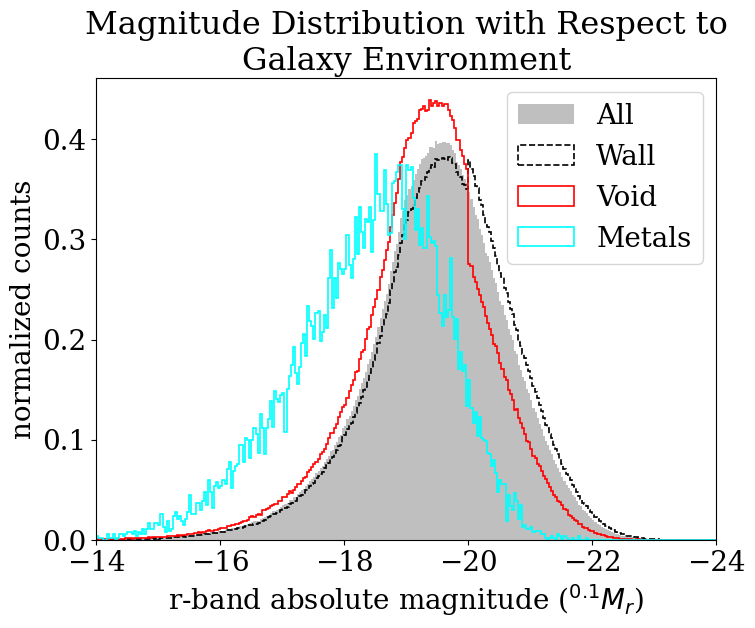

0.66697294 4612469
mean (all) 10.041768 0.0003105571132095504
mean (wall) 10.102845 0.00036919340426276094
mean (void) 9.903878 0.0005562320375966408
mean shift 0.19896698 0.0006676060585405417


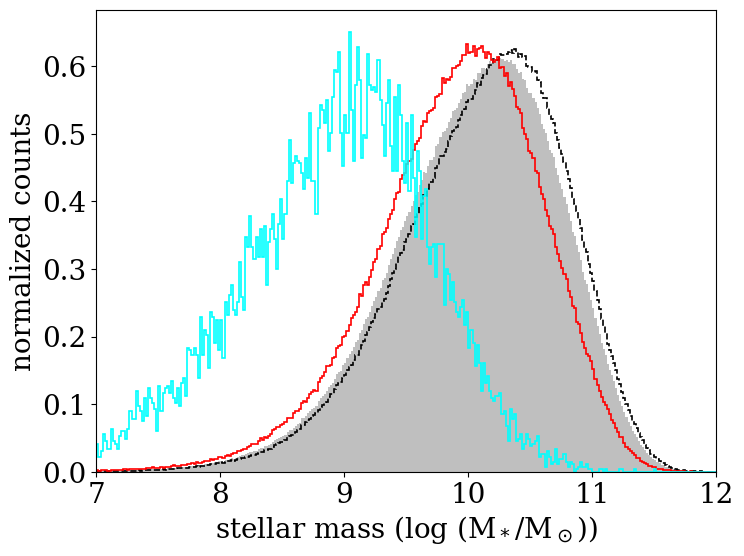

0.5179186 4612469
mean (all) 1.9613457 0.00024115416486063053
mean (wall) 2.0118093 0.0002882523823277678
mean (void) 1.8474219 0.0004247689548484284
mean shift 0.16438746 0.0005133401415442395


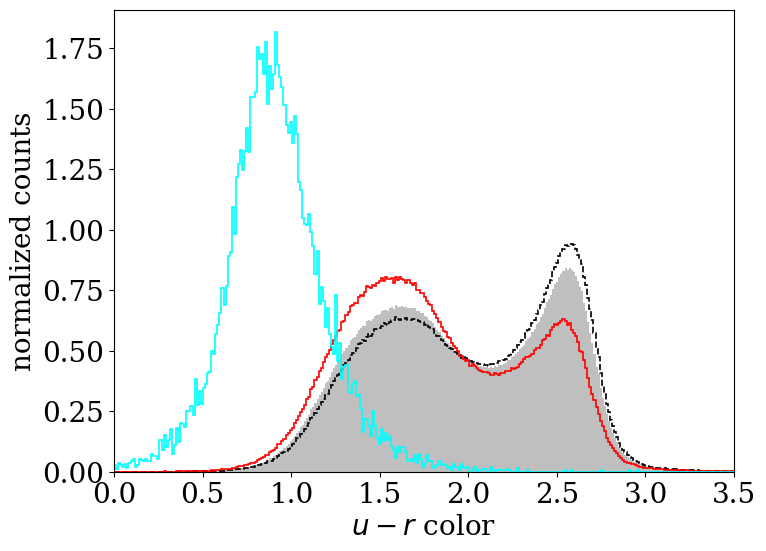

0.22136006 4612469
mean (all) 0.69139105 0.00010307006002455873
mean (wall) 0.7133712 0.00012241701267826056
mean (void) 0.64177024 0.0001839740016584455
mean shift 0.07160097 0.00022098044773076895


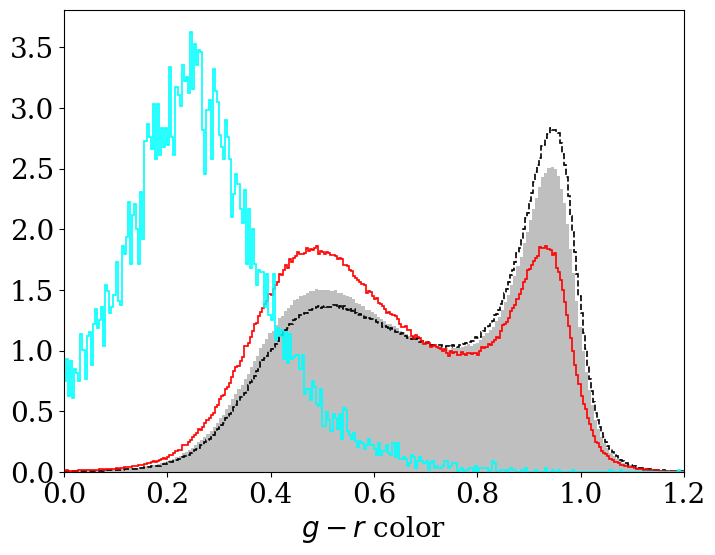

mean (all) 0.1745704 0.0013492176979882826
mean (wall) 0.0043859943 0.0017076622530447904
mean (void) 0.5581248 0.002075849625107348
mean shift -0.5537388 0.002687984753776019


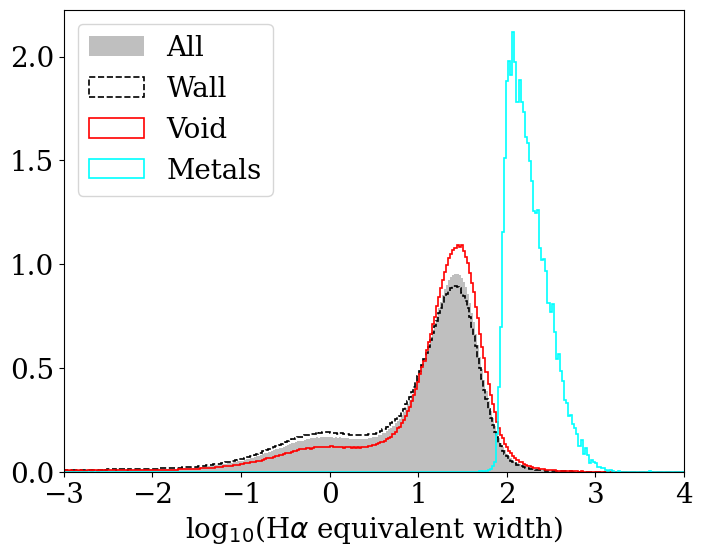

In [146]:
plot_properites_and_metals('BGS', 'VF')

1.2047677676825734 16105
mean (all) -18.384635457123846 0.009493426128062605
mean (wall) -18.426829329111733 0.012885161131405918
mean (void) -18.335921996889002 0.014016557997664363
mean shift -0.09090733222273073 0.019039203646271097


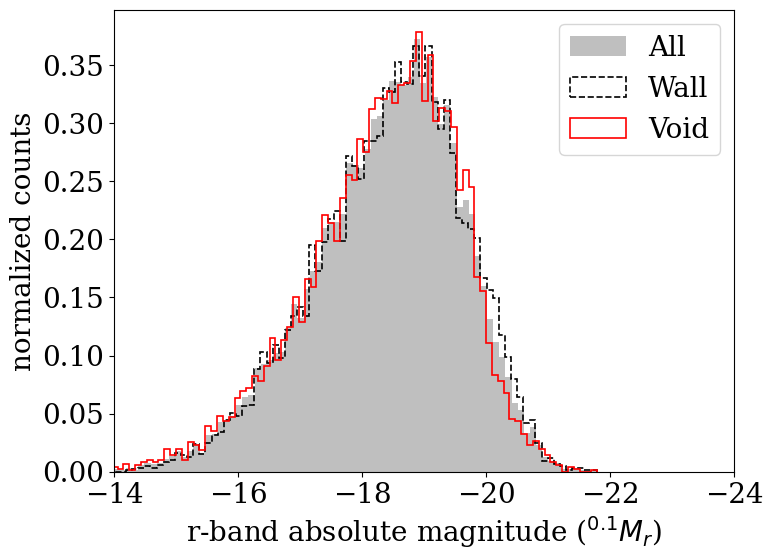

0.7563865 16105
mean (all) 8.921709 0.005960235432966055
mean (wall) 8.953327 0.008105096101738358
mean (void) 8.885208 0.008775384021322224
mean shift 0.06811905 0.011945708331450746


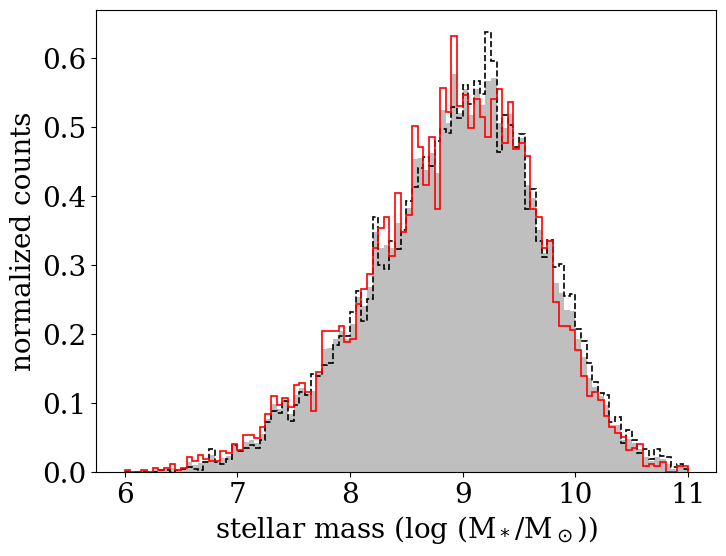

0.2868226 16105
mean (all) 0.91373205 0.0022601277333067567
mean (wall) 0.9193802 0.0031098441964286477
mean (void) 0.9072112 0.0032879343464864252
mean shift 0.0121690035 0.004525664944830324


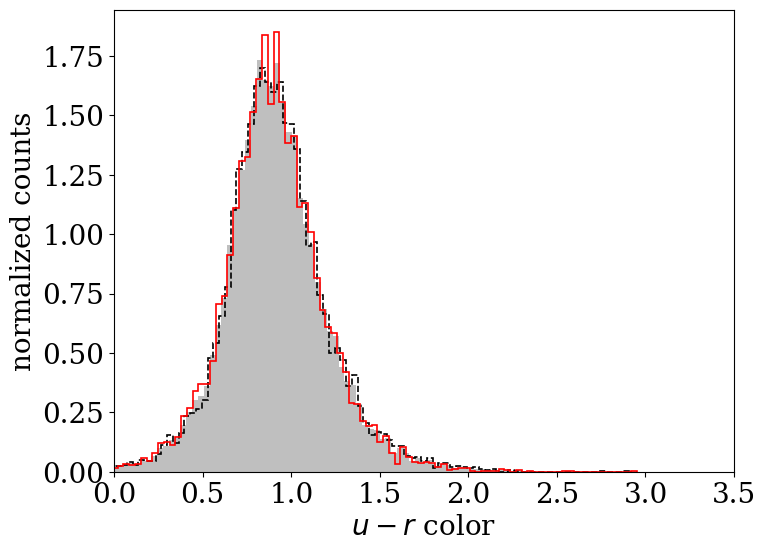

0.17922473 16105
mean (all) 0.22709614 0.00141226946456535
mean (wall) 0.23017403 0.0019347581906814365
mean (void) 0.22354263 0.0020653717415131246
mean shift 0.006631404 0.0028300264463516703


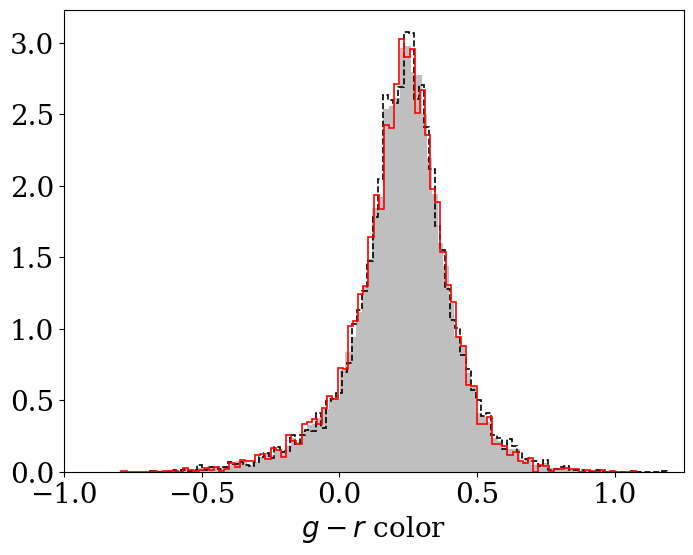

mean (all) 2.2517521 0.0017909590143858456
mean (wall) 2.2466729 0.0024222383928411365
mean (void) 2.2576158 0.0026570817060489397
mean shift -0.010942936 0.0035954585276948415


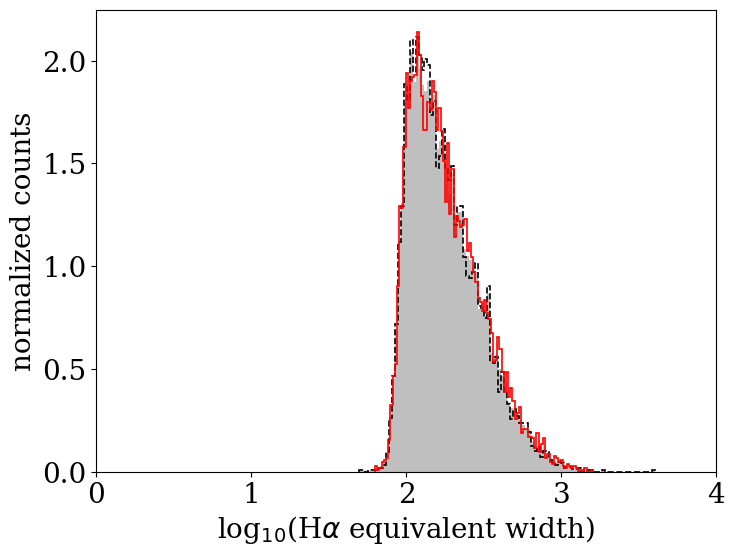

In [44]:
plot_properites_metals('BGS', 'VF')

1.1111151749179142 4612469
mean (all) -19.48461384478667 0.0005173594053895095
mean (wall) -19.579430431700874 0.0006242462120874275
mean (void) -19.270566349695862 0.0008986625778369614
mean shift -0.30886408200501236 0.001094201883616581


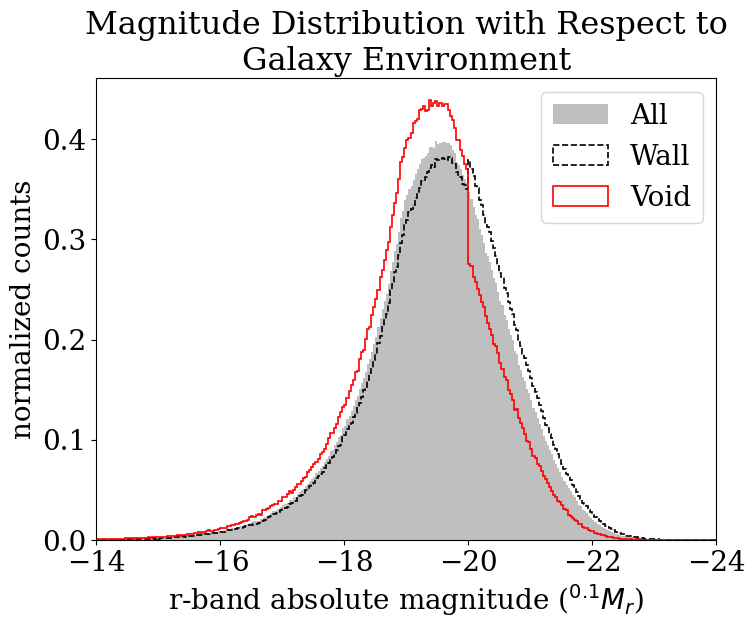

0.66697294 4612469
mean (all) 10.041768 0.0003105571132095504
mean (wall) 10.102845 0.00036919340426276094
mean (void) 9.903878 0.0005562320375966408
mean shift 0.19896698 0.0006676060585405417


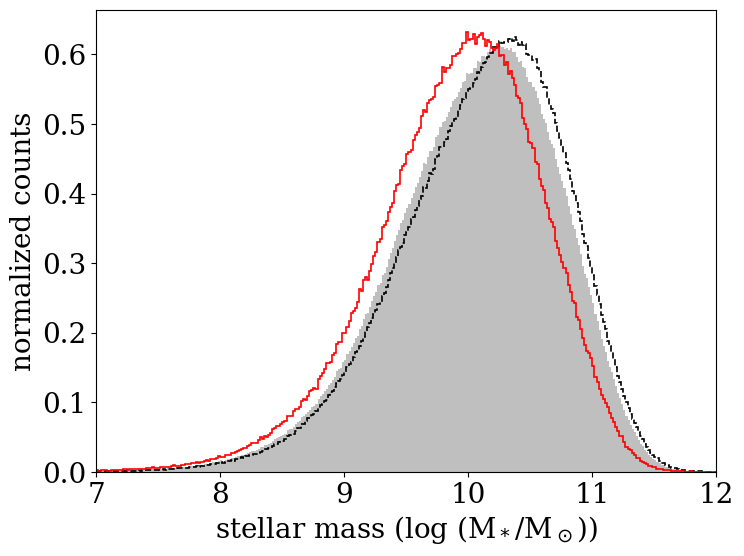

0.5179186 4612469
mean (all) 1.9613457 0.00024115416486063053
mean (wall) 2.0118093 0.0002882523823277678
mean (void) 1.8474219 0.0004247689548484284
mean shift 0.16438746 0.0005133401415442395


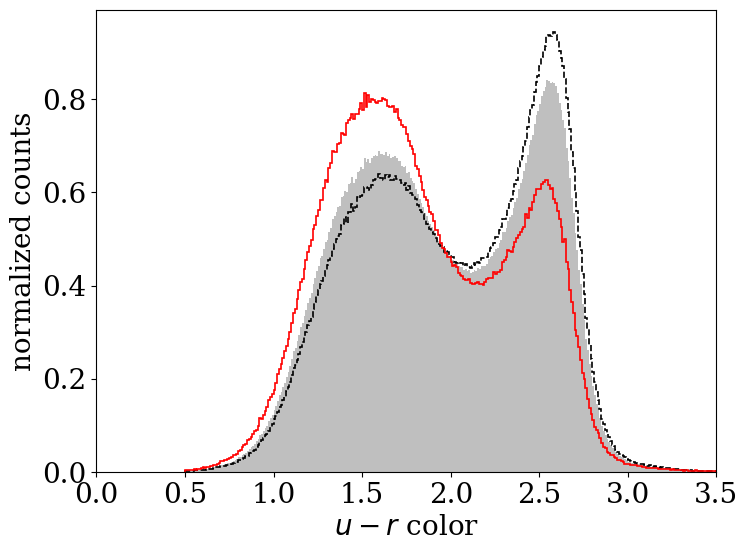

0.22136006 4612469
mean (all) 0.69139105 0.00010307006002455873
mean (wall) 0.7133712 0.00012241701267826056
mean (void) 0.64177024 0.0001839740016584455
mean shift 0.07160097 0.00022098044773076895


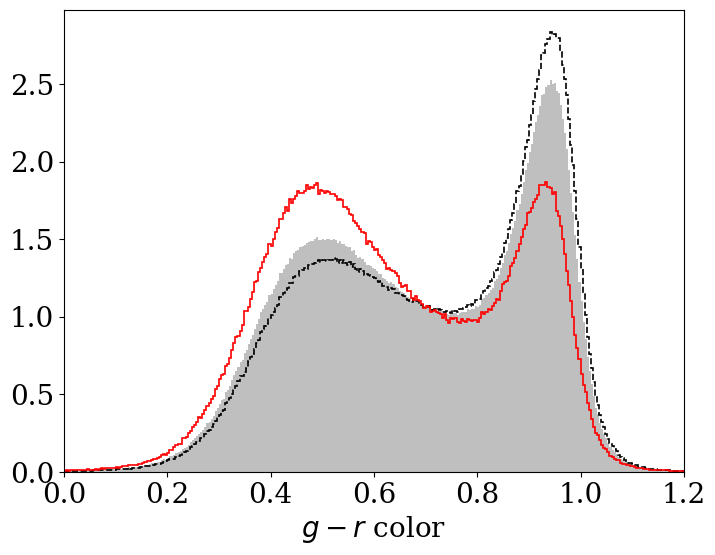

mean (all) 0.1745704 0.0013492176979882826
mean (wall) 0.0043859943 0.0017076622530447904
mean (void) 0.5581248 0.002075849625107348
mean shift -0.5537388 0.002687984753776019


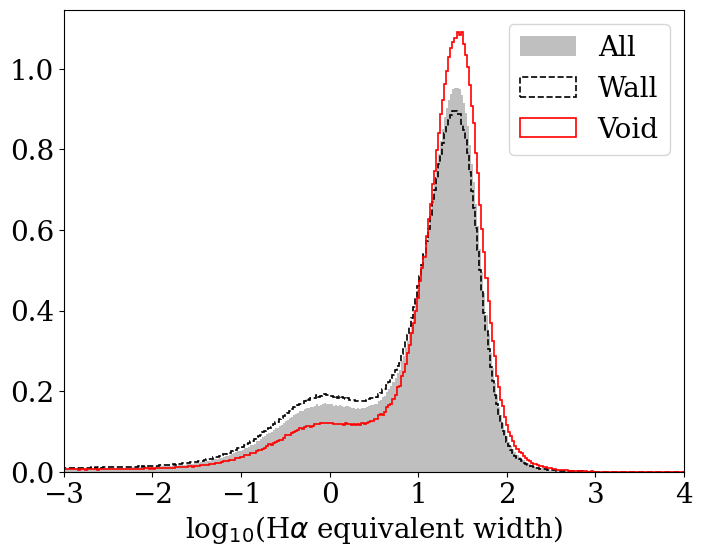

mean (all) 8.250674786106455 0.0019374649347446721
mean (wall) 8.25882953472563 0.0026380901422544695
mean (void) 8.241241819465598 0.002850702538827506
mean shift 0.017587715260031445 0.0038840731923507565


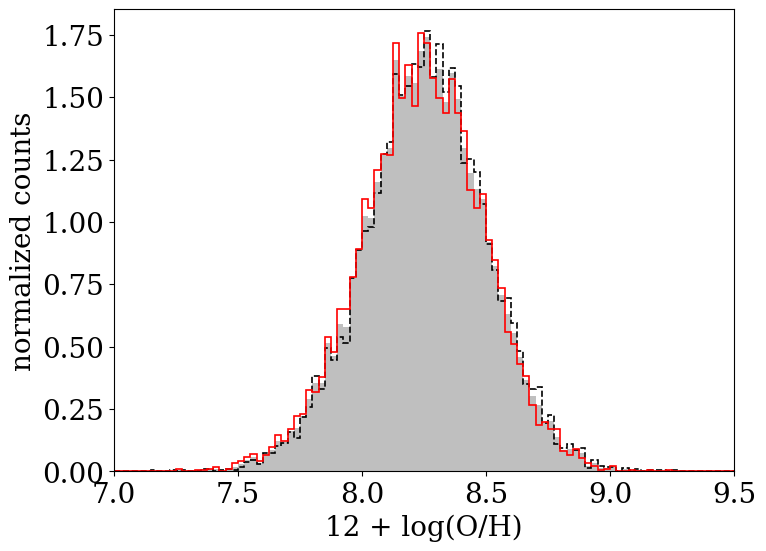

mean (all) -13.235906482528785 0.0017757554180375253
mean (wall) -13.227615807980397 0.002448096823886368
mean (void) -13.245496680841114 0.0025740436681552874
mean shift 0.017880872860716934 0.003552306133301696


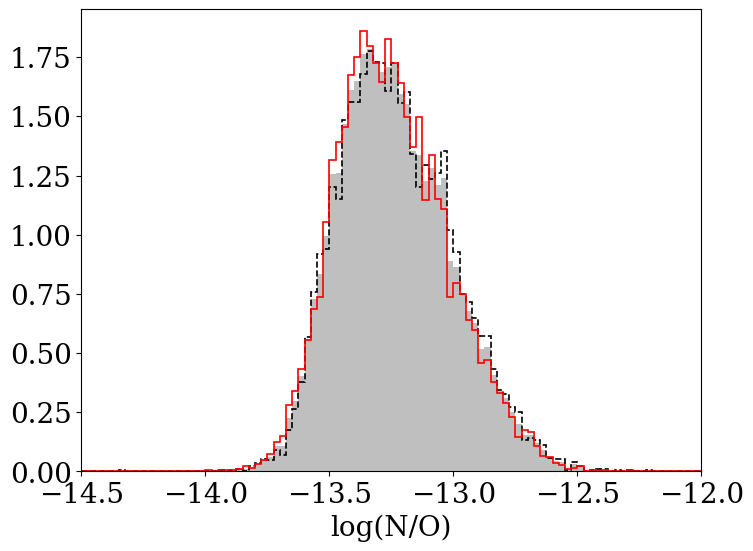

In [134]:
plot_properites('BGS', 'VF')

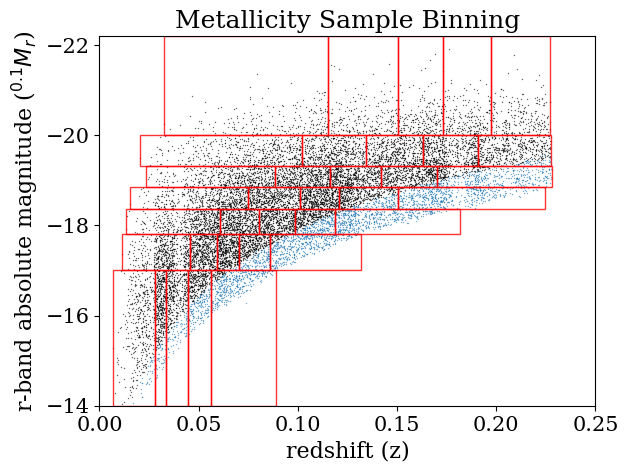

In [176]:
check_sample_binning(heatmap_mr_bins_metal, metallicity=True)
#plt.plot(plot_redshift_range, bgs_bright_range, alpha = 0.5)
#plt.plot(plot_redshift_range, bgs_faint_range, alpha = 0.5)

plt.title('Metallicity Sample Binning', fontsize = 18)
plt.ylabel('r-band absolute magnitude ($^{0.1}M_r$)')
plt.xlabel('redshift (z)')
plt.gca().tick_params(labelsize=15)
plt.xlim(0,0.25);
plt.savefig("/global/homes/h/hrincon/galaxy_environment/images/mag_redshift_metal.png", bbox_inches = "tight", dpi=400)

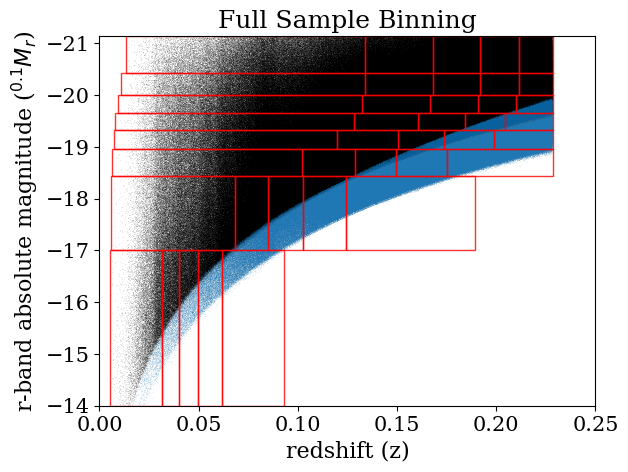

In [111]:
check_sample_binning(heatmap_mr_bins)
#plt.plot(plot_redshift_range, bgs_bright_range, alpha = 0.5)
#plt.plot(plot_redshift_range, bgs_faint_range, alpha = 0.5)

plt.title('Full Sample Binning', fontsize = 18)
plt.ylabel('r-band absolute magnitude ($^{0.1}M_r$)')
plt.xlabel('redshift (z)')
plt.gca().tick_params(labelsize=15)
plt.xlim(0,0.25);
plt.savefig("/global/homes/h/hrincon/galaxy_environment/images/mag_redshift.png", bbox_inches = "tight", dpi=400)

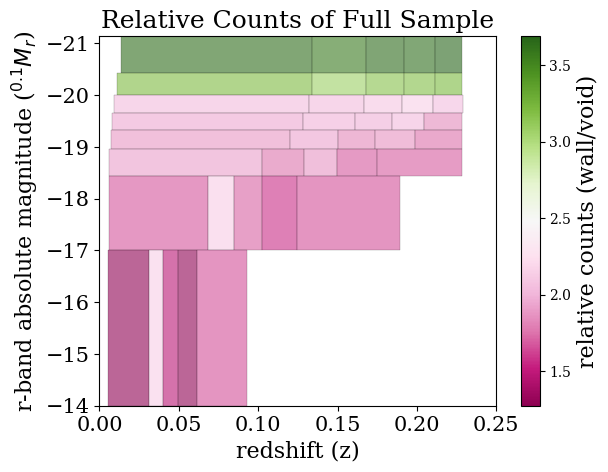

In [133]:
#Plot Relative counts 
plot_relative_counts(heatmap_mr_bins)
plt.title('Relative Counts of Full Sample', fontsize = 18)
plt.savefig("/global/homes/h/hrincon/galaxy_environment/images/relative_counts.pdf", bbox_inches = "tight", dpi=400)

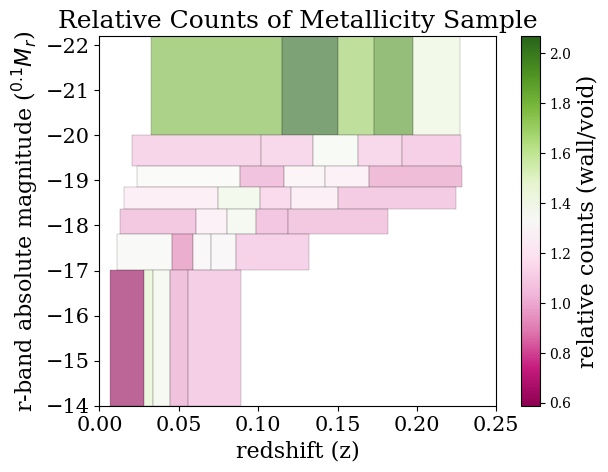

In [177]:
#Plot Relative counts 
plot_relative_counts(heatmap_mr_bins_metal, metallicity=True)
plt.title('Relative Counts of Metallicity Sample', fontsize = 18)
plt.savefig("/global/homes/h/hrincon/galaxy_environment/images/relative_counts_metal.pdf", bbox_inches = "tight", dpi=400)

# Color-Magnitude Distributions

In [79]:
all_mr = get_property('mr', 'VF', 'all', 'BGS', False)

In [80]:
all_gr = get_property('g-r', 'VF', 'all', 'BGS', False)

In [102]:
all_z = get_property('redshift', 'VF', 'all', 'BGS', False)

(-10.0, -30.0)

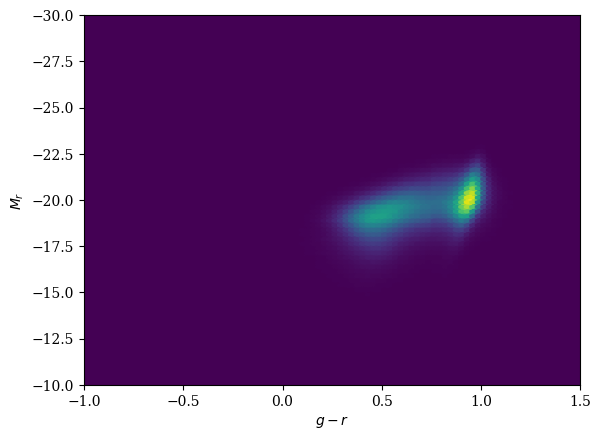

In [101]:
plt.hexbin(all_gr, all_mr, gridsize=(90,80),
          extent=(-1,1.5,-10,-30)
          )
plt.xlabel('$g-r$')
plt.ylabel('$M_r$')
#plt.gca().invert_yaxis()
plt.xlim(-1,1.5)
plt.ylim(-10,-30)

(-10.0, -30.0)

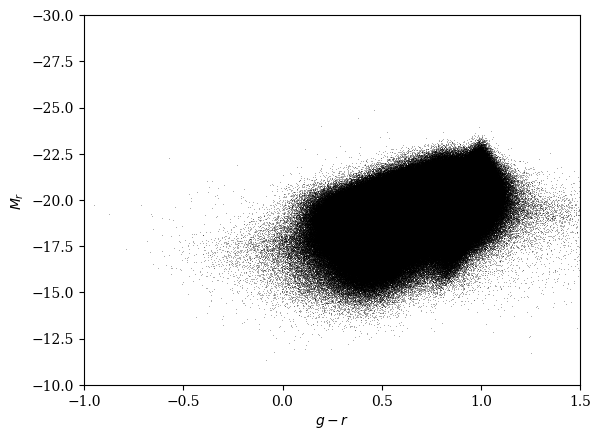

In [93]:
plt.scatter(all_gr, all_mr, color= 'k', s=.1, linewidth=.1)
plt.xlabel('$g-r$')
plt.ylabel('$M_r$')
#plt.gca().invert_yaxis()
plt.xlim(-1,1.5)
plt.ylim(-10,-30)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


[(-0.25, 1.5)]

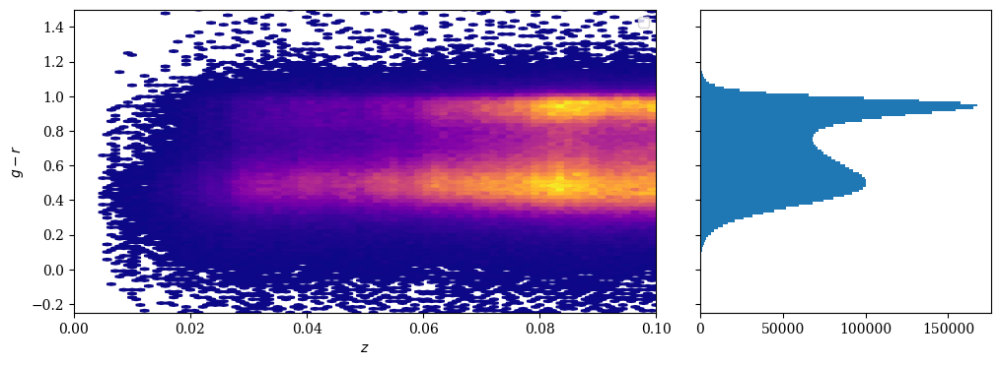

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(12,4), sharey=True, gridspec_kw={'width_ratios':[2,1], 'wspace':0.1})

ax = axes[0]
ax.hexbin(all_z, all_gr,cmap='plasma',mincnt=1,gridsize=(70,80),extent=(0,0.1, -0.25, 1.5),zorder=2)
ax.set(xlim=(0,0.1), ylim=(-0.25,1.5),
       xlabel='$z$', ylabel=r'$g-r$')
ax.legend(loc='upper right')

ax = axes[1]
ax.hist(all_gr, bins=500, orientation='horizontal')
ax.set(ylim=(-0.25,1.5))

(-0.25, 1.5)

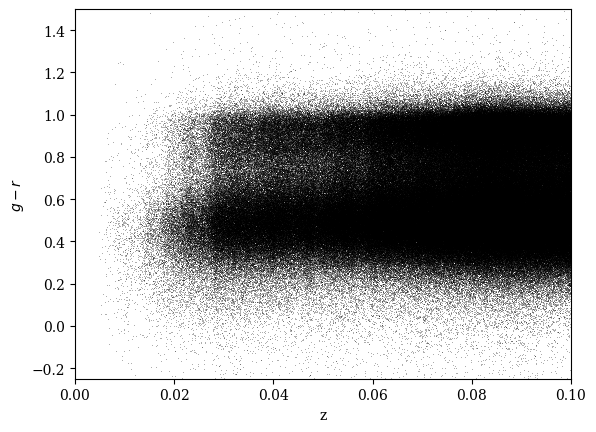

In [105]:
plt.scatter(all_z, all_gr, color= 'k', s=.1, linewidth=.1)
plt.ylabel('$g-r$')
plt.xlabel('z')
#plt.gca().invert_yaxis()
plt.xlim(0,.1)
plt.ylim(-.25,1.5)

# Redshift evolution of distributions (using heatmap bins)

M_r range: -21.138253063379075 -20.43024595282527


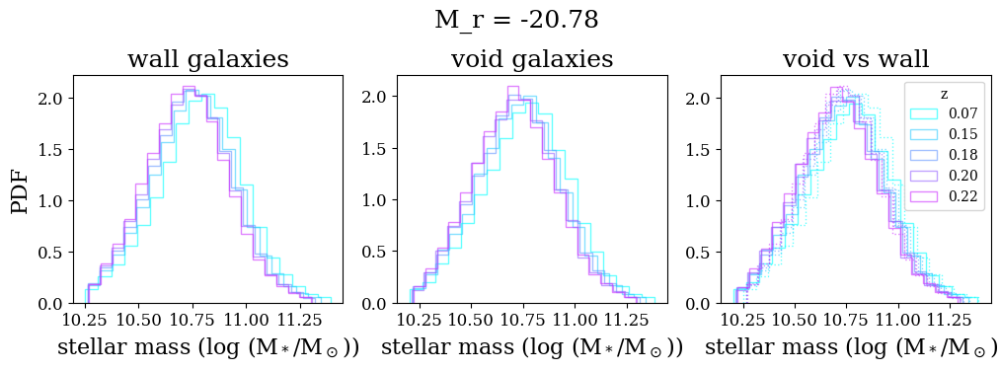

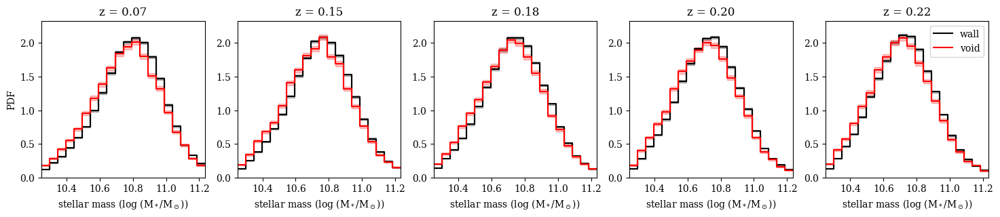

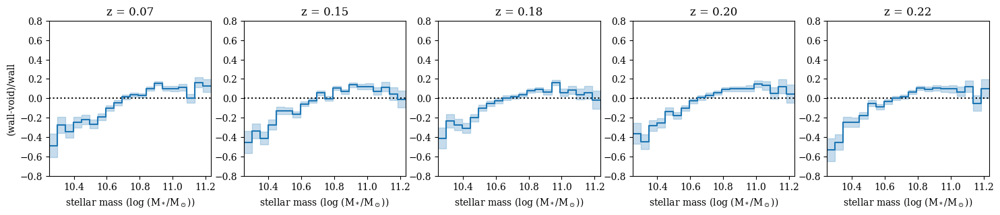

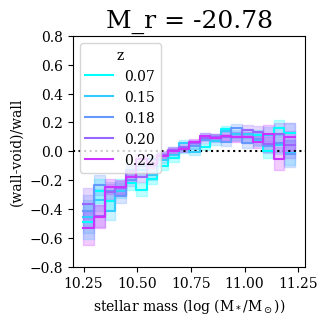

M_r range: -20.43024595282527 -19.999999395161154


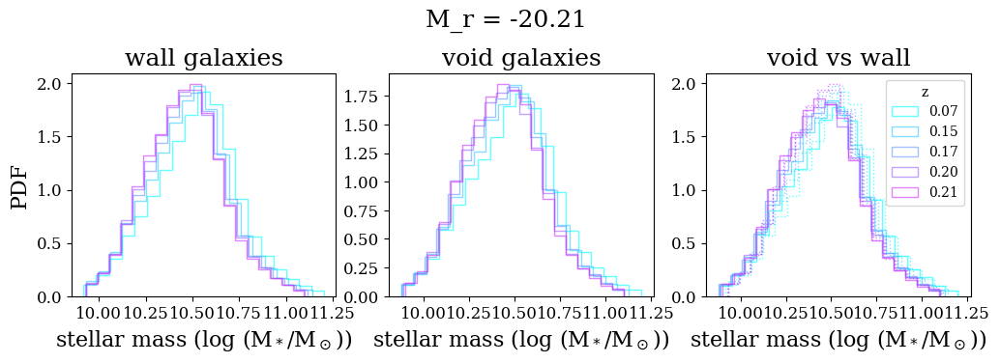

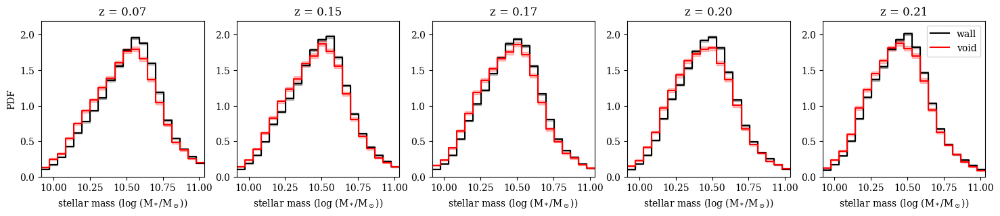

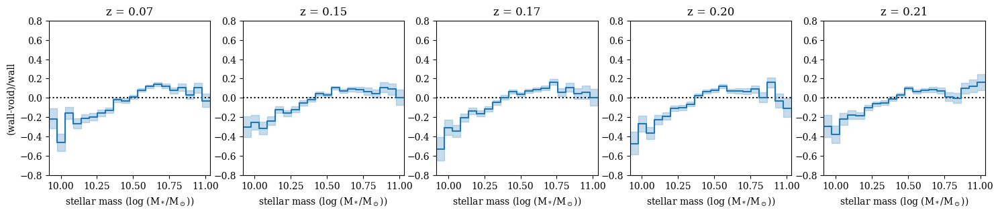

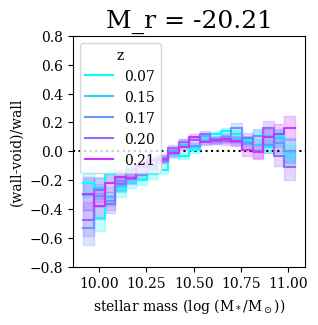

M_r range: -19.999999395161154 -19.653073251916755


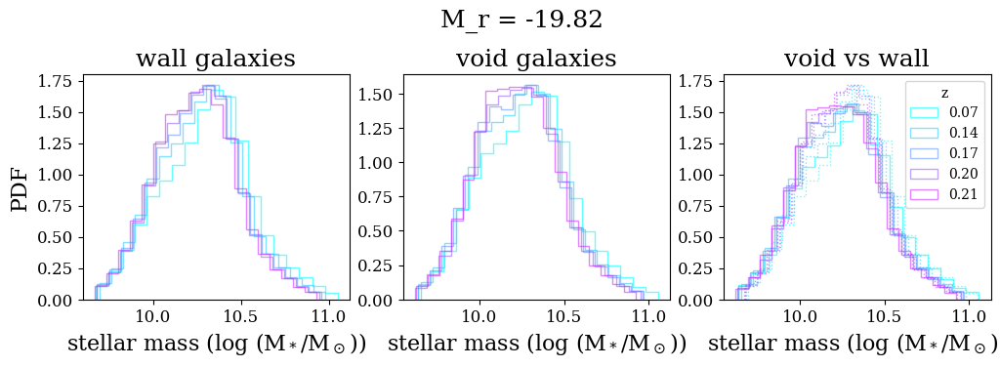

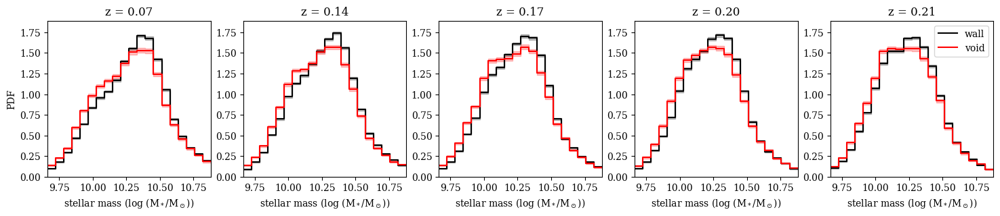

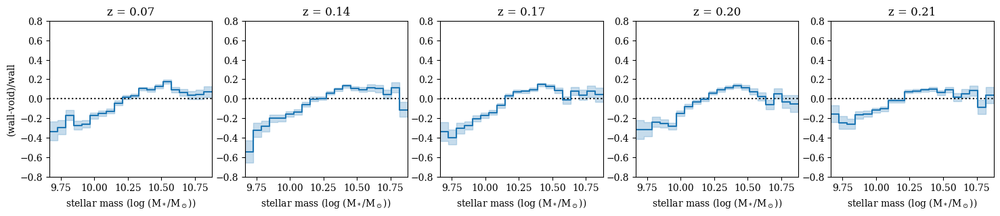

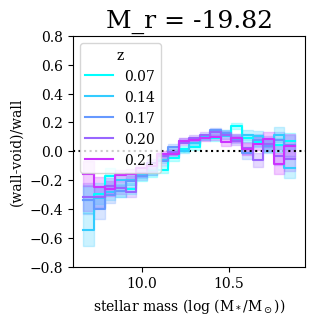

M_r range: -19.653073251916755 -19.32015170512863


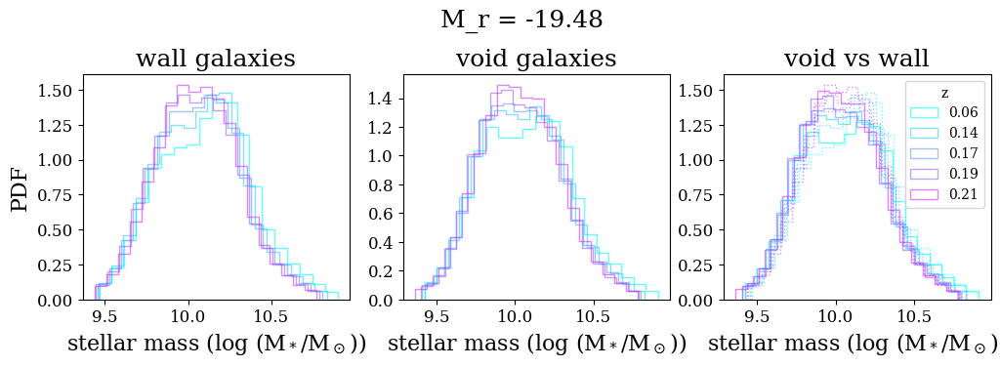

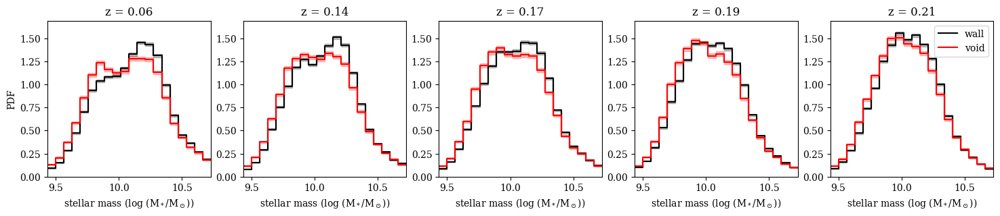

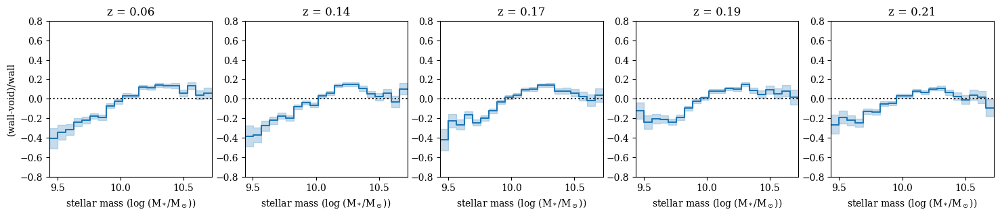

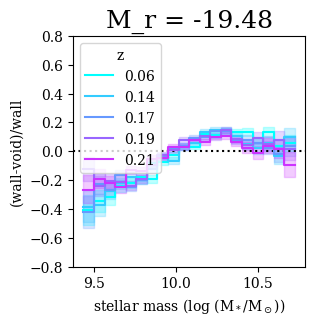

M_r range: -19.32015170512863 -18.958444056318076


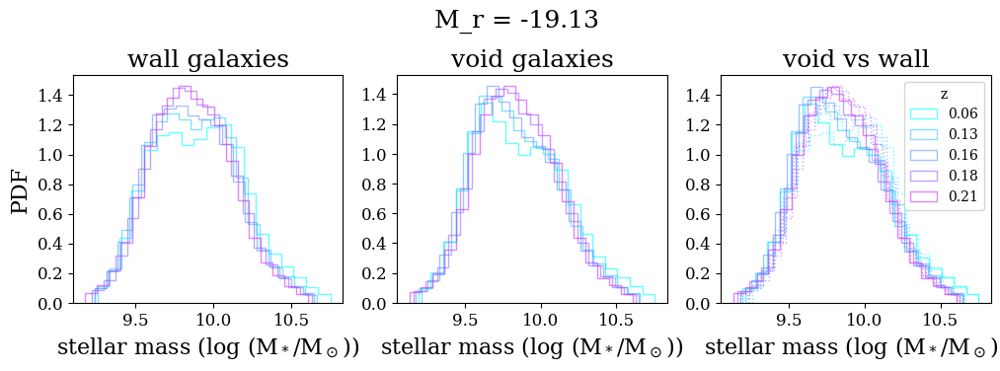

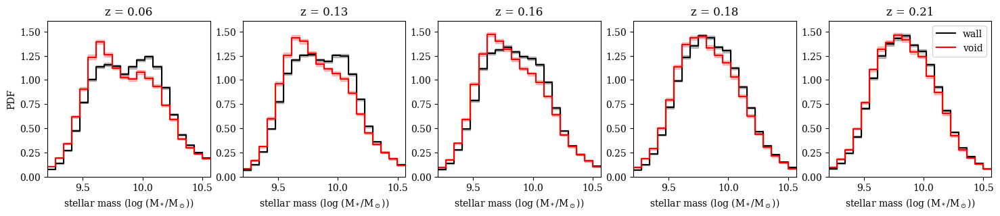

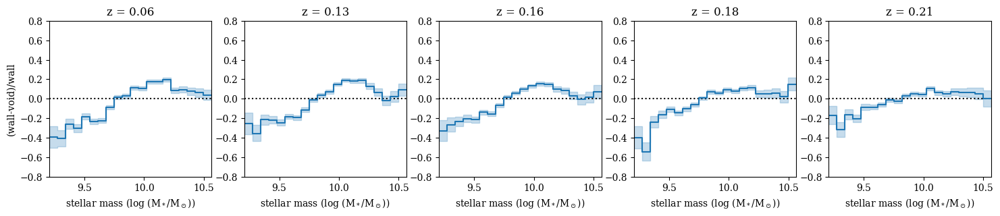

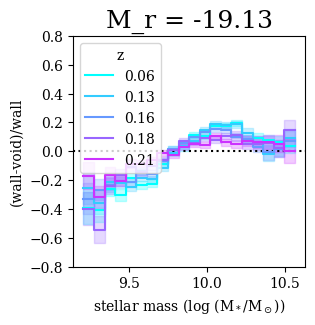

M_r range: -18.958444056318076 -18.444934235837245


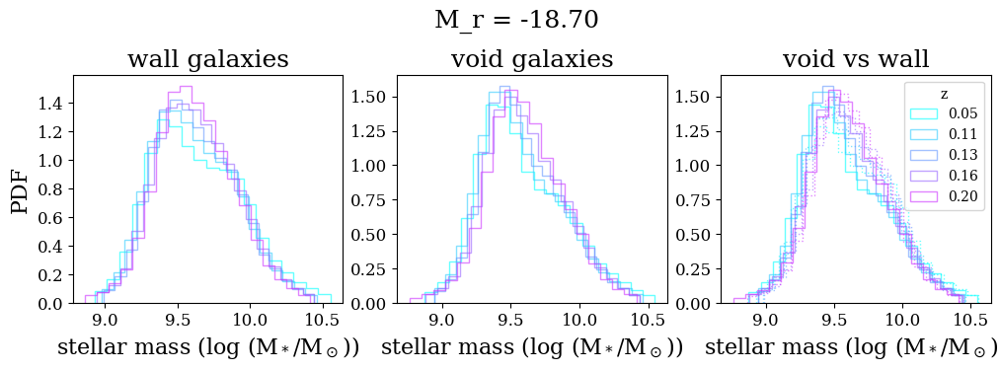

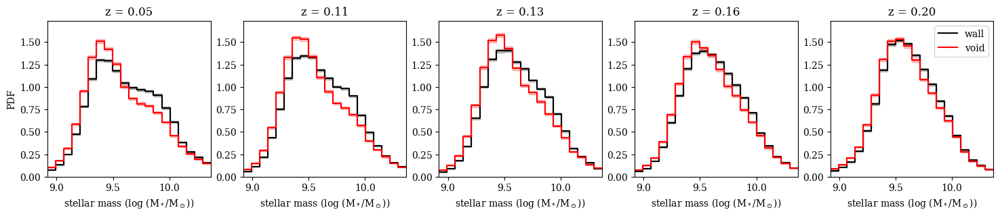

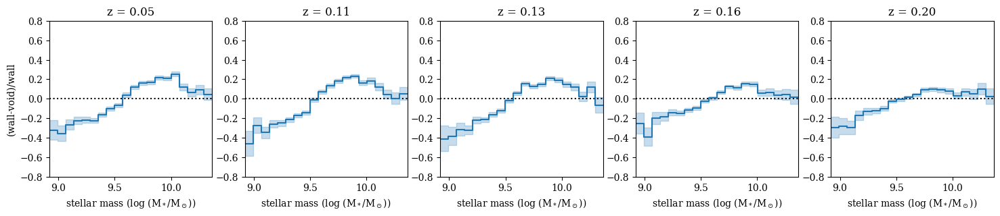

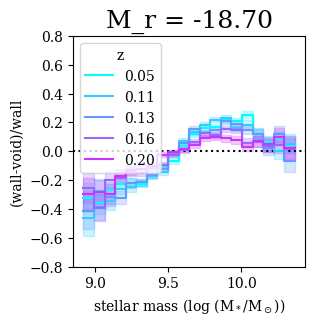

M_r range: -18.444934235837245 -17.000000820855885


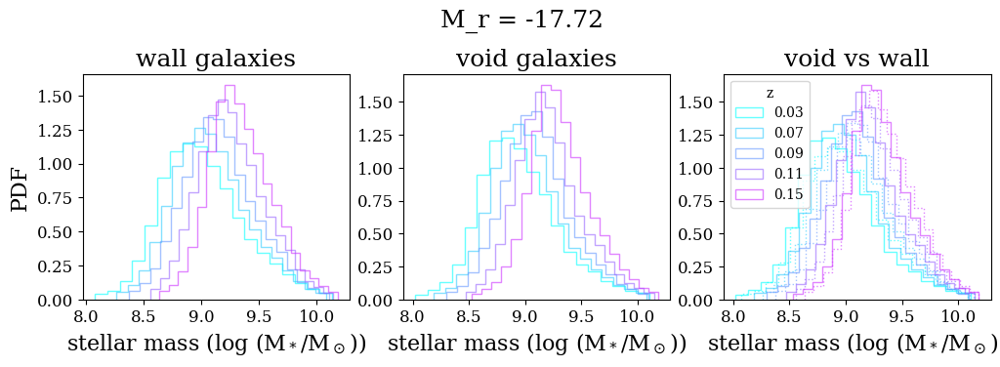

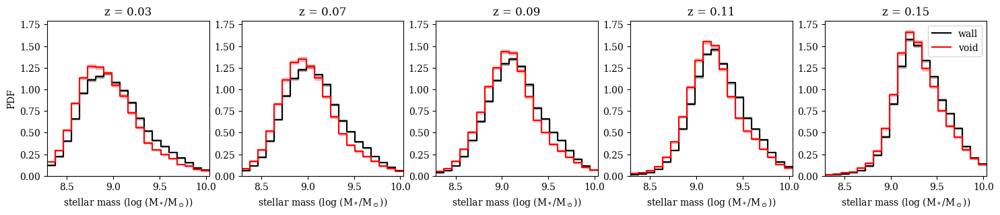

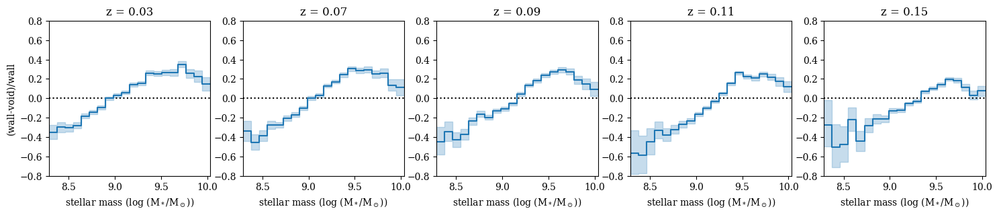

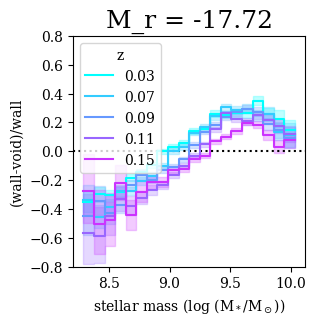

M_r range: -17.000000820855885 -14.0


/tmp/ipykernel_1488155/3265995933.py:145: RuntimeWarning: divide by zero encountered in true_divide
  res = (res_wall - res_void)/res_wall
/tmp/ipykernel_1488155/3265995933.py:151: RuntimeWarning: divide by zero encountered in true_divide
  delta_res_err_low = (res_void[1:]/res_wall[1:])*np.sqrt((delta_wall_err_low/res_wall[1:])**2 + (delta_void_err_low/res_void[1:])**2)
/tmp/ipykernel_1488155/3265995933.py:153: RuntimeWarning: divide by zero encountered in true_divide
  delta_res_err_high = (res_void[1:]/res_wall[1:])*np.sqrt((delta_wall_err_high/res_wall[1:])**2 + (delta_void_err_high/res_void[1:])**2)
/tmp/ipykernel_1488155/3265995933.py:154: RuntimeWarning: invalid value encountered in add
  res_err_high = res[1:] + delta_res_err_high
/tmp/ipykernel_1488155/3265995933.py:145: RuntimeWarning: invalid value encountered in true_divide
  res = (res_wall - res_void)/res_wall
/tmp/ipykernel_1488155/3265995933.py:151: RuntimeWarning: invalid value encountered in true_divide
  delta_res_er

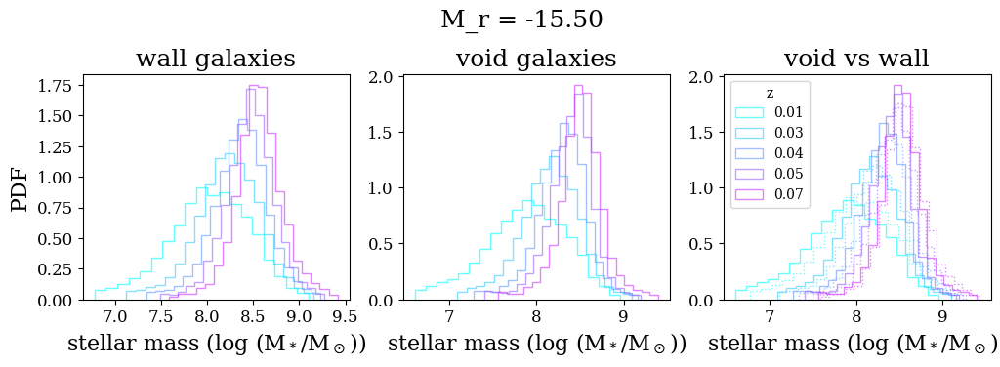

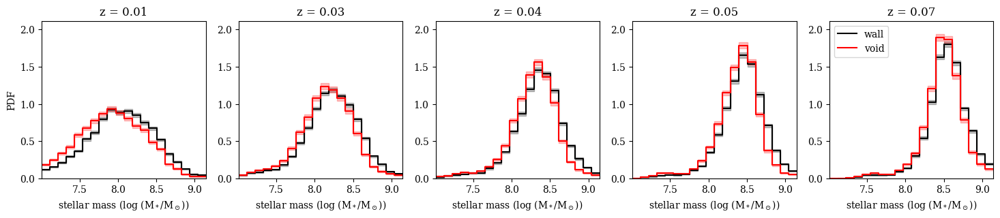

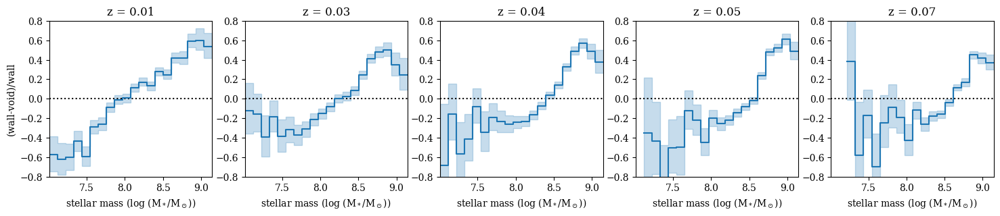

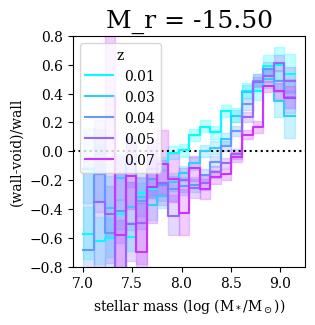

M_r range: -21.138253063379075 -20.43024595282527


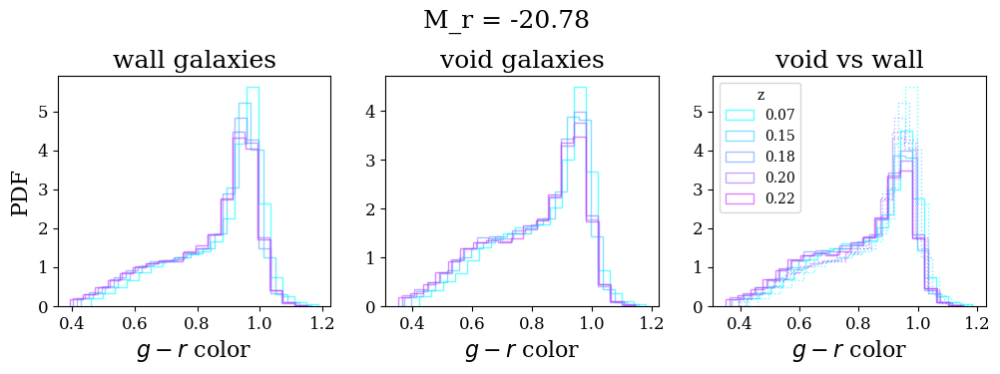

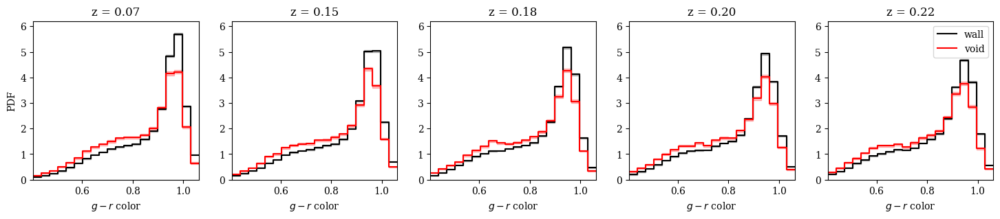

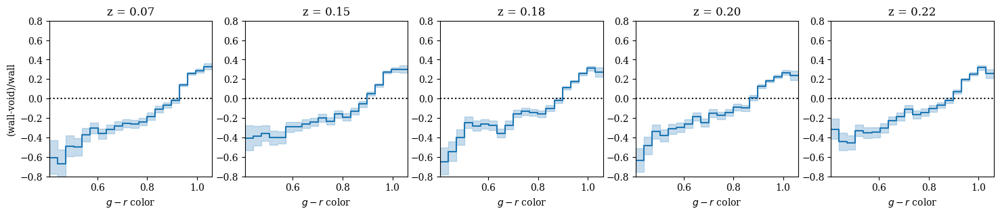

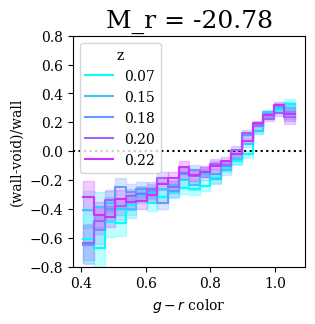

M_r range: -20.43024595282527 -19.999999395161154


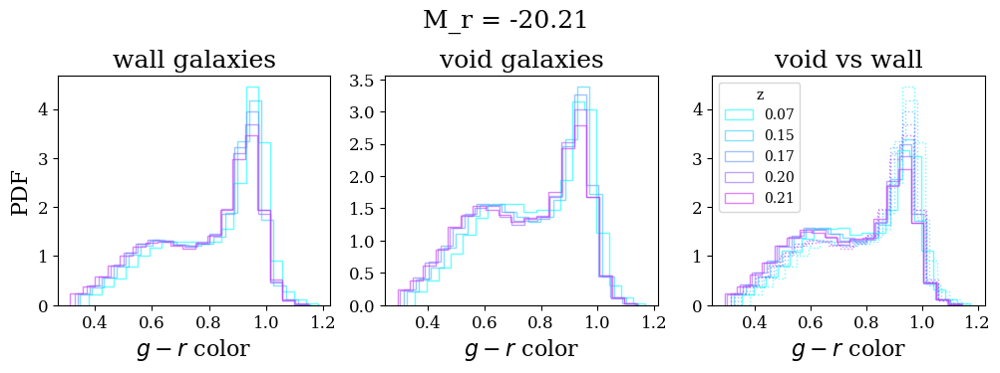

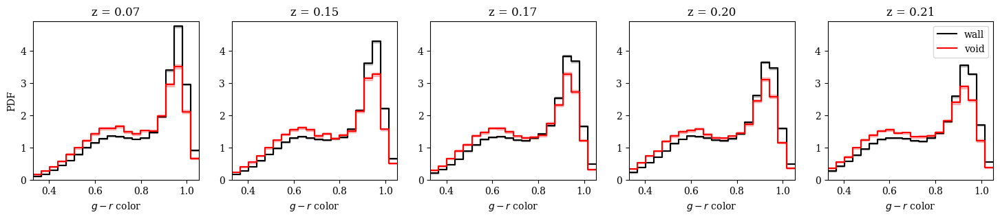

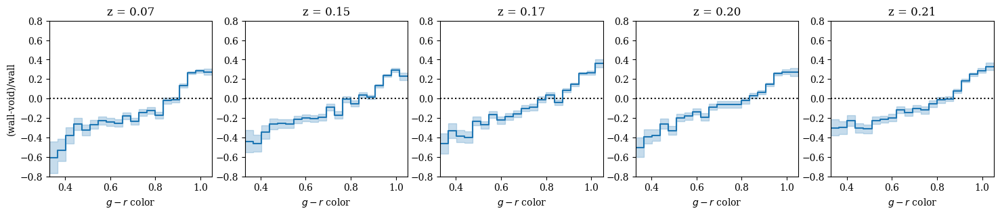

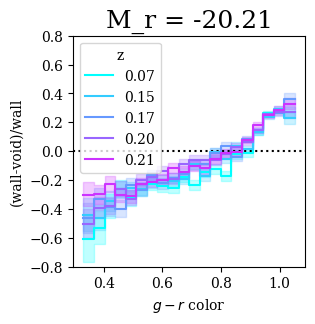

M_r range: -19.999999395161154 -19.653073251916755


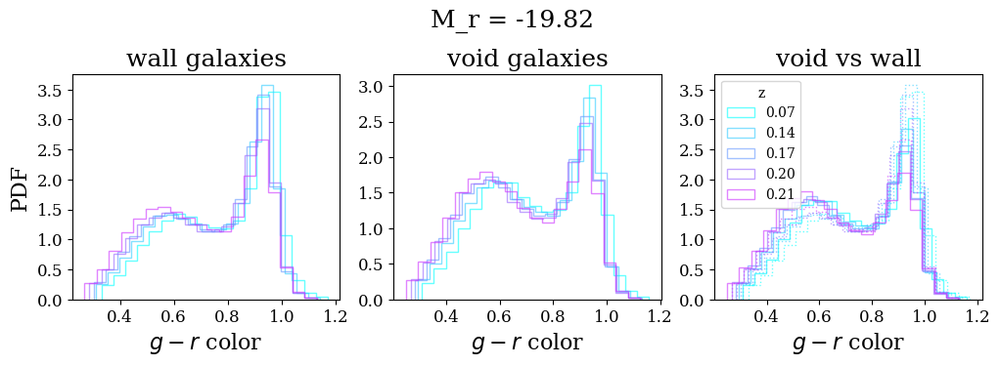

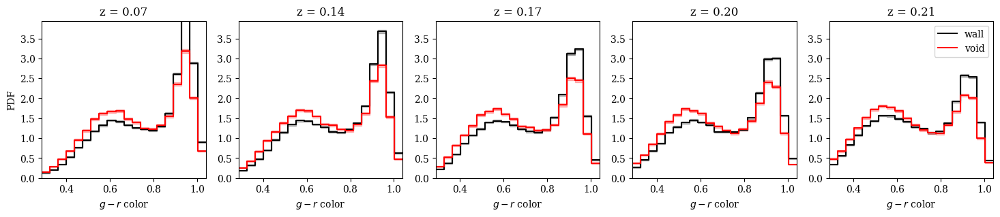

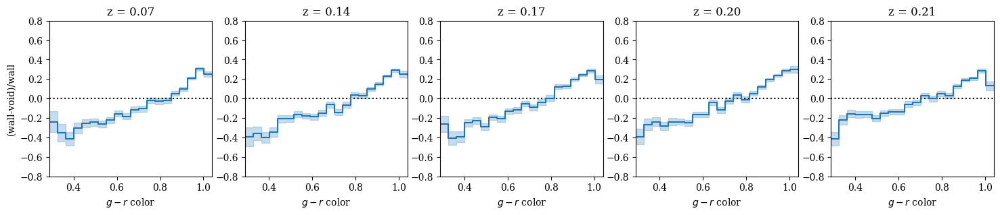

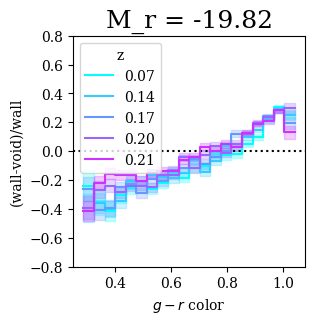

M_r range: -19.653073251916755 -19.32015170512863


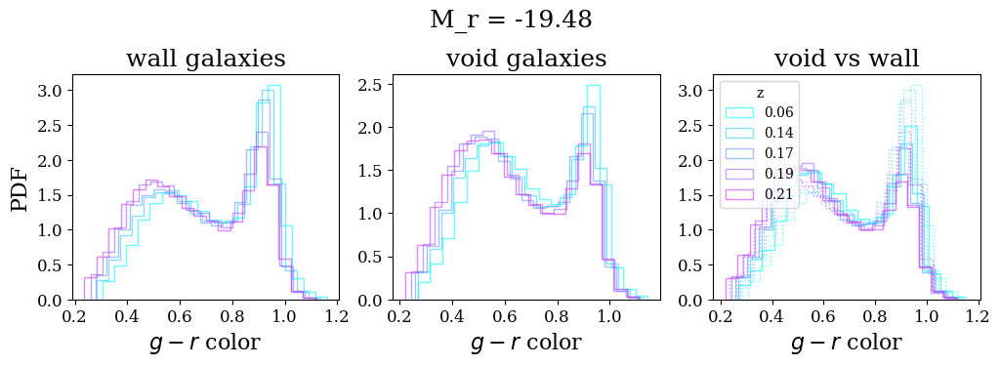

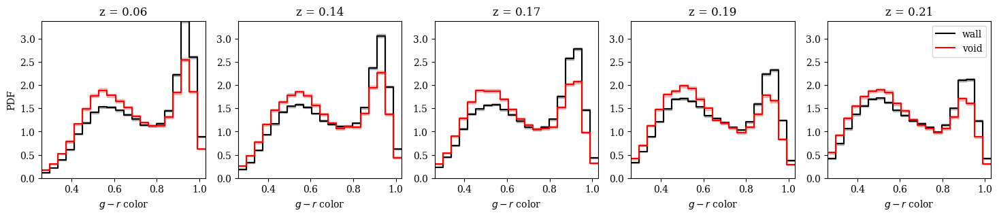

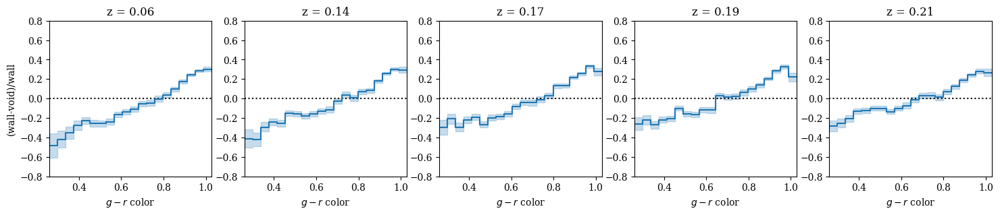

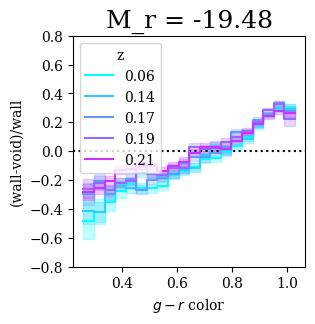

M_r range: -19.32015170512863 -18.958444056318076


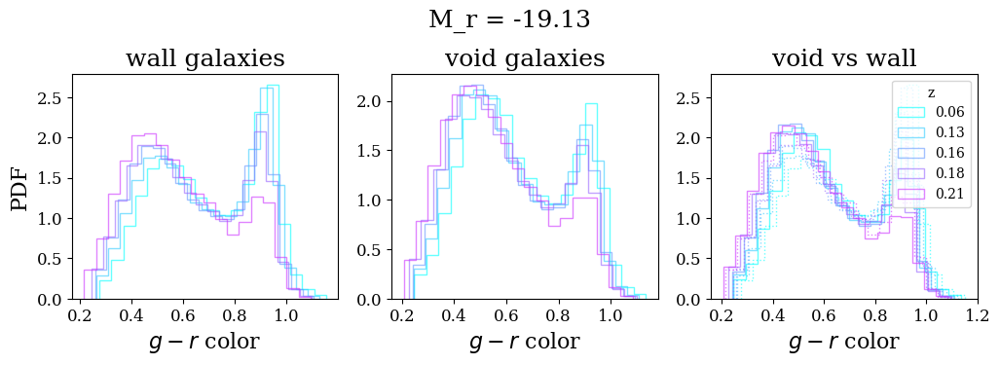

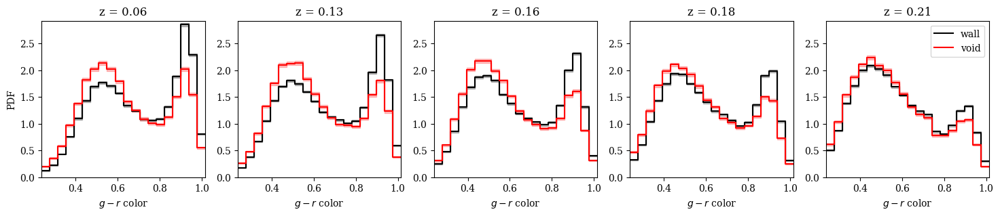

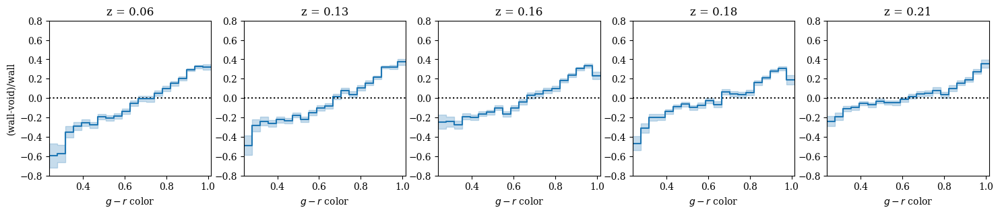

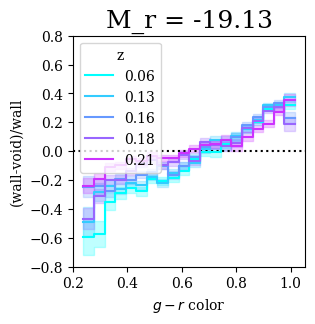

M_r range: -18.958444056318076 -18.444934235837245


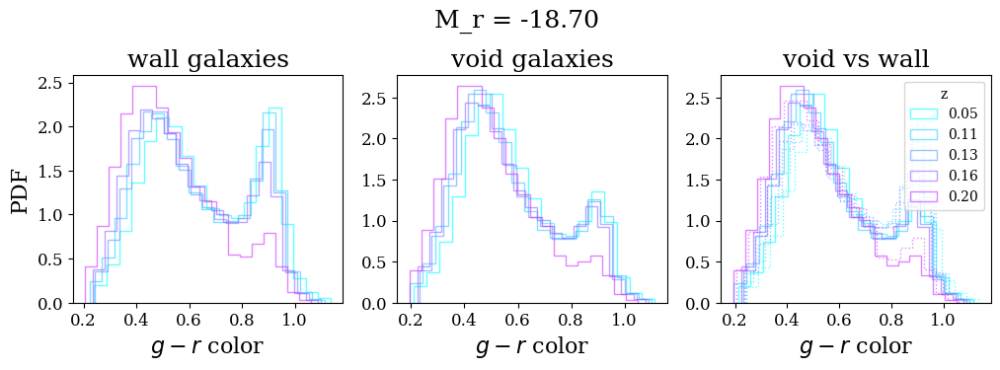

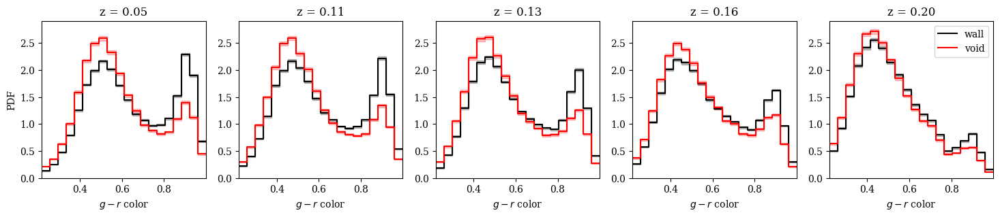

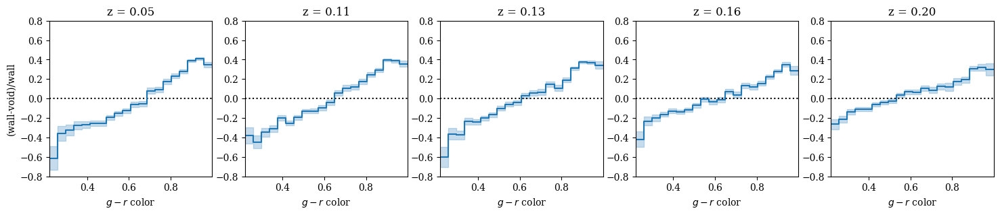

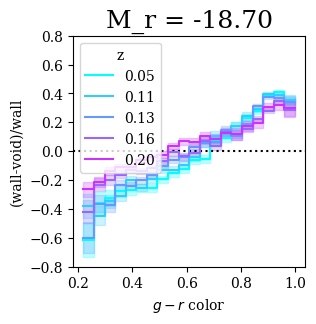

M_r range: -18.444934235837245 -17.000000820855885


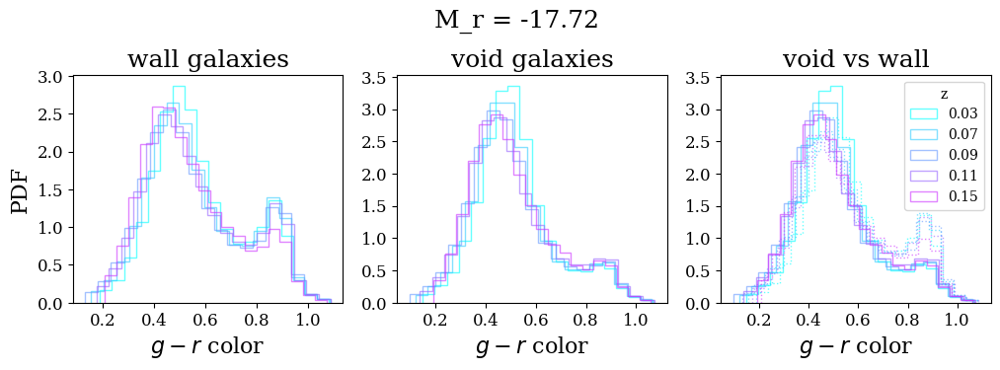

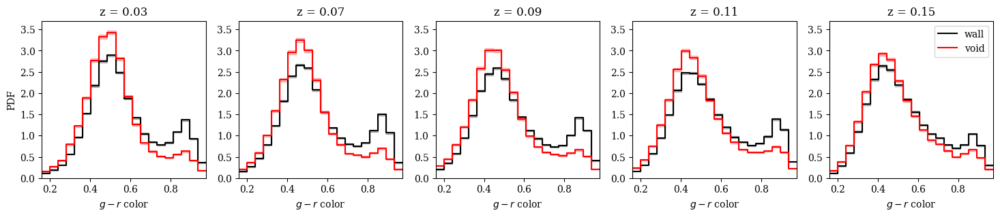

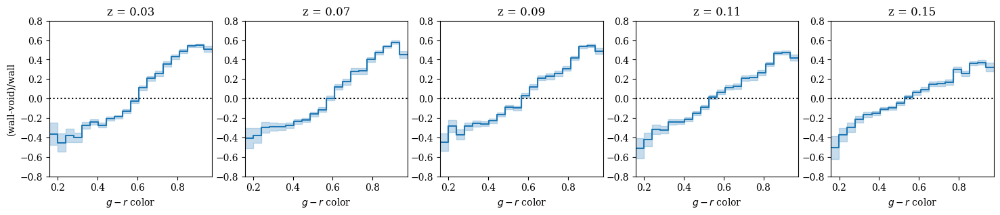

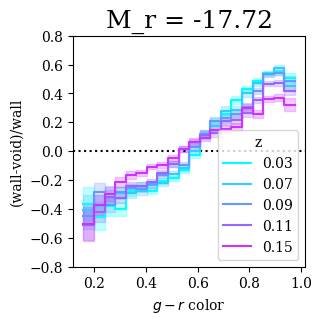

M_r range: -17.000000820855885 -14.0


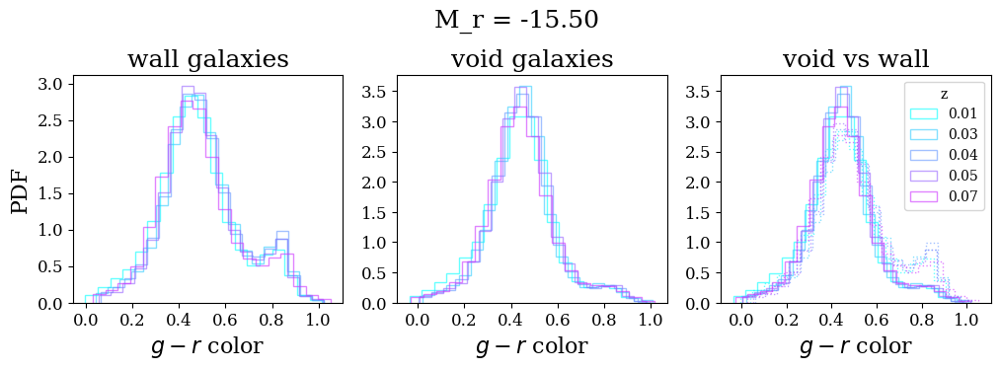

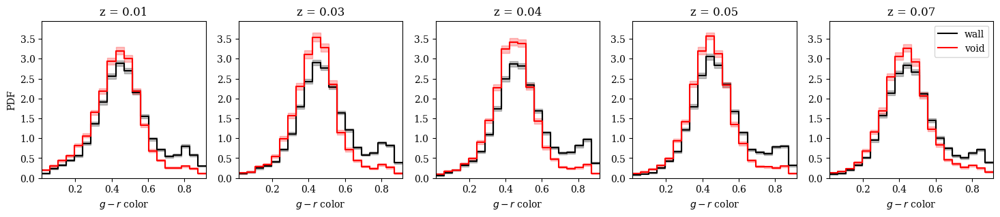

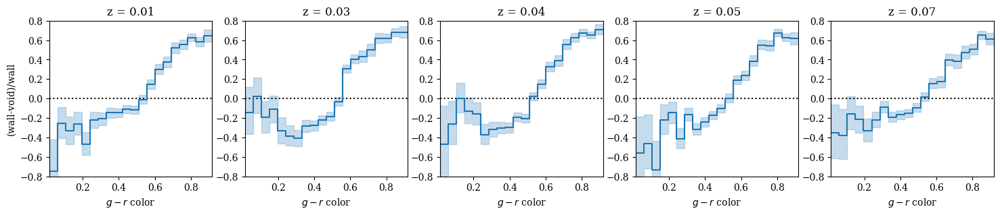

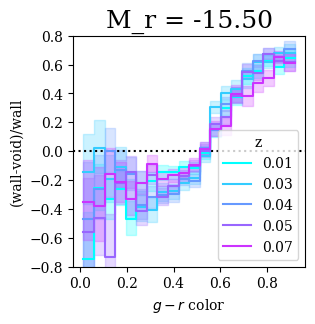

M_r range: -21.138253063379075 -20.43024595282527


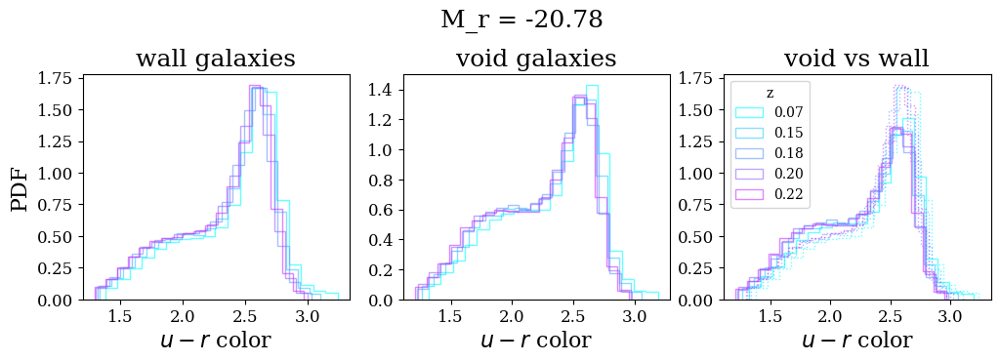

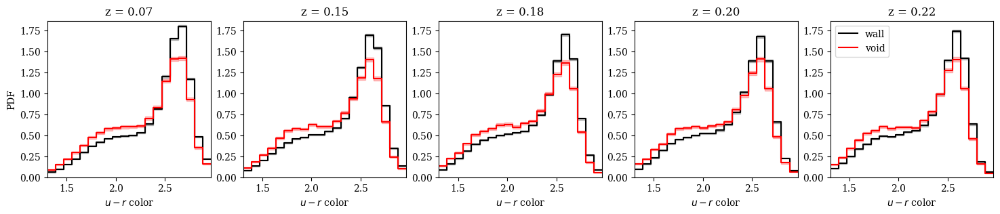

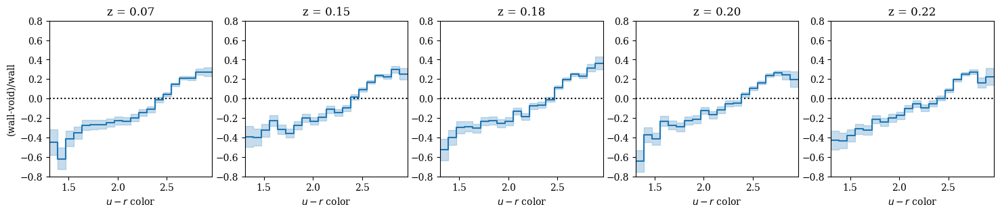

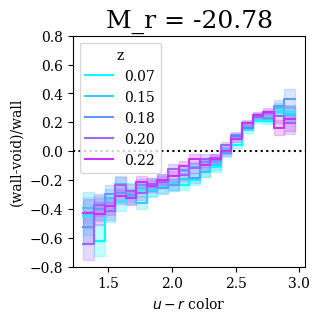

M_r range: -20.43024595282527 -19.999999395161154


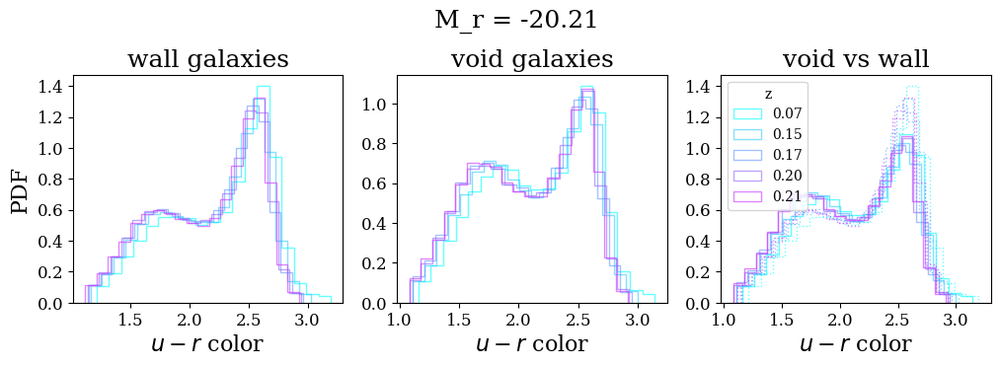

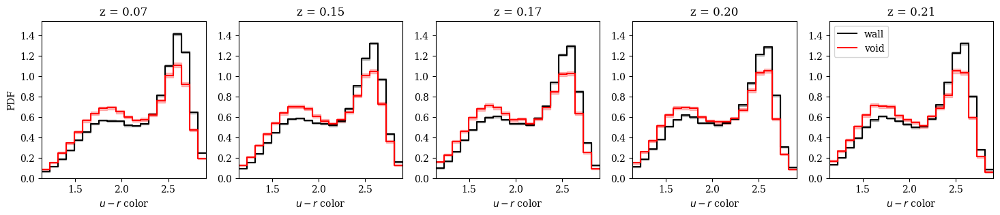

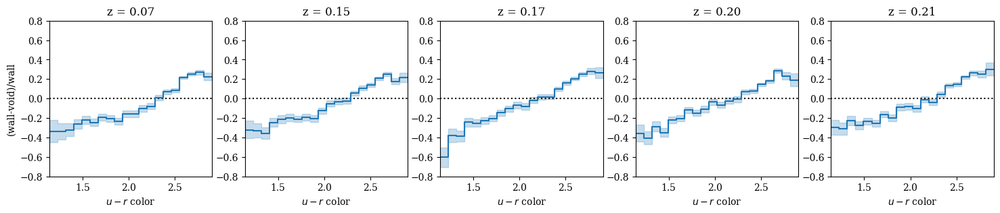

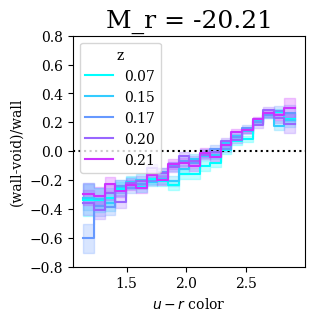

M_r range: -19.999999395161154 -19.653073251916755


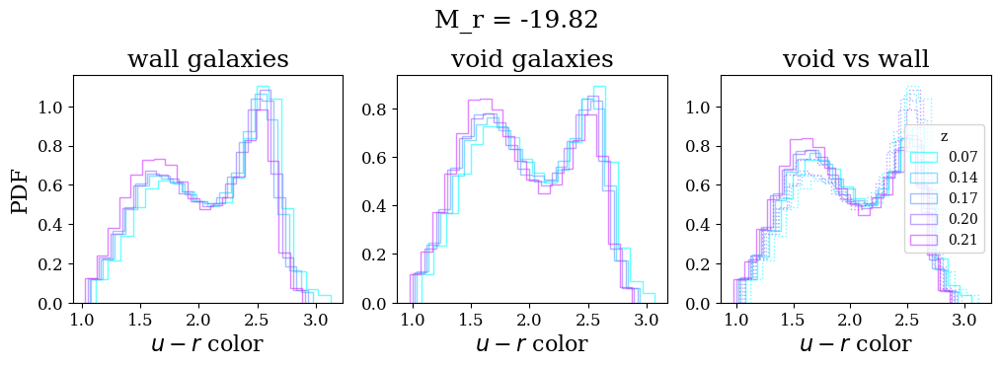

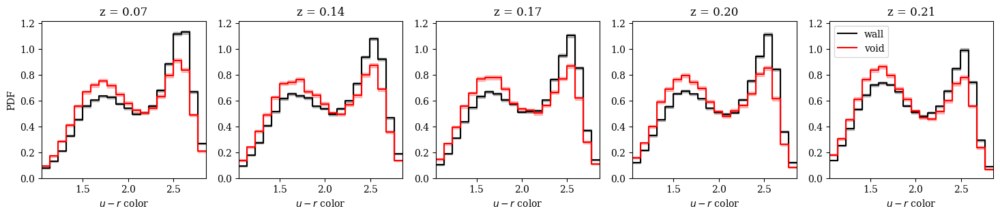

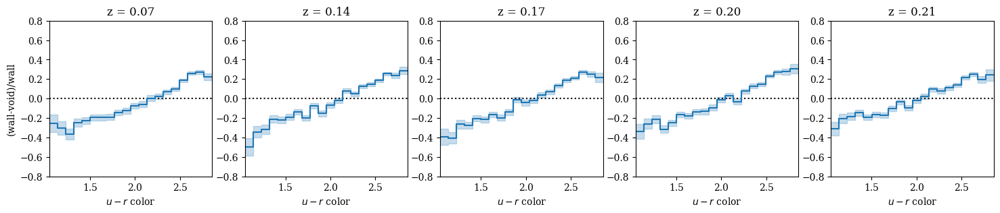

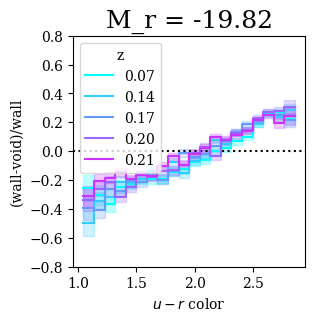

M_r range: -19.653073251916755 -19.32015170512863


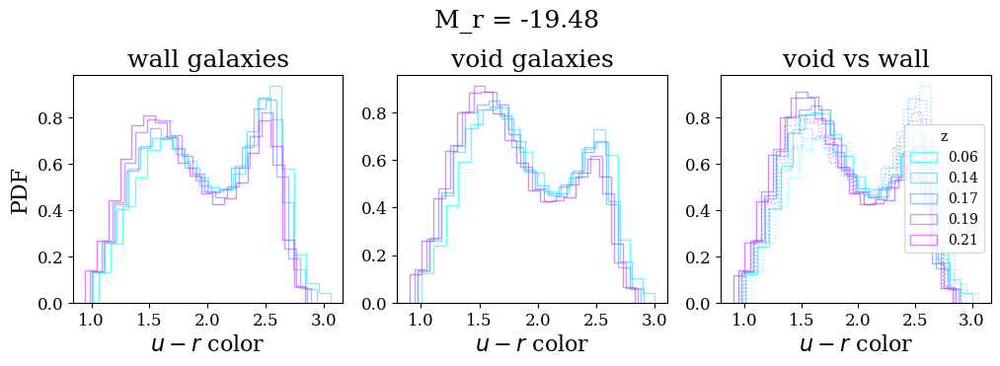

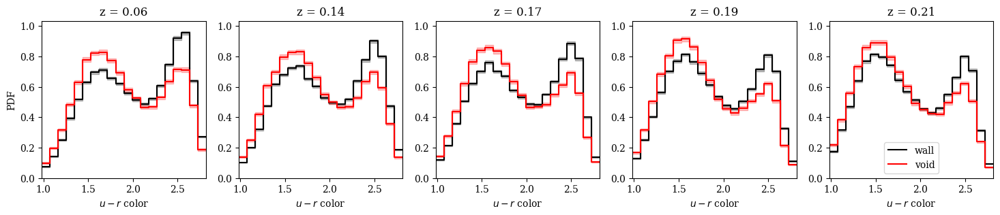

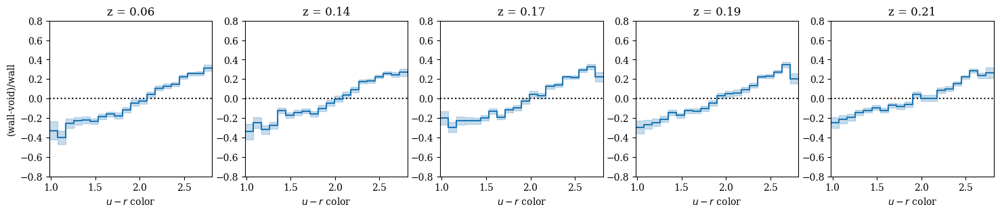

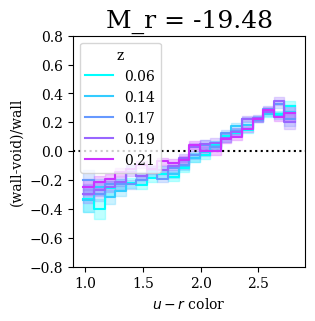

M_r range: -19.32015170512863 -18.958444056318076


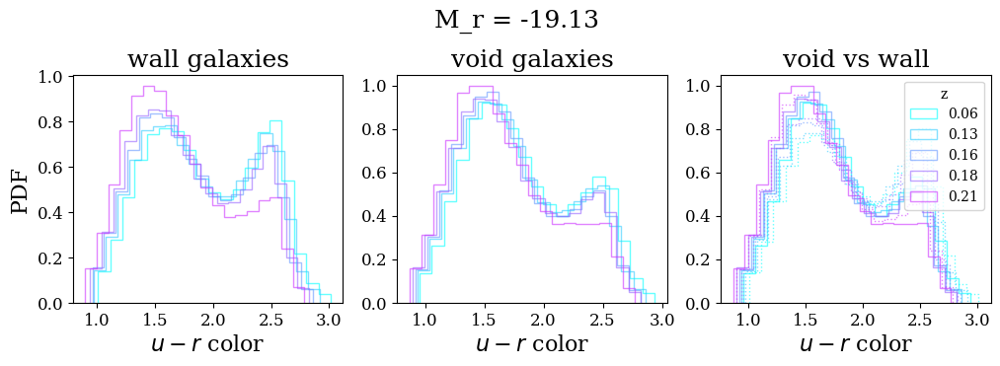

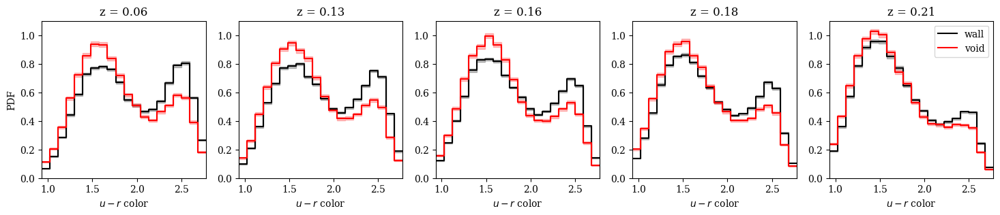

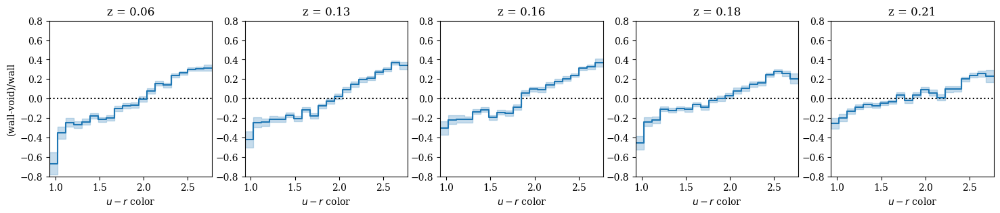

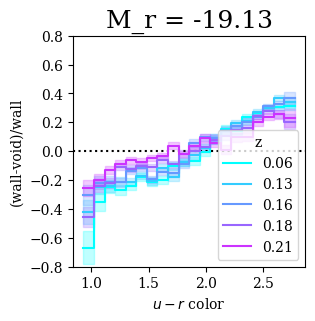

M_r range: -18.958444056318076 -18.444934235837245


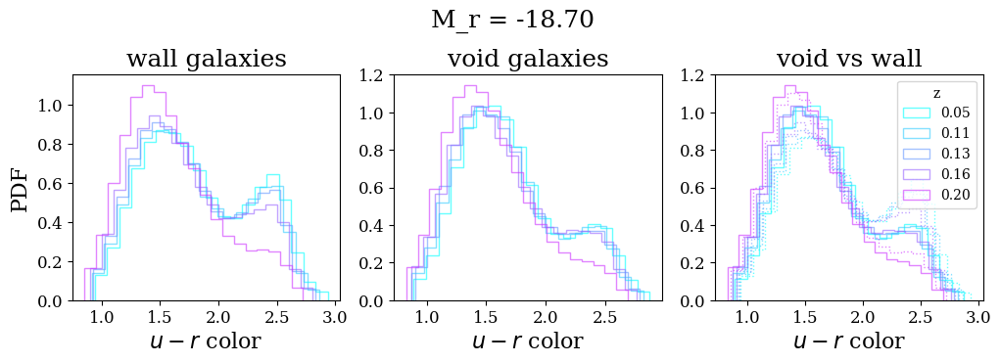

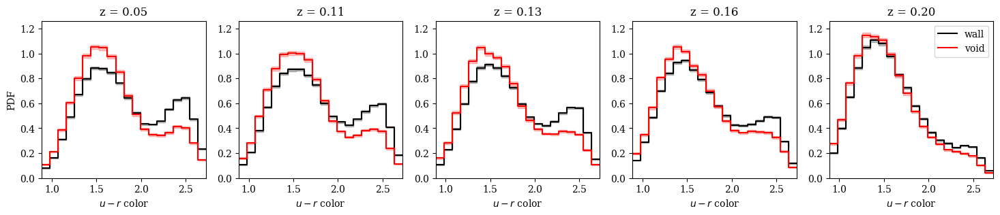

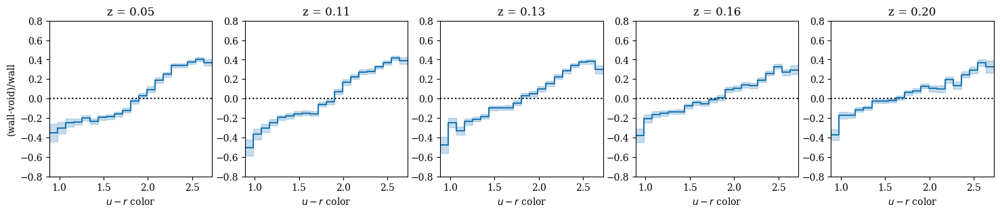

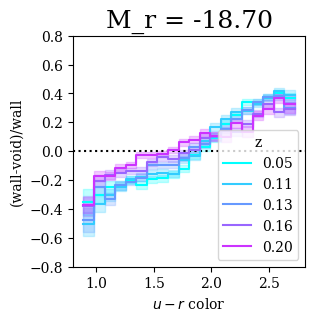

M_r range: -18.444934235837245 -17.000000820855885


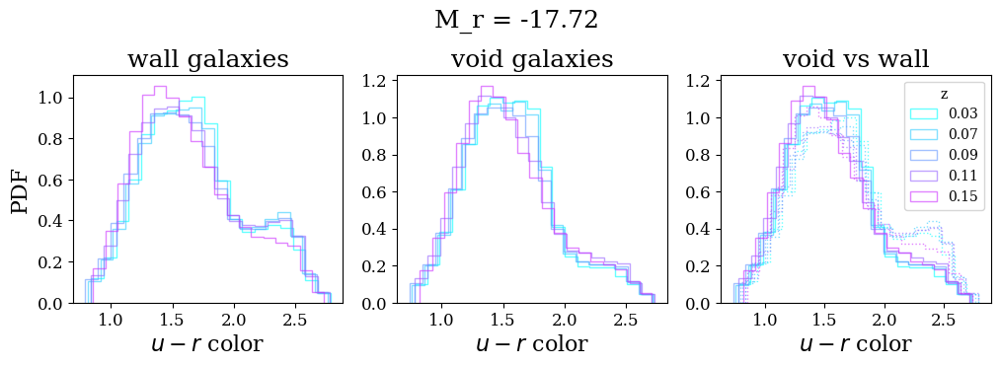

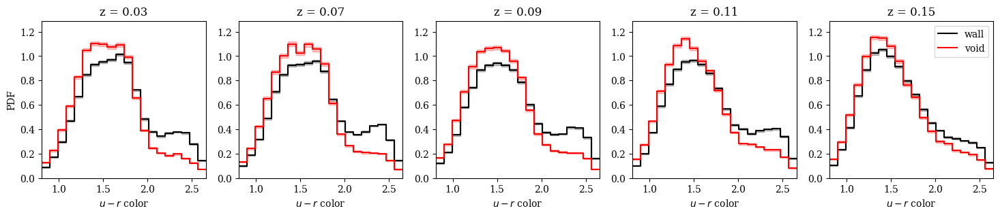

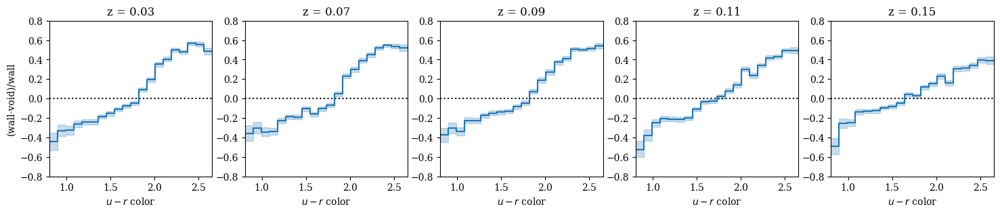

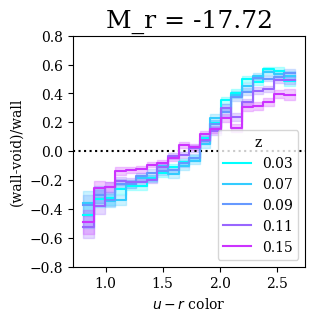

M_r range: -17.000000820855885 -14.0


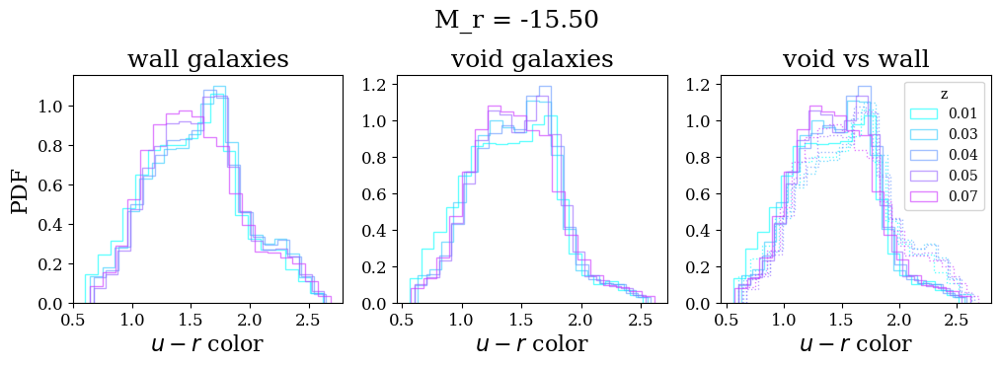

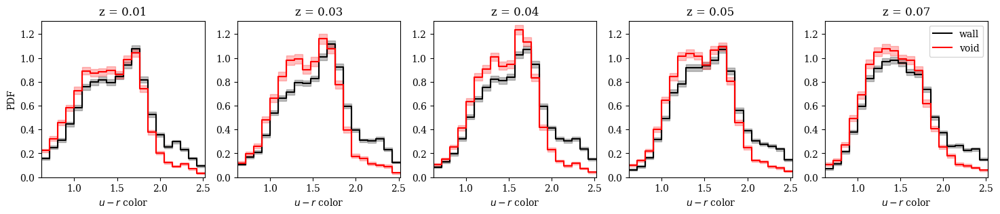

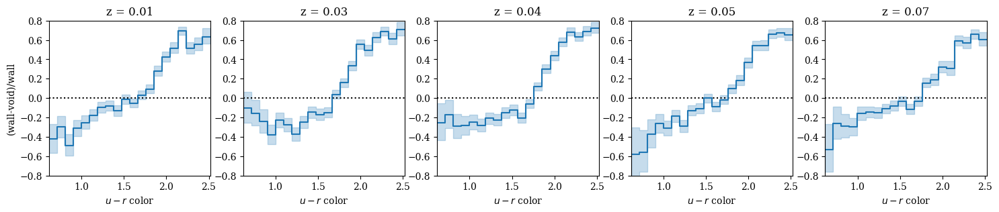

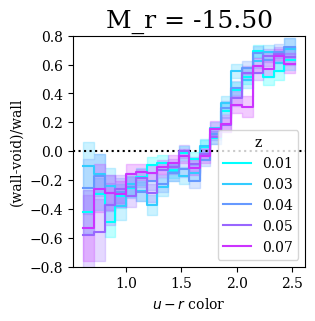

M_r range: -21.138253063379075 -20.43024595282527


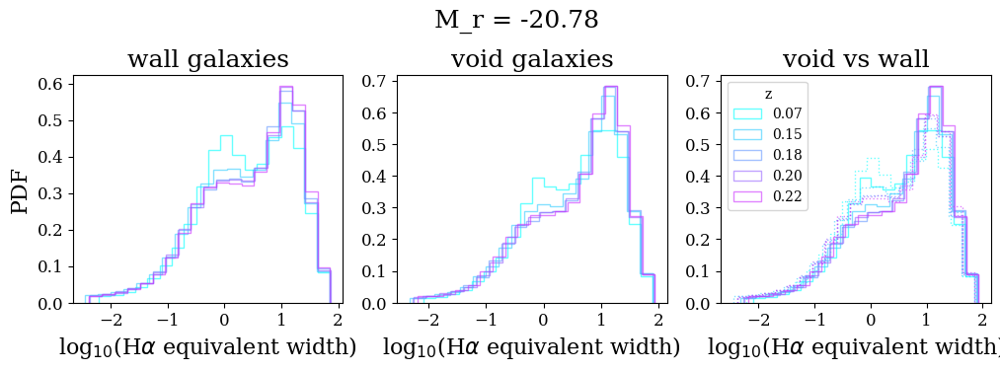

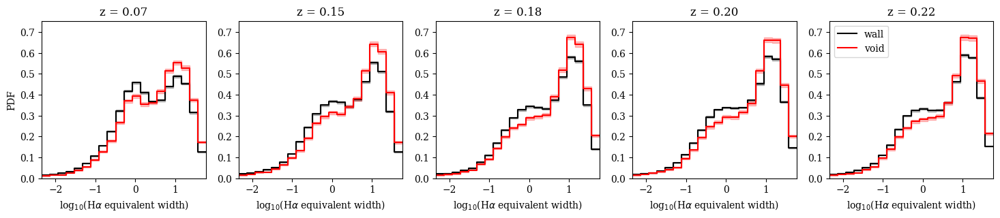

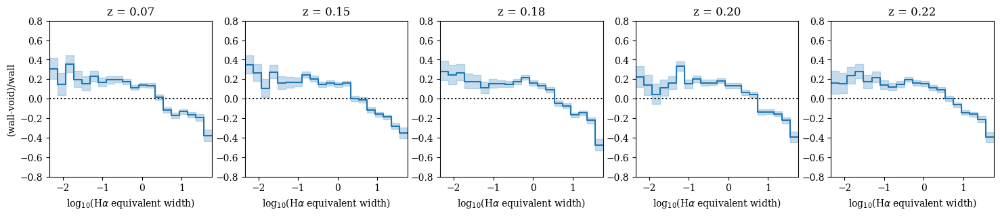

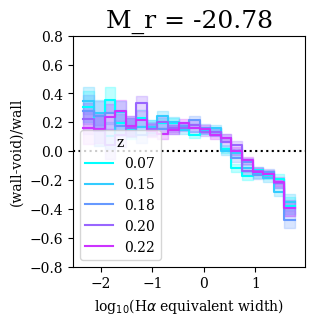

M_r range: -20.43024595282527 -19.999999395161154


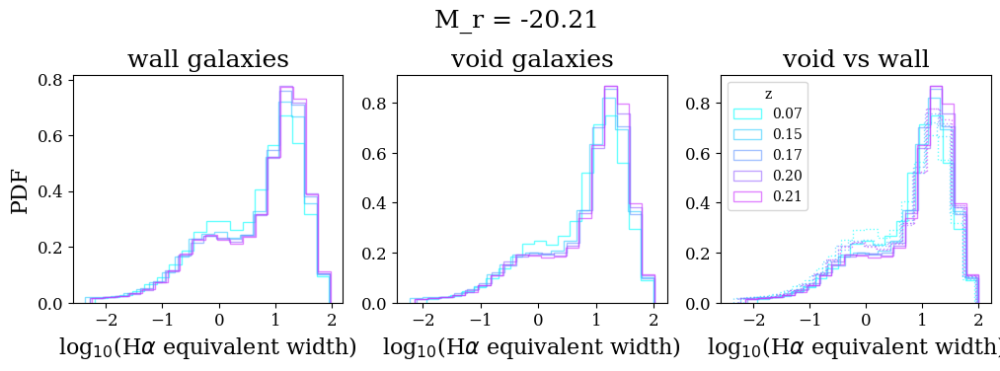

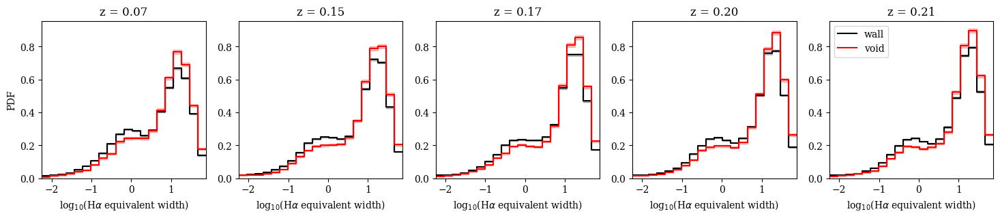

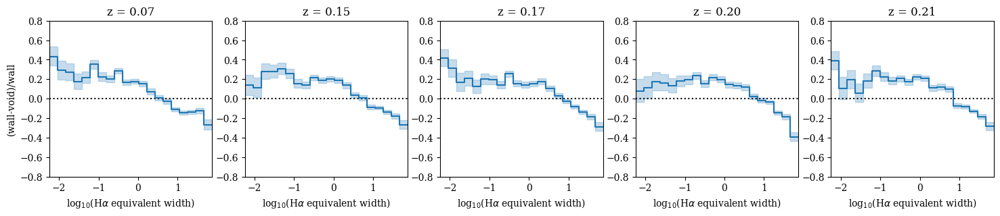

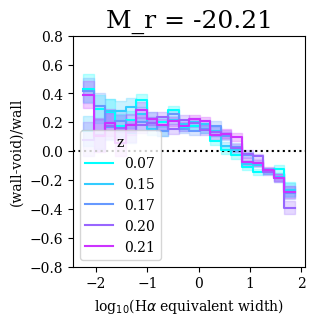

M_r range: -19.999999395161154 -19.653073251916755


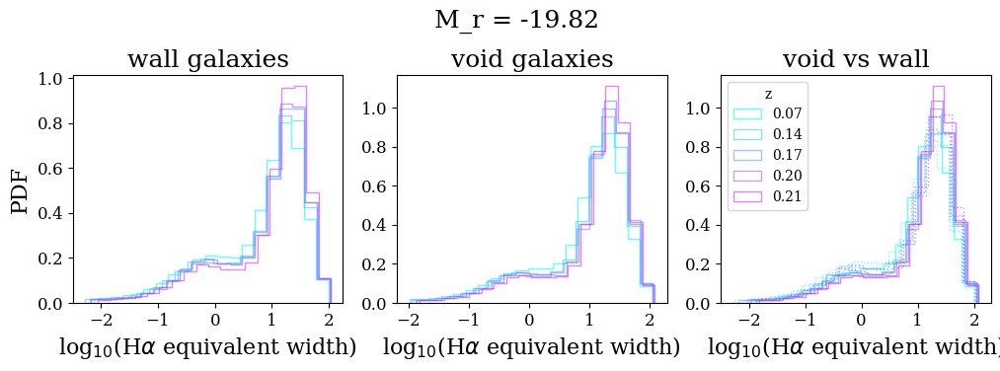

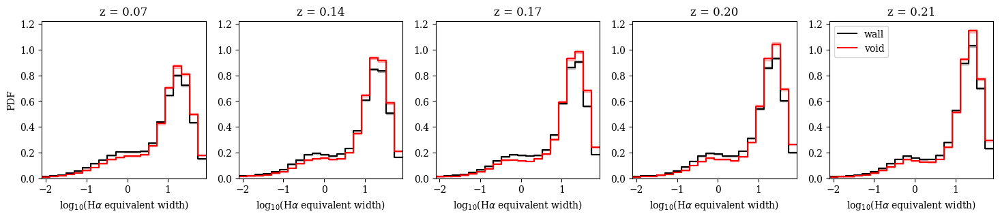

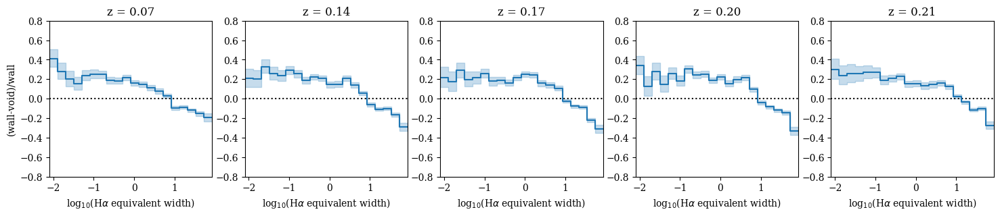

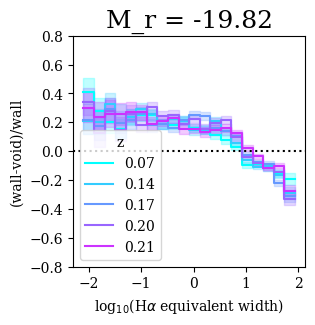

M_r range: -19.653073251916755 -19.32015170512863


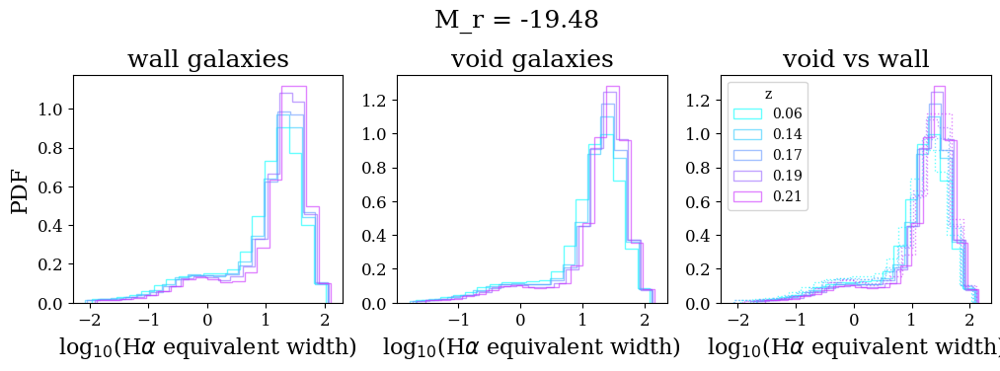

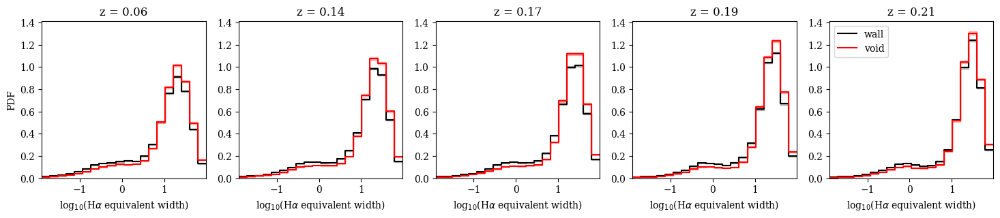

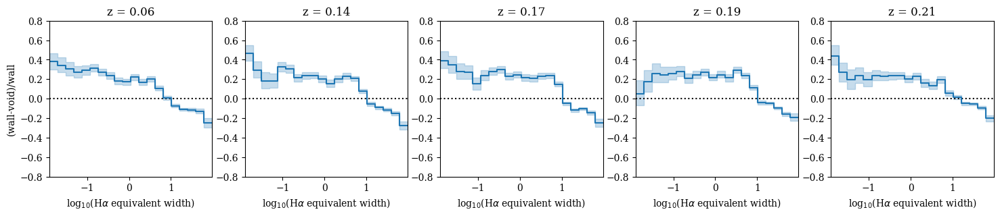

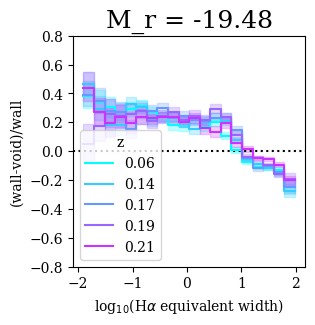

M_r range: -19.32015170512863 -18.958444056318076


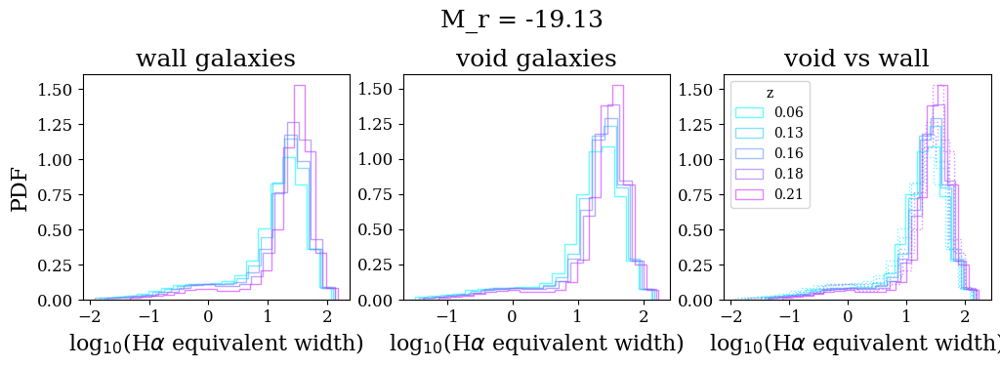

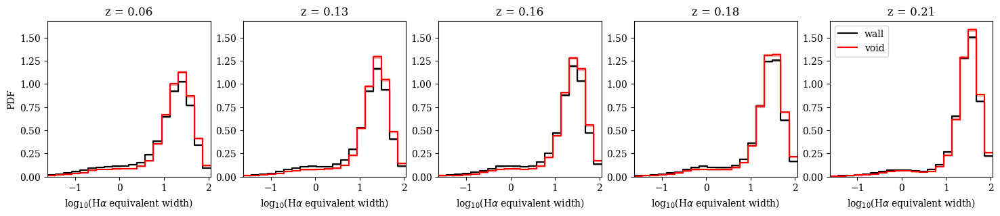

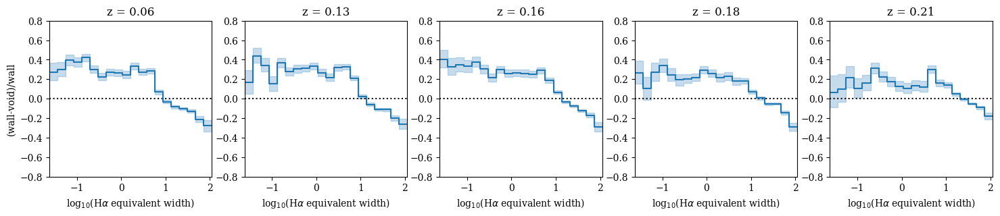

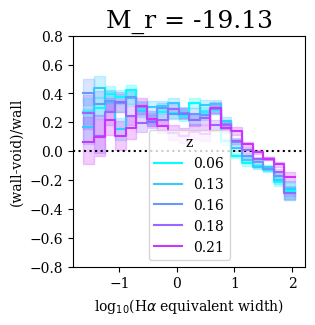

M_r range: -18.958444056318076 -18.444934235837245


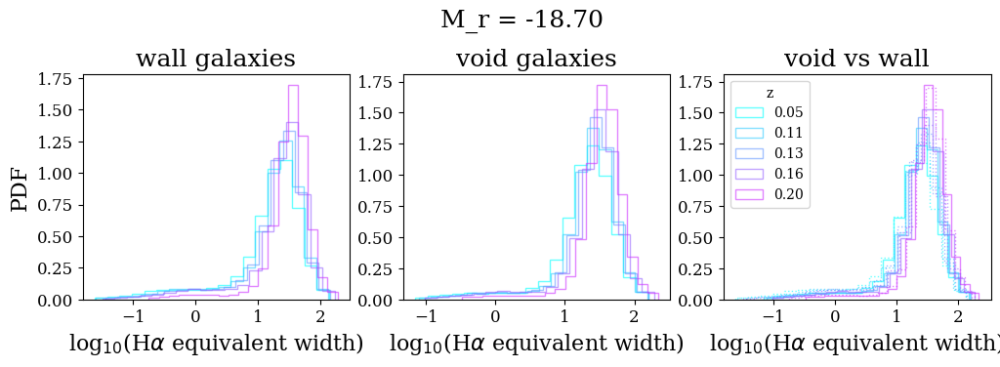

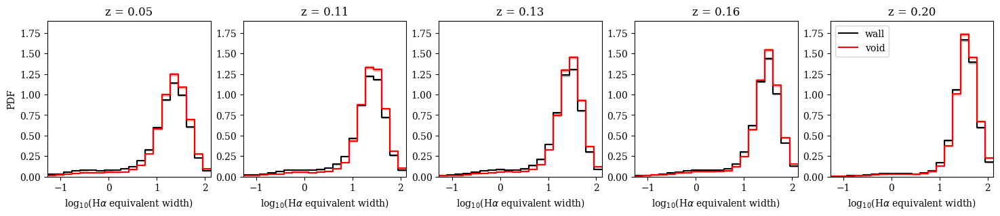

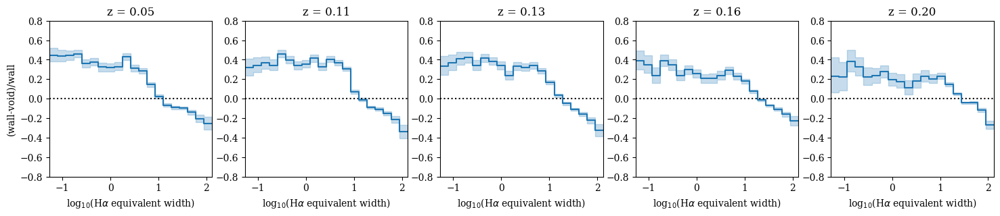

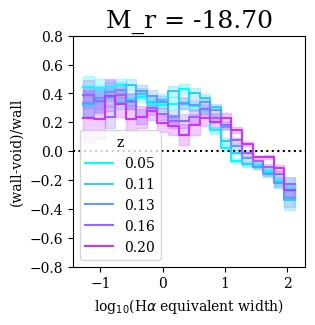

M_r range: -18.444934235837245 -17.000000820855885


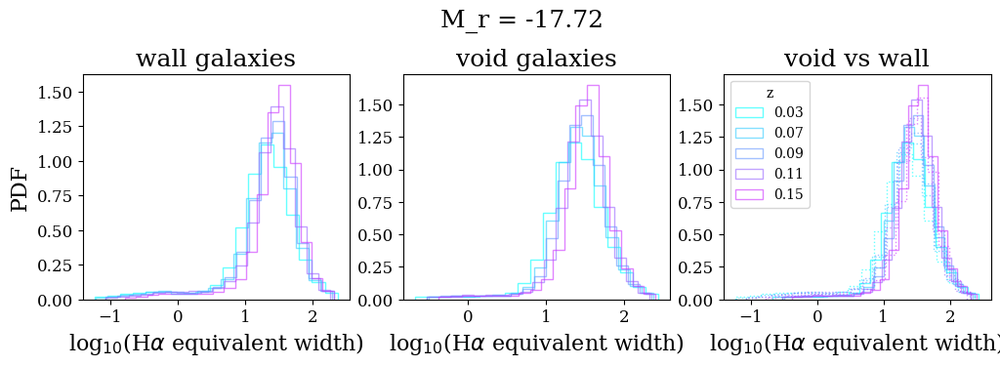

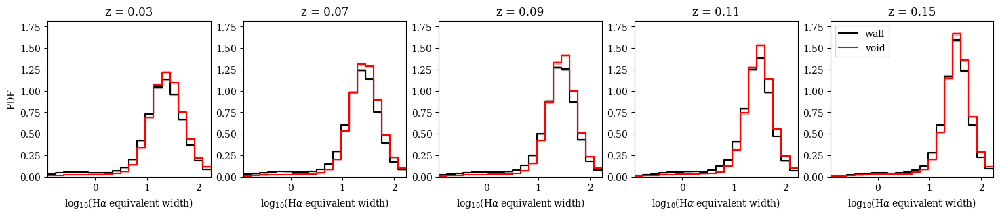

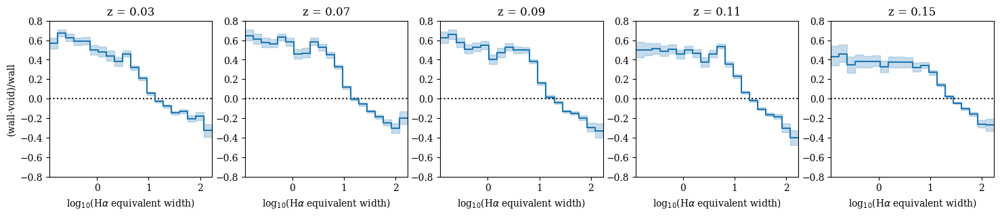

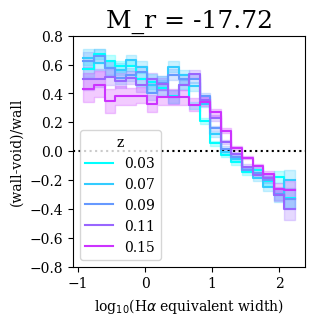

M_r range: -17.000000820855885 -14.0


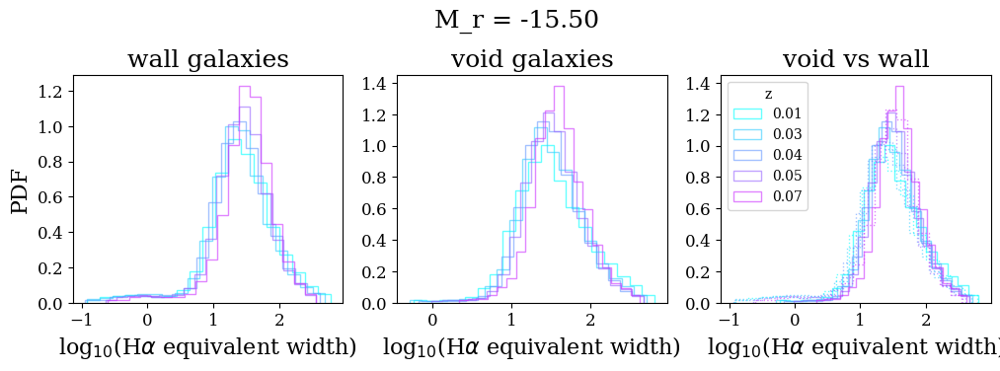

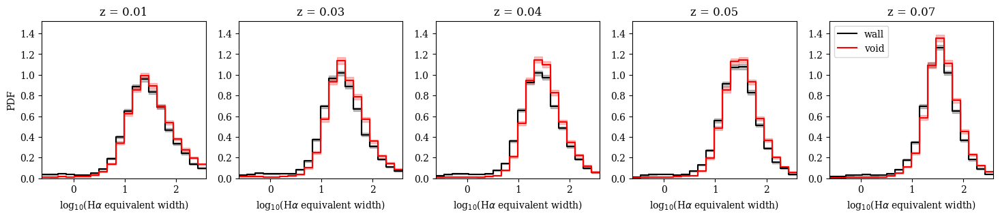

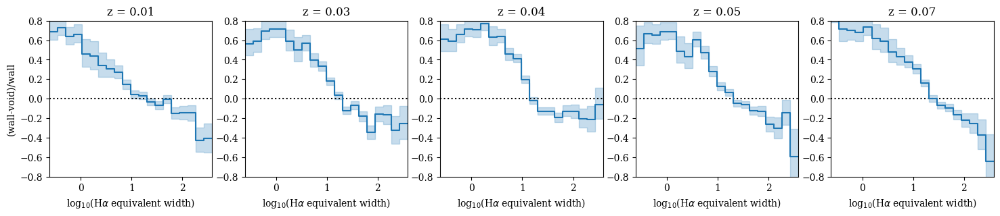

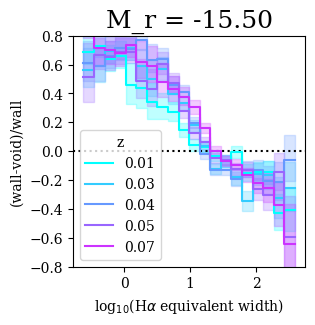

In [181]:
for property, title in zip(['log_mstar','g-r','u-r','halpha'], [r'stellar mass (log (M$_*$/M$_\odot$))', r"$g-r$ color", r"$u-r$ color", r"log$_{10}$(H$\alpha$ equivalent width)"]):
    plot_z_evolution(property, title, heatmap_mr_bins, num_z_bins=5, sample='BGS', density = True)
    

M_r range: -22.2 -19.999951235156757


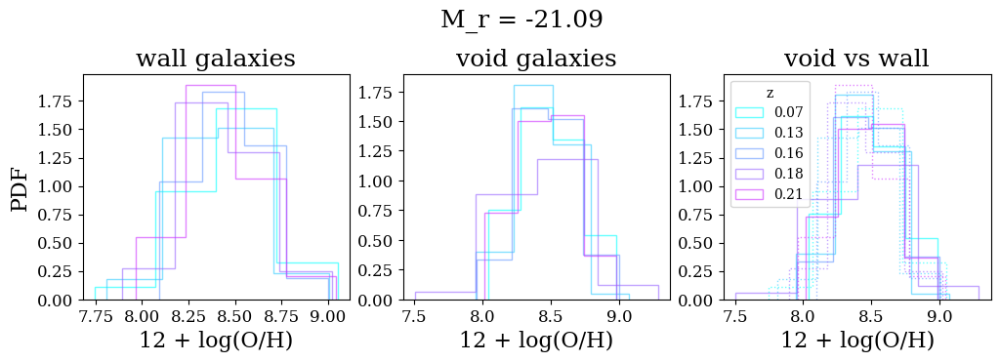

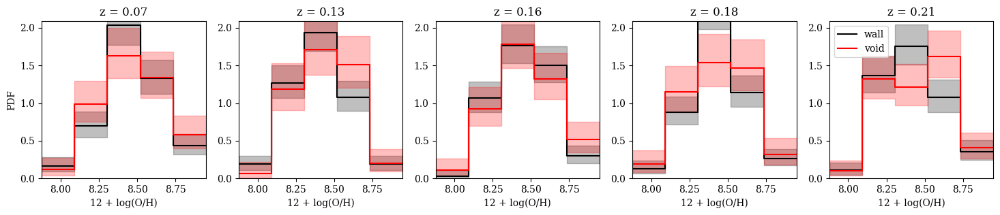

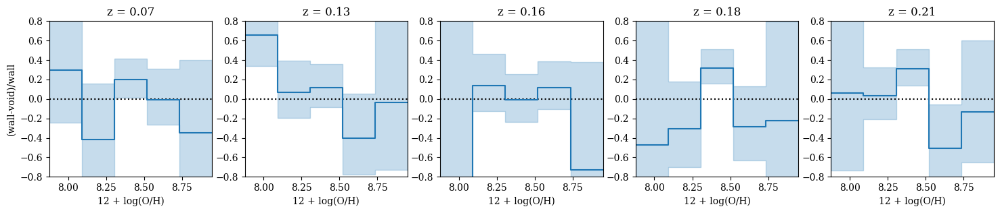

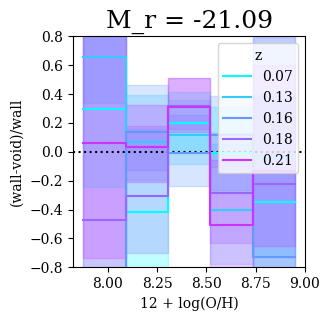

M_r range: -19.999951235156757 -19.320205265505038


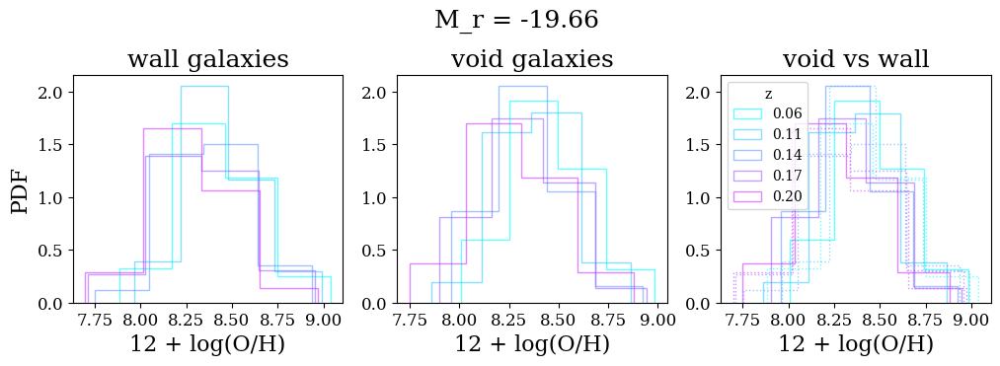

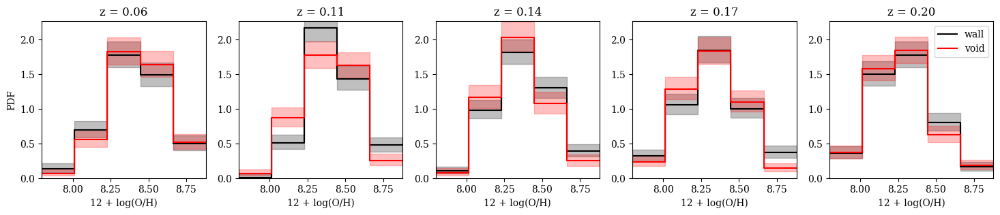

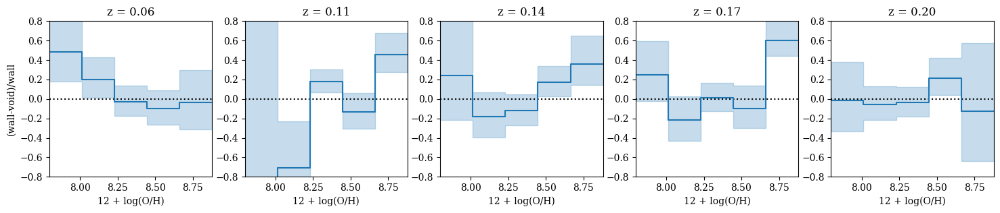

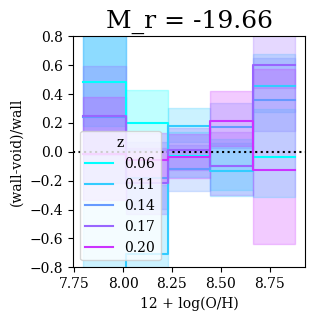

M_r range: -19.320205265505038 -18.844098598199523


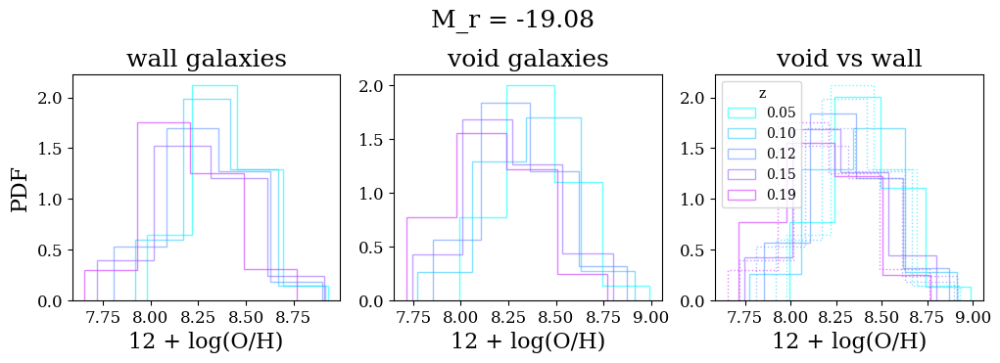

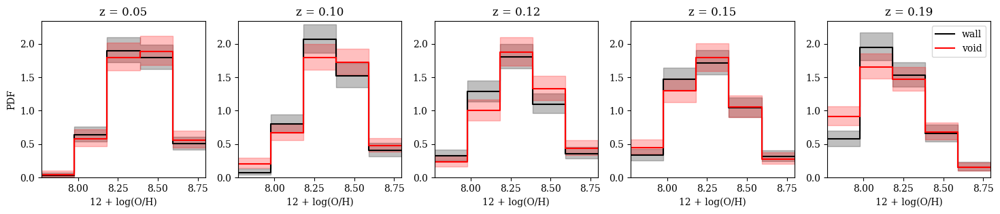

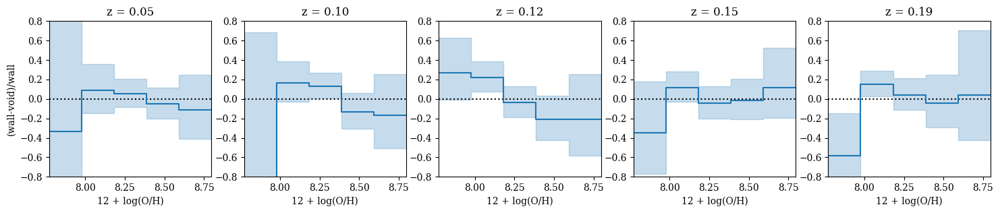

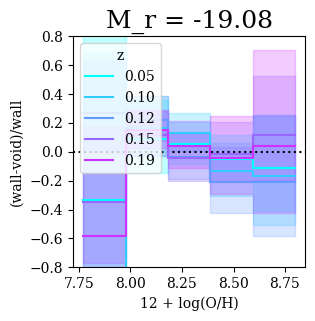

M_r range: -18.844098598199523 -18.371748116626737


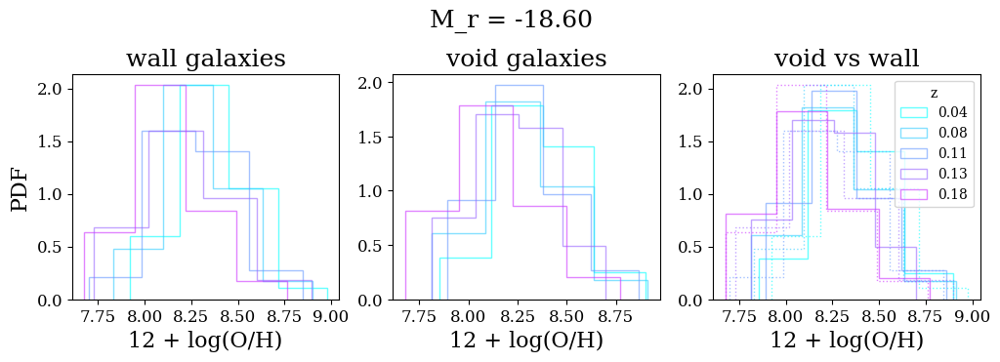

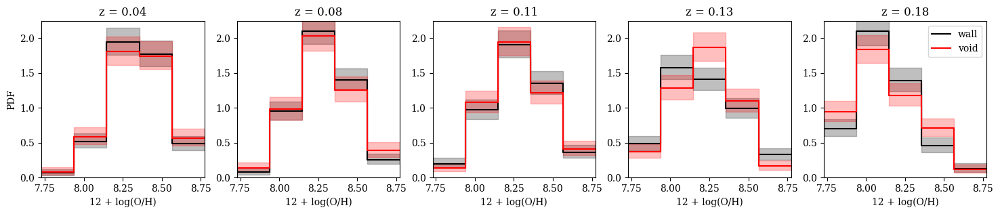

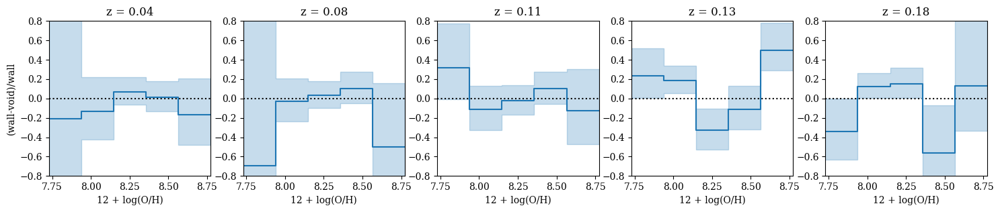

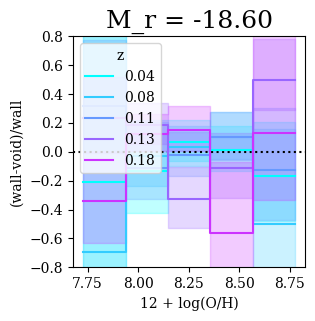

M_r range: -18.371748116626737 -17.80529872495


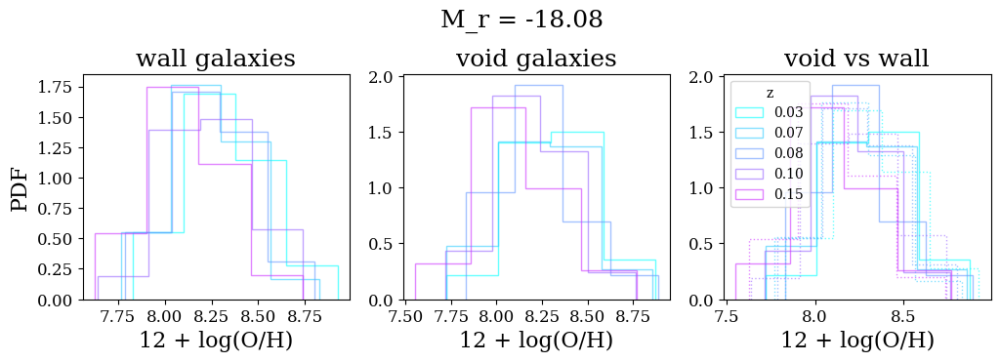

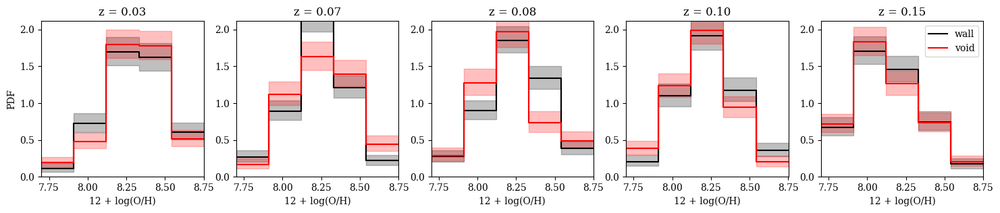

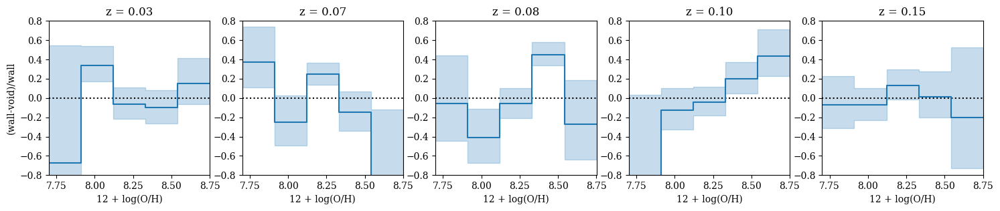

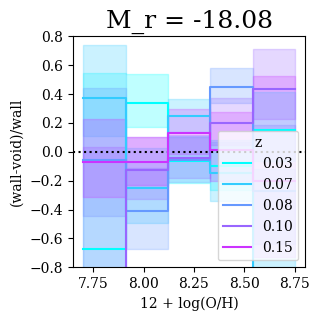

M_r range: -17.80529872495 -17.00028553141977


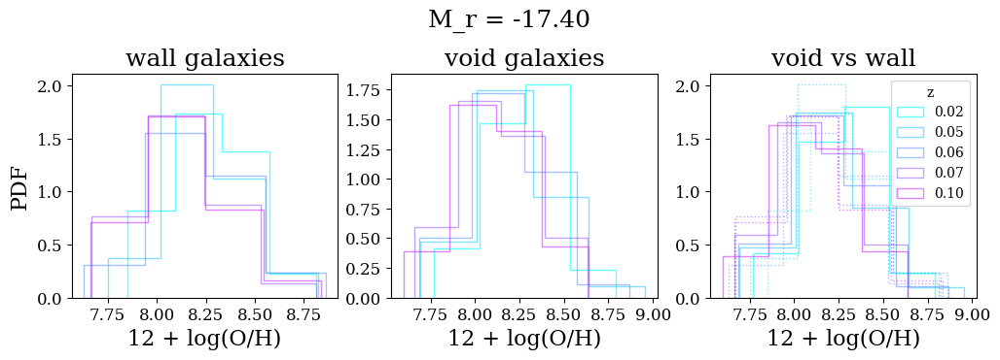

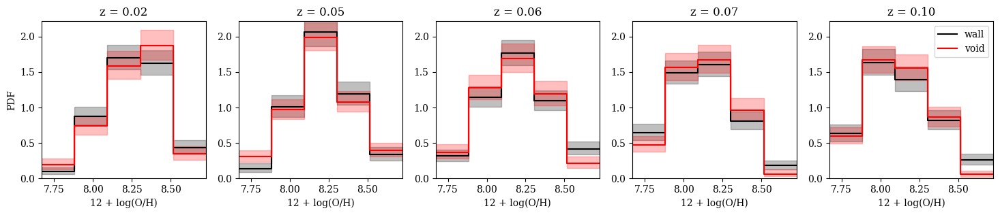

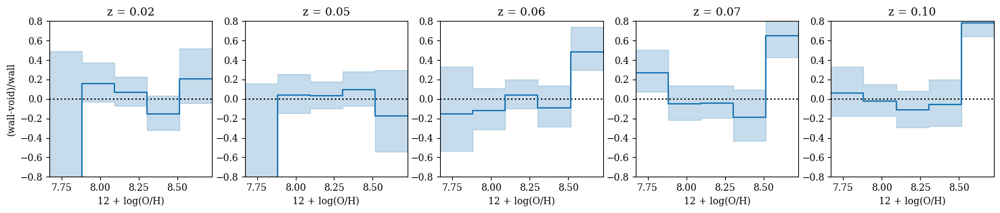

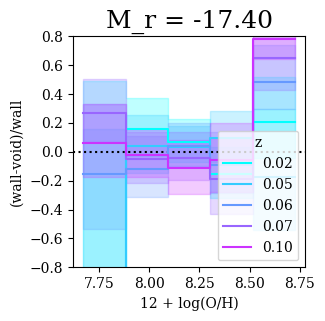

M_r range: -17.00028553141977 -14.0


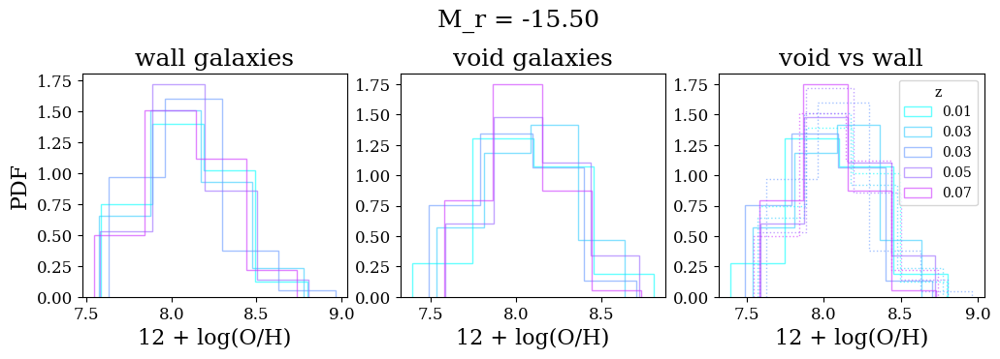

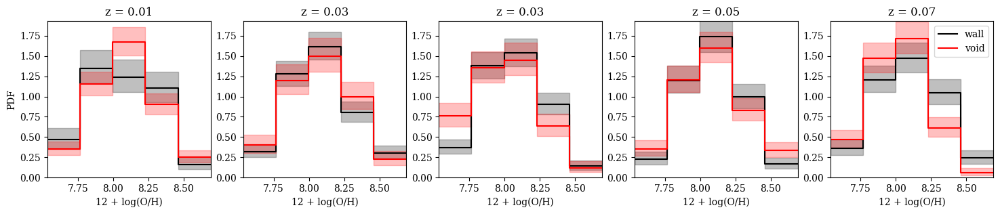

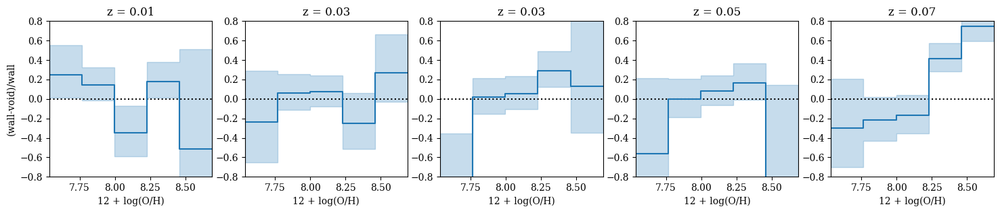

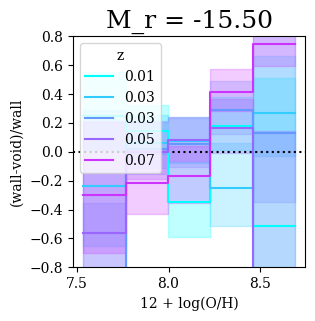

M_r range: -22.2 -19.999951235156757


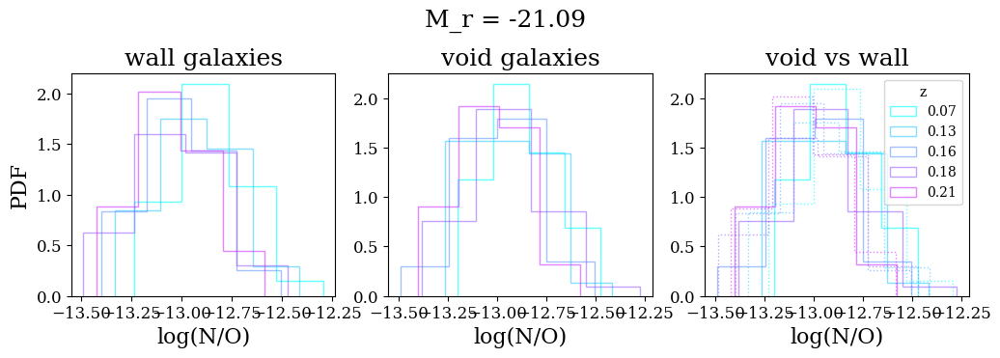

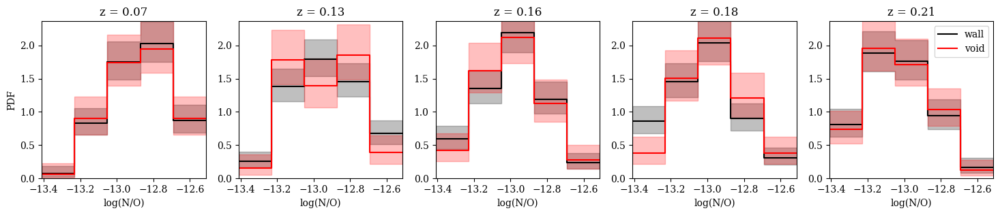

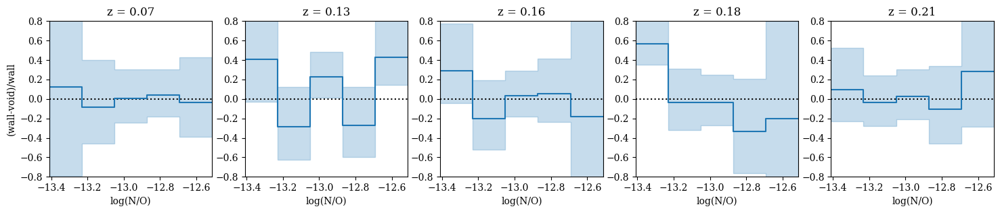

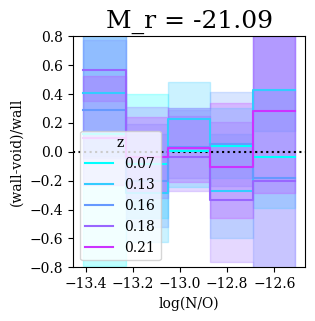

M_r range: -19.999951235156757 -19.320205265505038


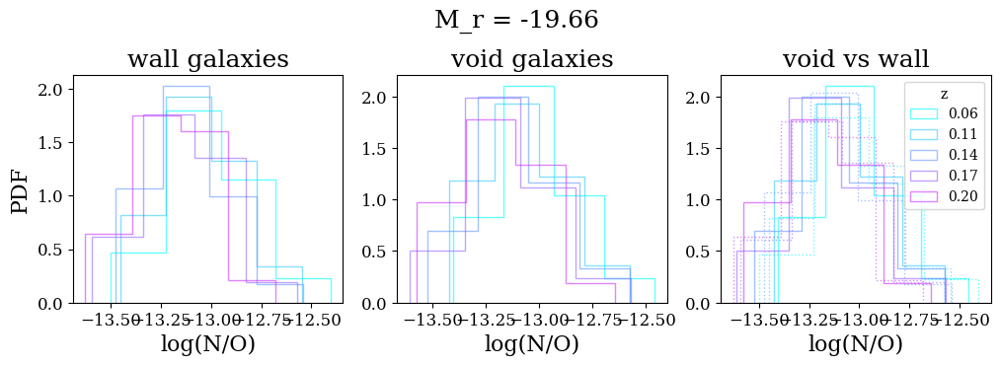

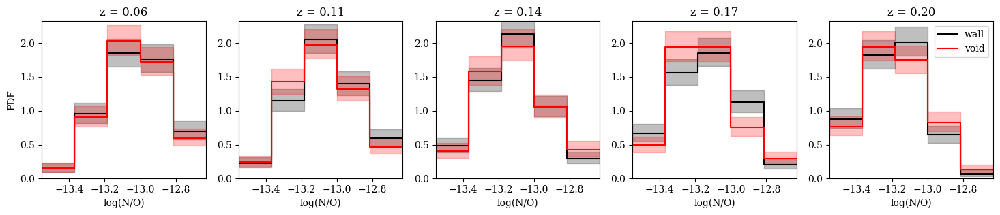

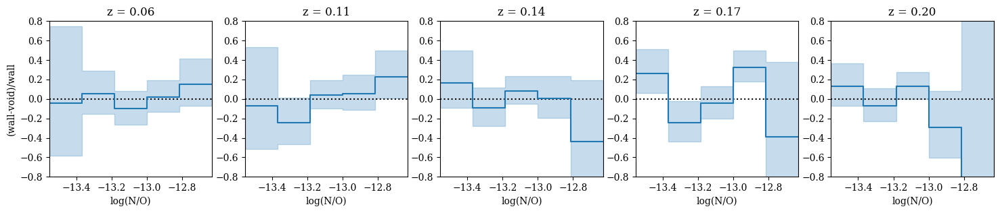

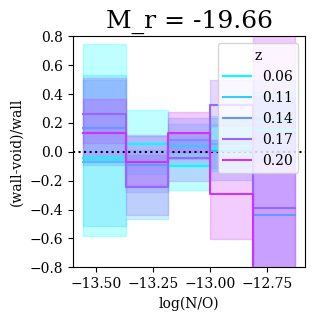

M_r range: -19.320205265505038 -18.844098598199523


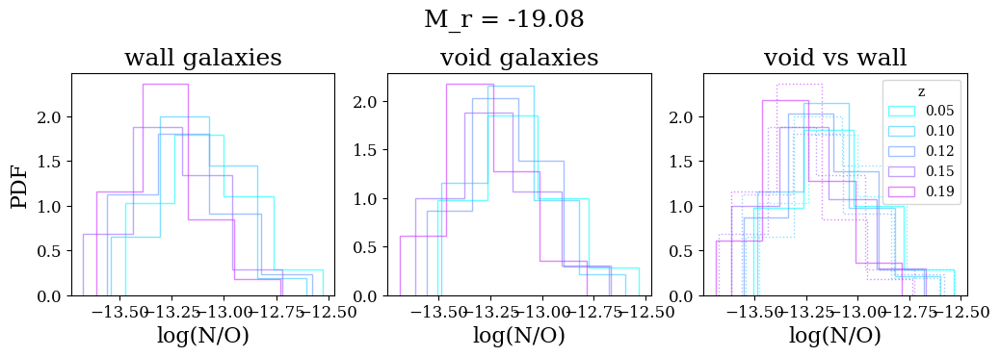

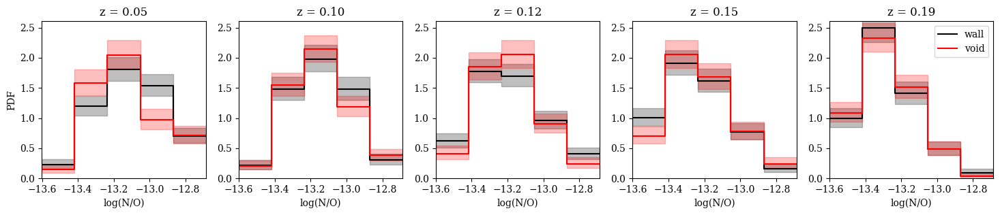

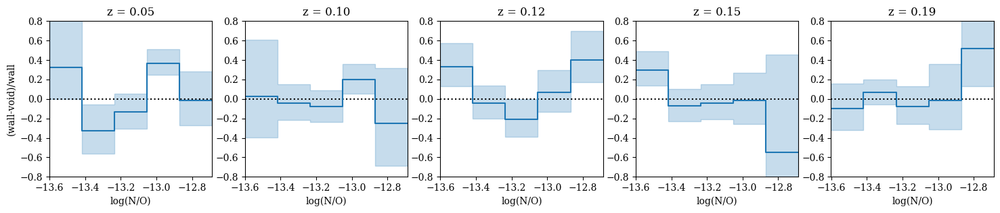

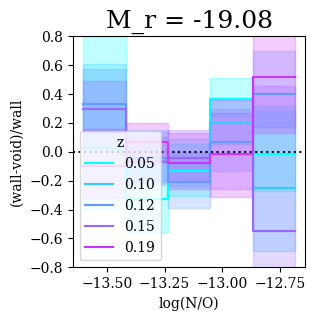

M_r range: -18.844098598199523 -18.371748116626737


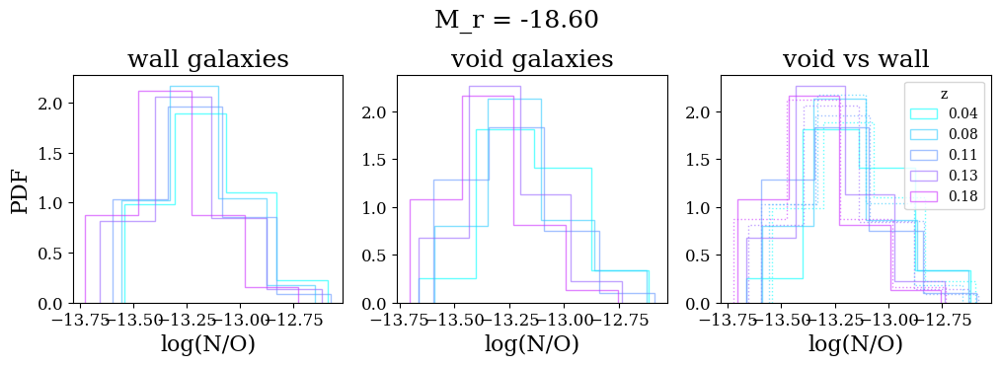

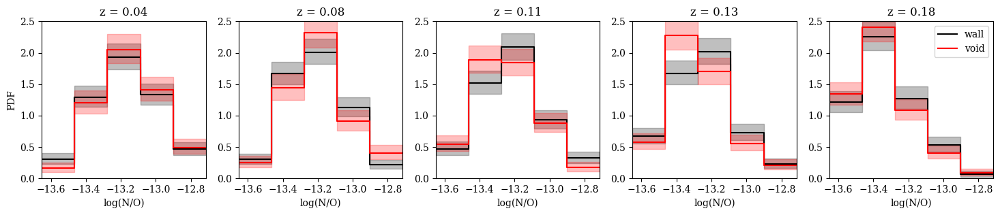

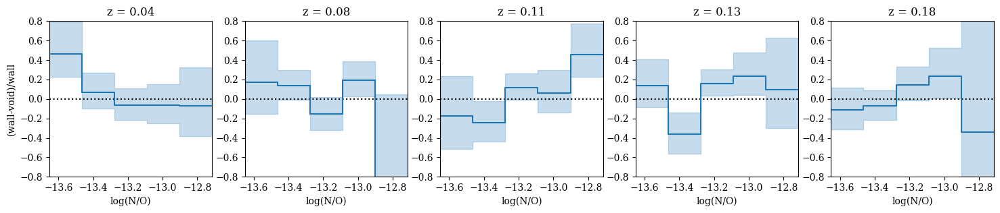

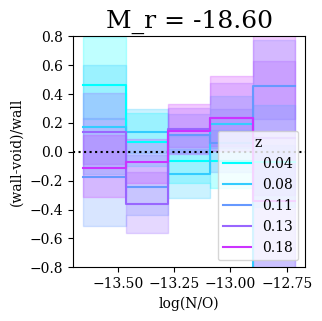

M_r range: -18.371748116626737 -17.80529872495


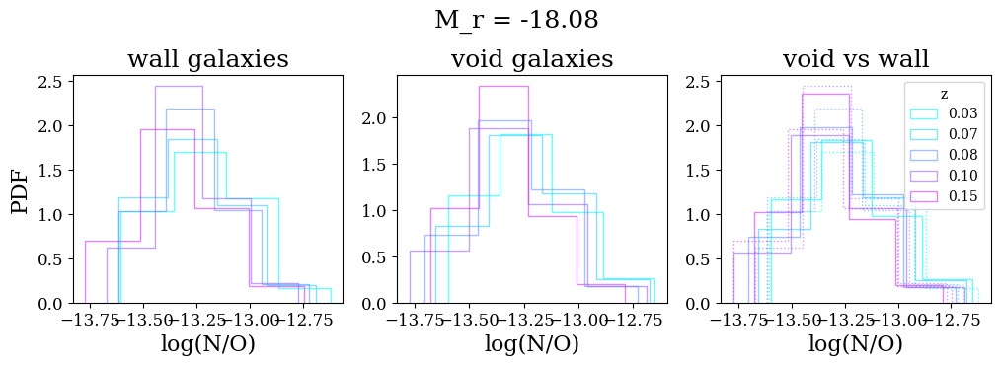

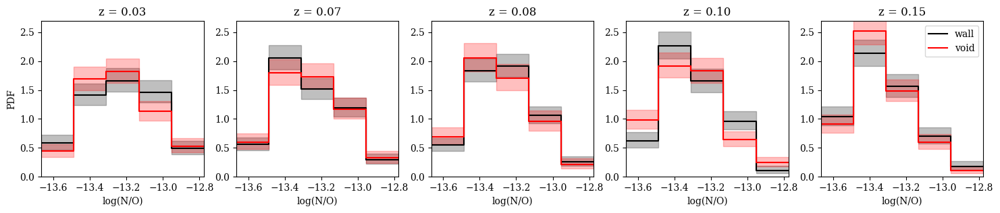

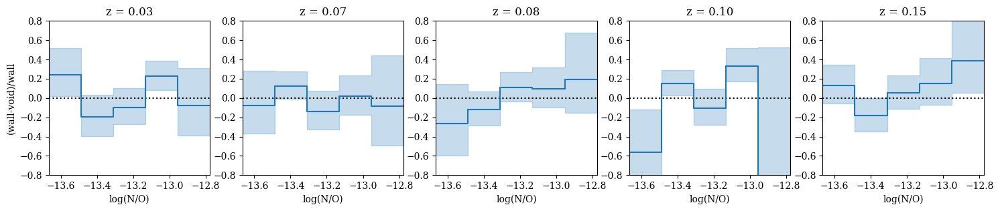

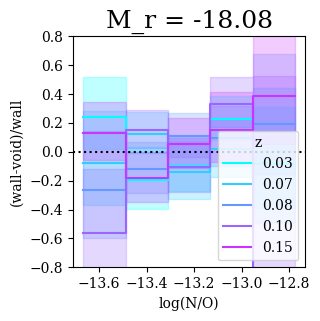

M_r range: -17.80529872495 -17.00028553141977


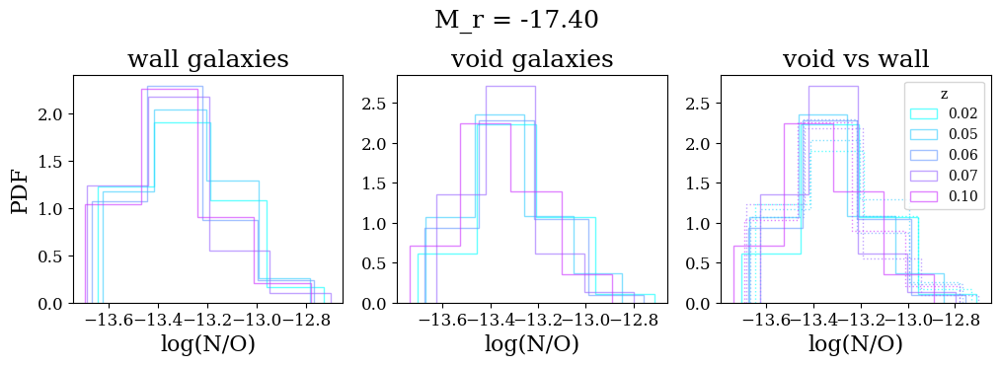

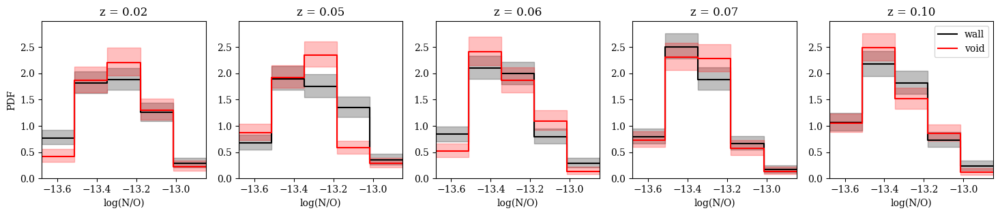

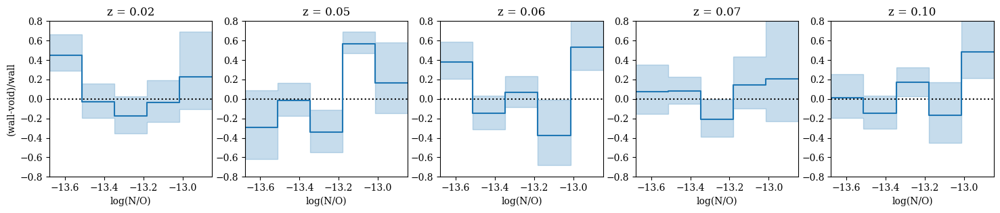

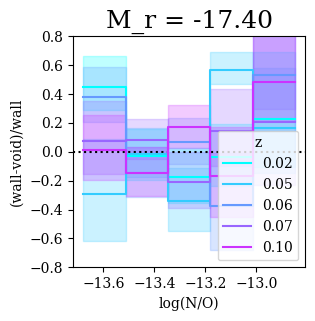

M_r range: -17.00028553141977 -14.0


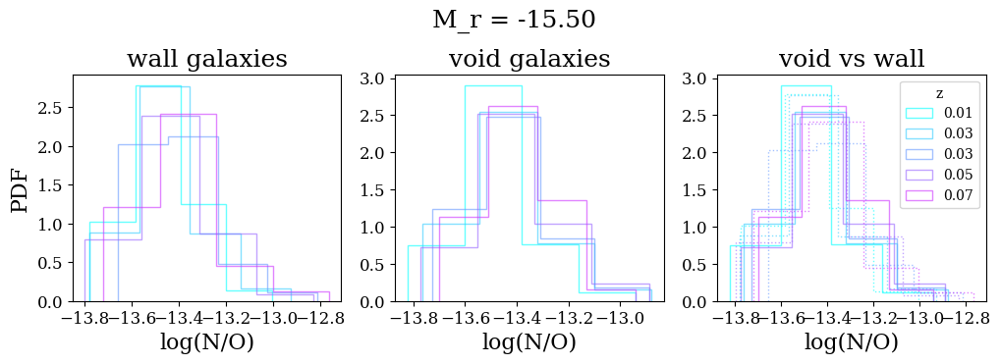

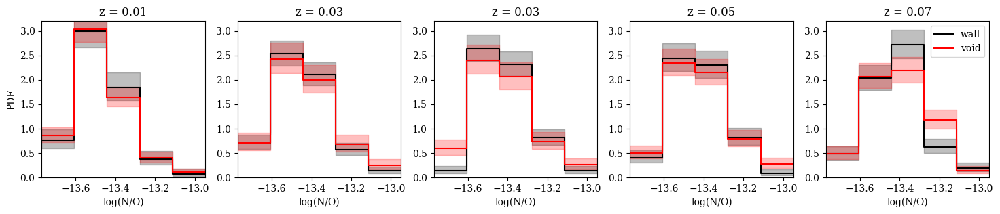

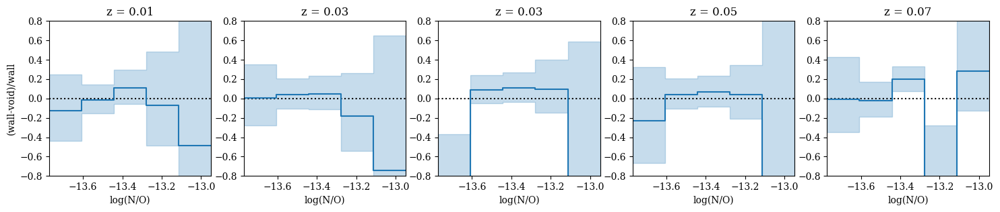

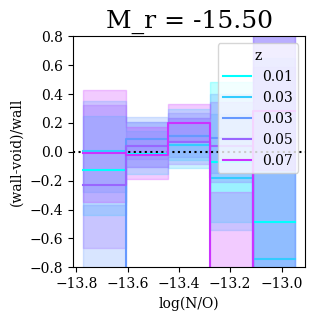

In [180]:
for property, title in zip(['oh_p50', 'no'], [r"12 + log(O/H)", r"log(N/O)"]):
    plot_z_evolution(property, title, heatmap_mr_bins_metal, num_z_bins=5, sample='BGS', density = True)


# Heatmaps

In [49]:
metal_bfs_cubes = {}

for c in (4, 6):
    for max_depth in (5, 7):
        metal_bfs_cubes[(c, max_depth)] = []
        for property, title in zip(['oh_p50', 'no'], [r"12 + log(O/H)", r"log(N/O)"]):
            metal_bfs_cubes[(c, max_depth)].append(
                plot_heatmap(property, title, heatmap_mr_bins_metal, num_z_bins=5, sample='BGS', display_plot = False, c = c, max_depth = max_depth)
            )

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [50]:
full_bfs_cubes = {}

for c in (4, 6):
    for max_depth in (5, 7):
        full_bfs_cubes[(c, max_depth)] = []
        for property, title in zip(['log_mstar','g-r','u-r','halpha'], [r'stellar mass (log (M$_*$/M$_\odot$))', r"$g-r$ color", r"$u-r$ color", r"log$_{10}$(H$\alpha$ equivalent width)"]):
            full_bfs_cubes[(c, max_depth)].append(
                plot_heatmap(property, title, heatmap_mr_bins, num_z_bins=5, sample='BGS', display_plot = False, c = c, max_depth = max_depth)
            )

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

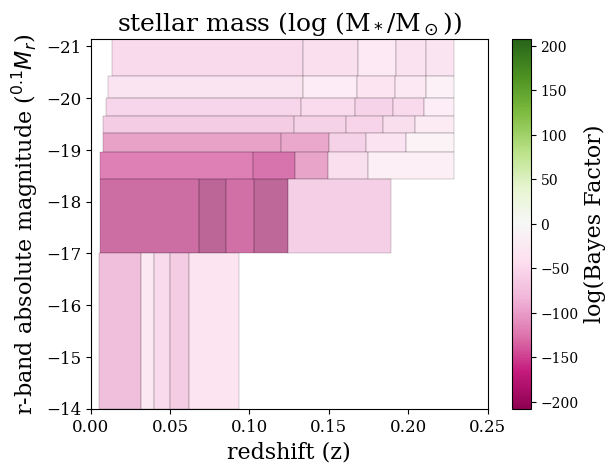

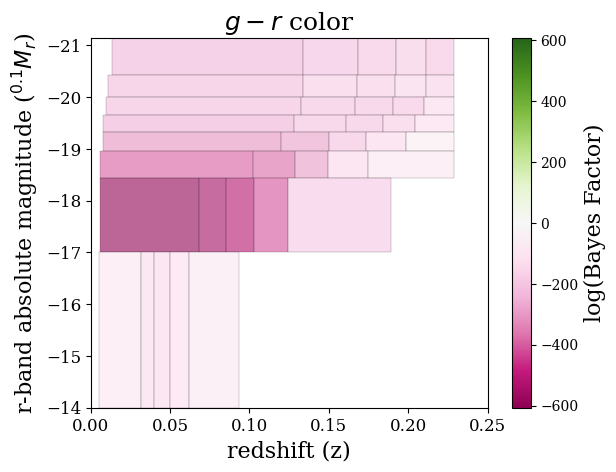

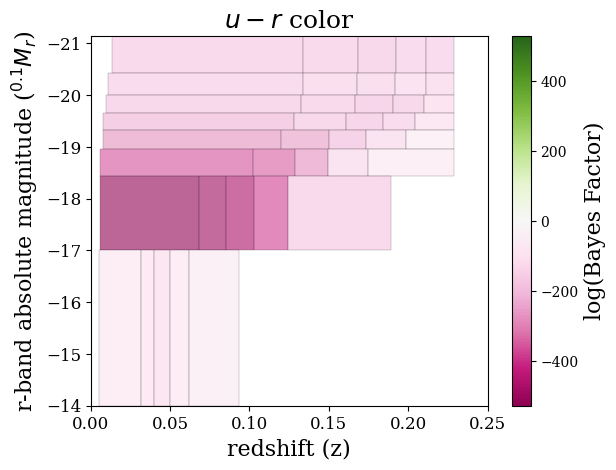

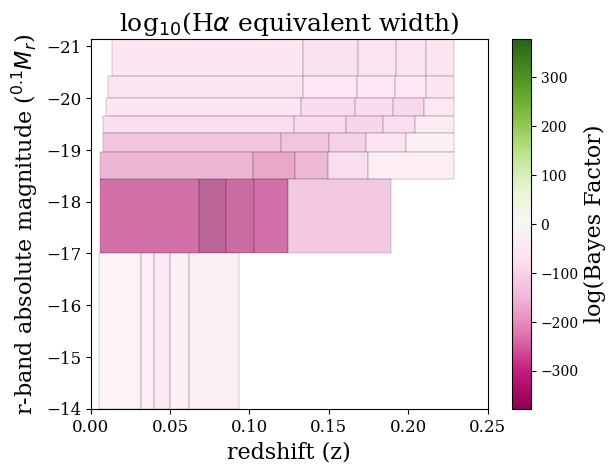

In [38]:
#Plot heatmaps
full_bfs = []

for property, title in zip(['log_mstar','g-r','u-r','halpha'], [r'stellar mass (log (M$_*$/M$_\odot$))', r"$g-r$ color", r"$u-r$ color", r"log$_{10}$(H$\alpha$ equivalent width)"]):
    full_bfs.append(
        plot_heatmap(property, title, heatmap_mr_bins, num_z_bins=5, sample='BGS', 
                     #save_path = '/global/homes/h/hrincon/galaxy_environment/images/'
                    )
    )

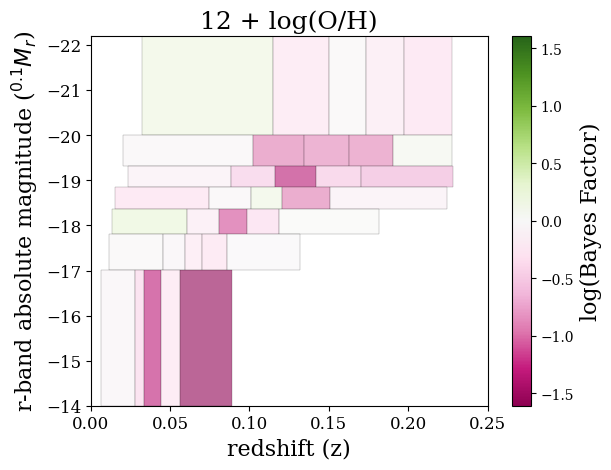

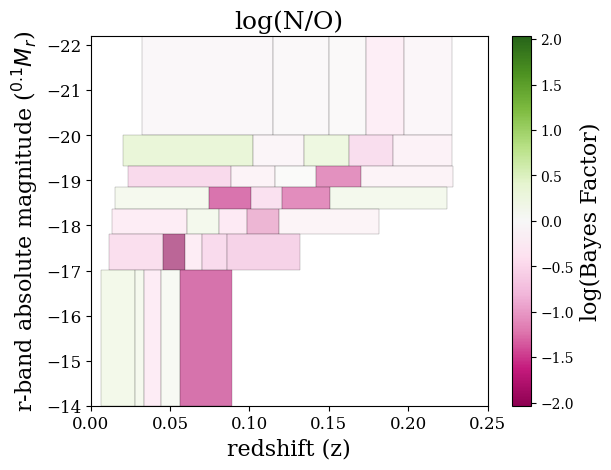

In [39]:
#Plot Metallicity heatmaps
metal_bfs = []
for property, title in zip(['oh_p50', 'no'], [r"12 + log(O/H)", r"log(N/O)"]):
    metal_bfs.append(
        plot_heatmap(property, title, heatmap_mr_bins_metal, num_z_bins=5, sample='BGS', 
                     #save_path = '/global/homes/h/hrincon/galaxy_environment/images/'
                    )
    )

# Test jackknife respampling with various numbers of samples

In [31]:
jackknife_test = []

for div in [2, 5, 10, 20, 50, 100]:
    print(div)
    jackknife_test.append(
        jackknife_heatmap('log_mstar', div, heatmap_mr_bins, num_z_bins=5, sample='BGS', )
    )

2
5
10
20



KeyboardInterrupt



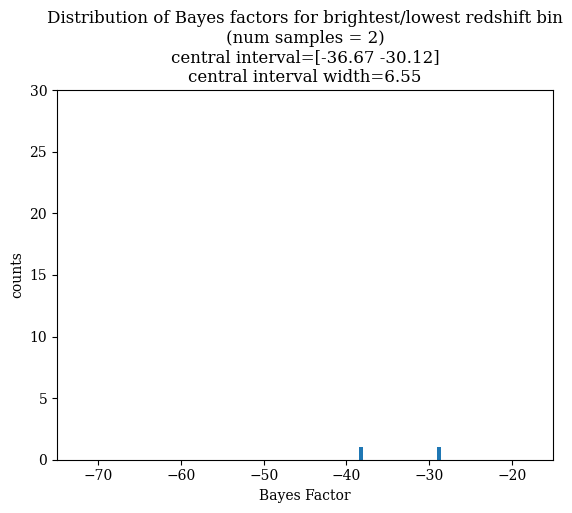

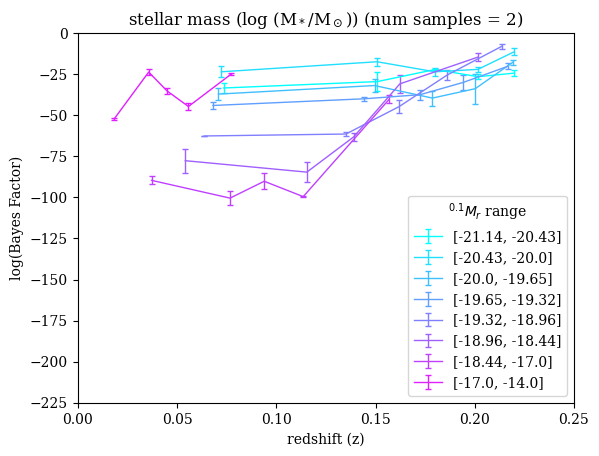

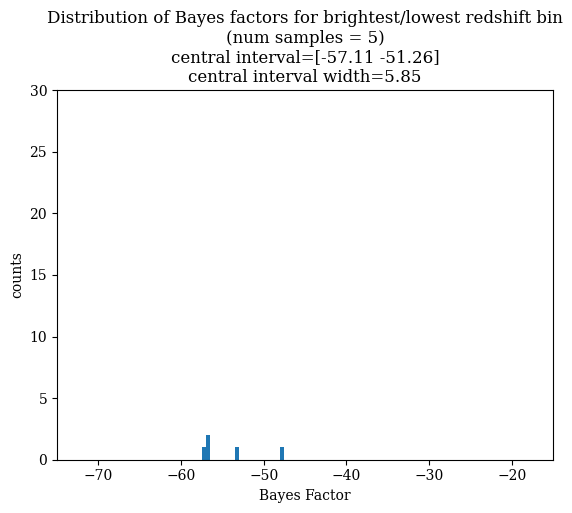

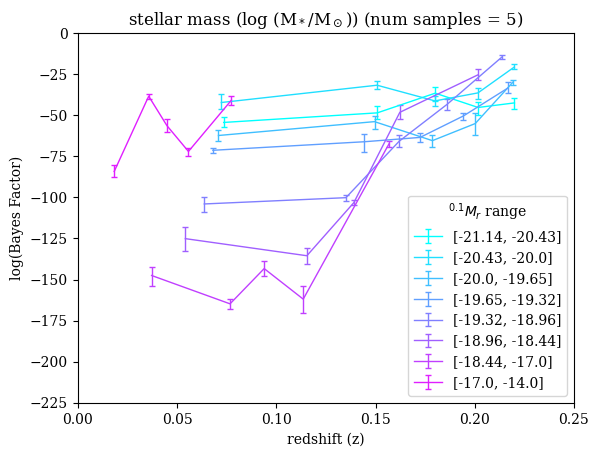

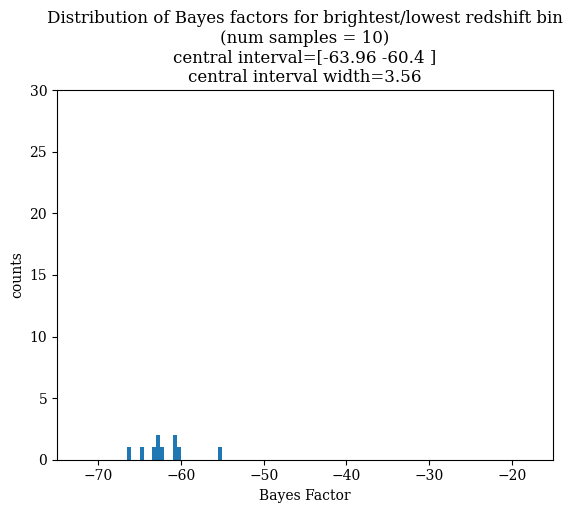

...

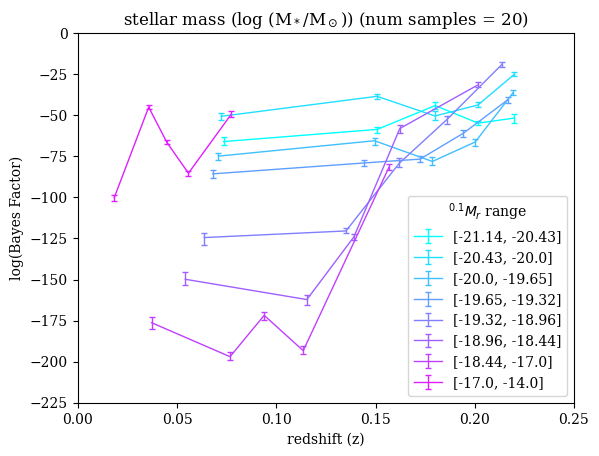

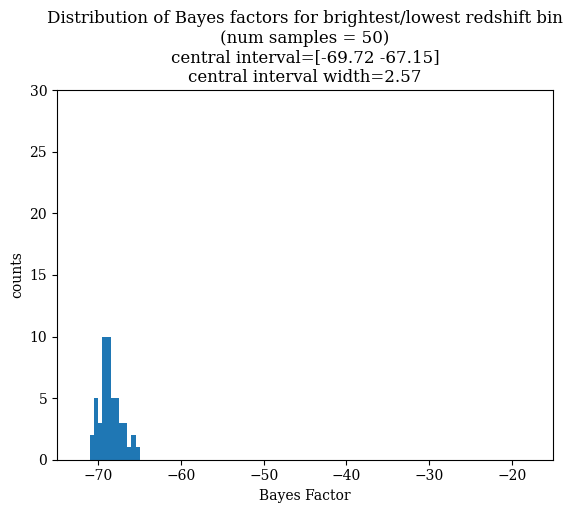

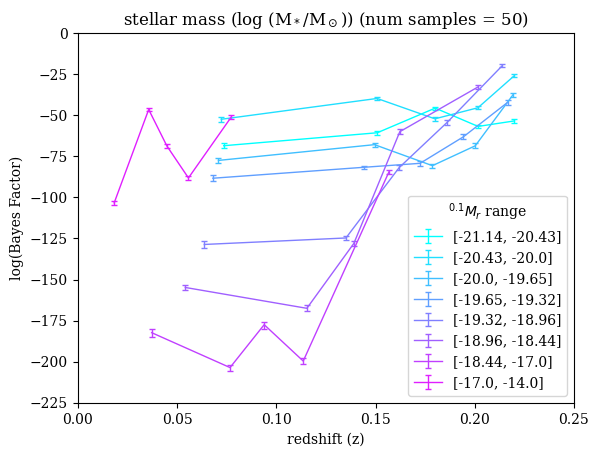

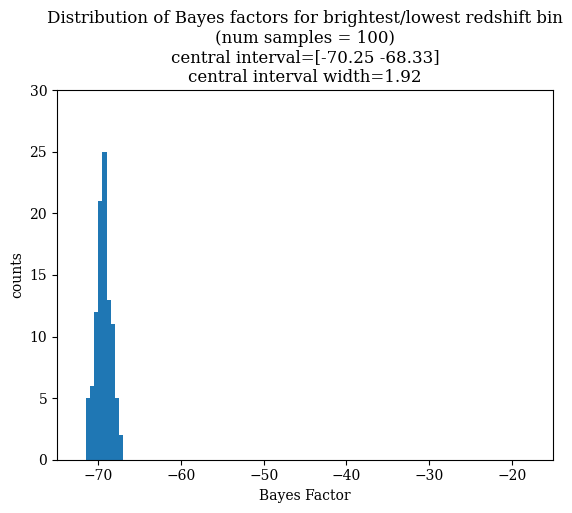

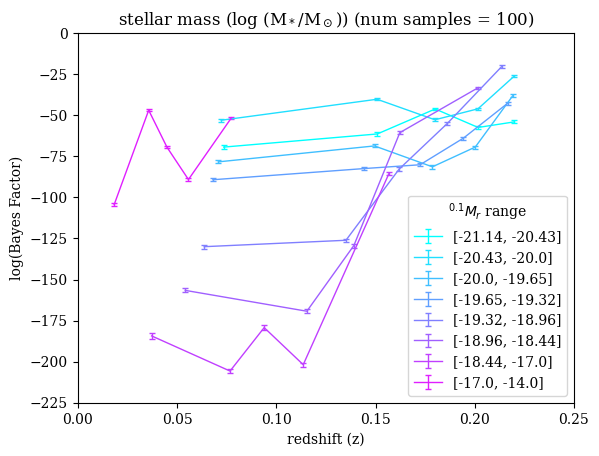

In [132]:

for bf_info_jackknife in jackknife_test:
    title = r'stellar mass (log (M$_*$/M$_\odot$))'
    bf_info = full_bfs[0]
    num_samples = max(bf_info_jackknife.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))
    bfs_total = np.reshape(bf_info[3]['factors'], (-1,5))

    bf_spread = []
    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info_jackknife[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info_jackknife[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info_jackknife[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info_jackknife[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info_jackknife[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        # (8,5)
        bf_spread.append(bfs[0,0])
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]
    #bookmark
    spread_quantile = np.quantile(bf_spread, [.16,.84])
    spread_quantile[0] = mknum(spread_quantile[0])
    spread_quantile[1] = mknum(spread_quantile[1])
    
    plt.hist(bf_spread, bins=np.arange(-75,-15,.5))
    plt.xlim(-75,-15)
    plt.ylim(0,30)
    plt.xlabel('Bayes Factor')
    plt.ylabel('counts')
    spread_range = mknum(np.diff(spread_quantile)[0])
    plt.title('Distribution of Bayes factors for brightest/lowest redshift bin'+f'\n(num samples = {num_samples})\ncentral interval={spread_quantile}\ncentral interval width={spread_range}')
    plt.show()
    for line_index, (bf_total, average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(bfs_total, average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, 
                                           color = rgba, label = f'[{mrmin_fmt}, {mrmax_fmt}]',
                                          capsize=2)
        #plt.scatter(zmid, bf_total, color = rgba, s=1)
        
    plt.legend(title='$^{0.1}M_r$ range')
    plt.xlim(0,.25)
    plt.ylim(-225,0)
    plt.title(title+f' (num samples = {num_samples})')
    plt.xlabel('redshift (z)')
    plt.ylabel('log(Bayes Factor)')
    #plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

In [35]:
# full bfs
num_samples = max(jackknife_full_bfs[0].keys()) + 1
num_mr_bins = 8
average = np.zeros((num_mr_bins, 5, num_samples))
for sample in range (num_samples):

    bfs = np.reshape(jackknife_full_bfs[0][sample]['factors'], (-1,5))
    num_lines = bfs.shape[0]
    
    for line_index, bf in enumerate(bfs):
            #rgba = cmap(line_index/num_lines)
            #zmid = (zmin + zmax)/2
        
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf

In [45]:
# metal bfs
num_samples = max(jackknife_metal_bfs[0].keys()) + 1
num_mr_bins = 8
average = np.zeros((num_mr_bins, 5, num_samples))
for sample in range (num_samples):

    bfs = np.reshape(jackknife_metal_bfs[0][sample]['factors'], (-1,5))
    num_lines = bfs.shape[0]
    
    for line_index, bf in enumerate(bfs):
            #rgba = cmap(line_index/num_lines)
            #zmid = (zmin + zmax)/2
        
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf

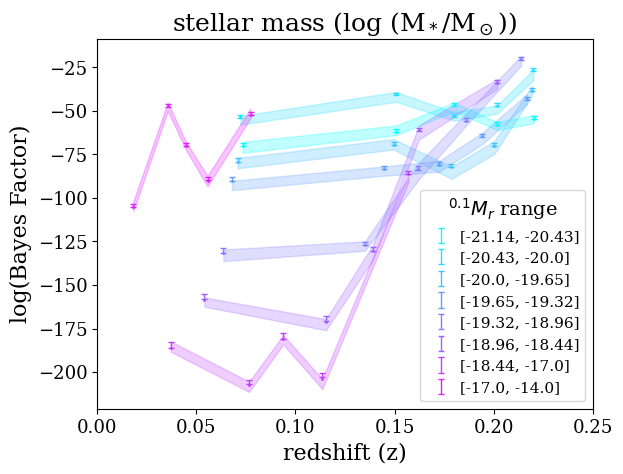

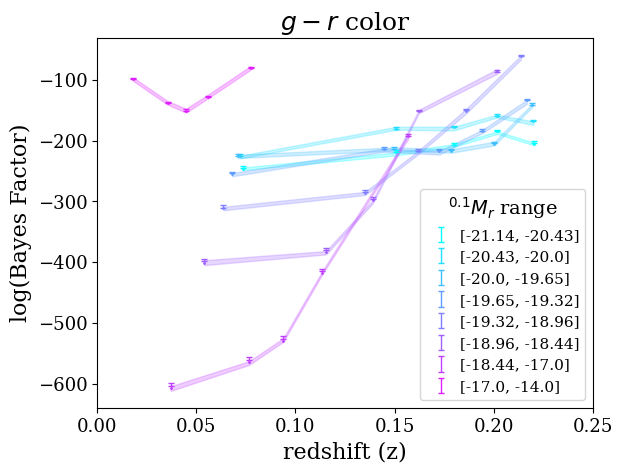

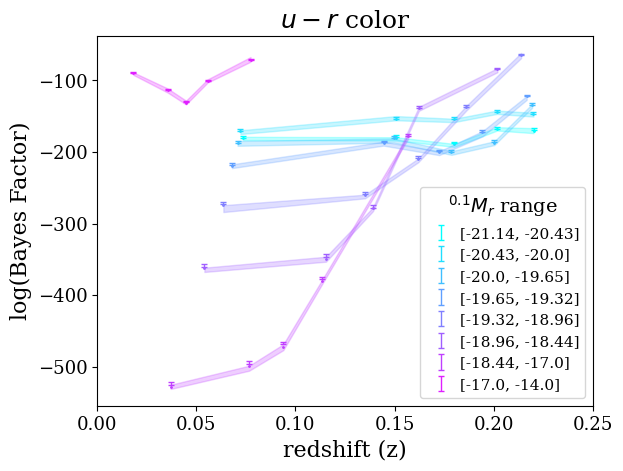

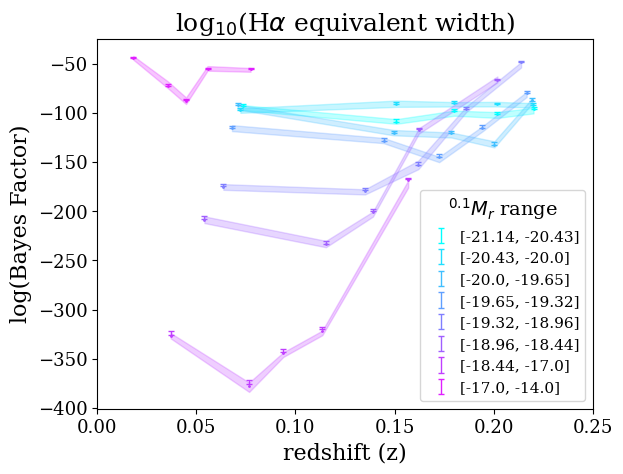

In [73]:

for total_index, (bf_info, bf_info_jackknife, prop_name, title) in enumerate(zip(full_bfs, jackknife_full_bfs,
                          ['log_mstar','g-r','u-r','halpha'],
                         [r'stellar mass (log (M$_*$/M$_\odot$))', r"$g-r$ color", r"$u-r$ color", r"log$_{10}$(H$\alpha$ equivalent width)"]
                        )):
    num_samples = max(bf_info_jackknife.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))
    bfs_total = np.reshape(bf_info[3]['factors'], (-1,5))

    bfs_sys_max = np.array(bfs_total)#np.full(bfs_total.shape, -np.inf)
    bfs_sys_min = np.array(bfs_total)#np.full(bfs_total.shape, np.inf)

    for c in (4,6):
        for max_depth in (5,7):

            sys_iteration = np.reshape(full_bfs_cubes[(c,max_depth)][total_index][3]['factors'], (-1,5))

            bfs_sys_max = np.maximum(bfs_sys_max, sys_iteration)
            bfs_sys_min = np.minimum(bfs_sys_min, sys_iteration)


    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info_jackknife[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info_jackknife[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info_jackknife[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info_jackknife[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info_jackknife[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]

    for line_index, (bf_total, bf_max, bf_min, average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(bfs_total, bfs_sys_max, bfs_sys_min, average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, ls='none',
                                           color = rgba, label = f'[{mrmin_fmt}, {mrmax_fmt}]',
                                          capsize=2)
        plt.scatter(zmid, bf_total, color = rgba, s=1)
        plt.fill_between(zmid, bf_max, bf_min, alpha = 0.25, color = rgba)
        
    plt.legend(title='$^{0.1}M_r$ range', fontsize=11, title_fontsize=14, handletextpad=.2)
    plt.xlim(0,.25)
    plt.title(title,fontsize=18)
    plt.xlabel('redshift (z)', fontsize=16)
    plt.ylabel('log(Bayes Factor)', fontsize=16)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

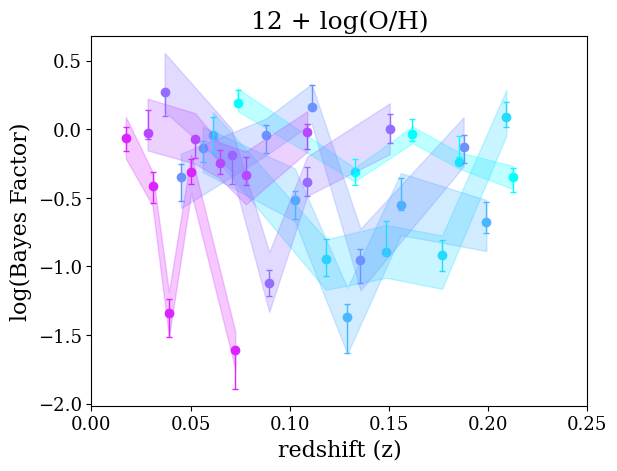

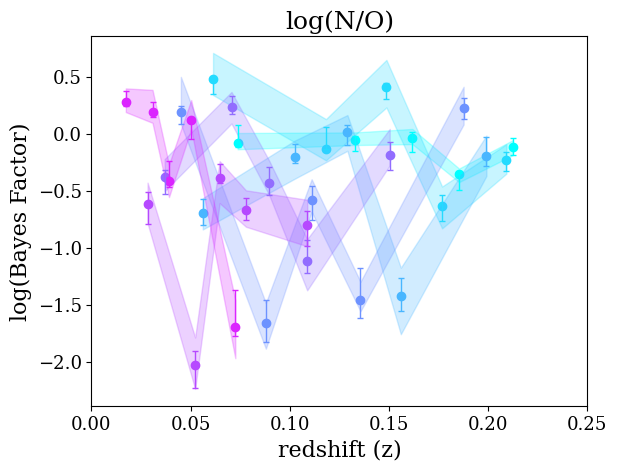

In [62]:


for total_index, (bf_info, bf_info_jackknife, prop_name, title) in enumerate(zip(metal_bfs, jackknife_metal_bfs, 
                          ['oh_p50', 'no'],
                         [r"12 + log(O/H)", r"log(N/O)"]
                        )):
    num_samples = max(bf_info_jackknife.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))
    bfs_total = np.reshape(bf_info[3]['factors'], (-1,5))

    bfs_sys_max = np.array(bfs_total)#np.full(bfs_total.shape, -np.inf)
    bfs_sys_min = np.array(bfs_total)#np.full(bfs_total.shape, np.inf)

    for c in (4,6):
        for max_depth in (5,7):

            sys_iteration = np.reshape(metal_bfs_cubes[(c,max_depth)][total_index][3]['factors'], (-1,5))

            bfs_sys_max = np.maximum(bfs_sys_max, sys_iteration)
            bfs_sys_min = np.minimum(bfs_sys_min, sys_iteration)


    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info_jackknife[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info_jackknife[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info_jackknife[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info_jackknife[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info_jackknife[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]

    for line_index, (bf_total, bf_max, bf_min, average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(bfs_total, bfs_sys_max, bfs_sys_min, average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, ls='none',
                                           color = rgba, label = f'[{mrmin_fmt}, {mrmax_fmt}]',
                                          capsize=2)
        plt.scatter(zmid, bf_total, color = rgba, )
        plt.fill_between(zmid, bf_max, bf_min, alpha = 0.25, color = rgba)
        
    #plt.legend(title='$^{0.1}M_r$ range')
    plt.xlim(0,.25)
    plt.title(title, fontsize=18)
    plt.xlabel('redshift (z)', fontsize=16)
    plt.ylabel('log(Bayes Factor)', fontsize=16)
    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)
    plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

# Generate Bayes factors with jackknife respampling

In [32]:

jackknife_metal_bfs = []

for property in ['oh_p50', 'no']:
    print(property)
    jackknife_metal_bfs.append(
        jackknife_heatmap(property, 100, heatmap_mr_bins_metal, num_z_bins=5, sample='BGS', )
    )

oh_p50
no


In [33]:
# Commented out code only needs to be ran once
"""
#Plot heatmaps
jackknife_full_bfs = []

for property in ['log_mstar','g-r','u-r','halpha']:
    print(property)
    jackknife_full_bfs.append(
        jackknife_heatmap(property, 100, heatmap_mr_bins, num_z_bins=5, sample='BGS', )
    )

import sys
sys.path.insert(1, '/global/homes/h/hrincon/python_tools')
import Util as util
util.dump (jackknife_full_bfs, 'jackknife_full_bfs')

"""
import sys
sys.path.insert(1, '/global/homes/h/hrincon/python_tools')
import Util as util

jackknife_full_bfs = util.load('jackknife_full_bfs')

# Bayes factor for each M_r-z bin + jacknife uncertainty

The Bayes factor for the entire sample may fall outside of the central 68% interval of the jackknife resampling

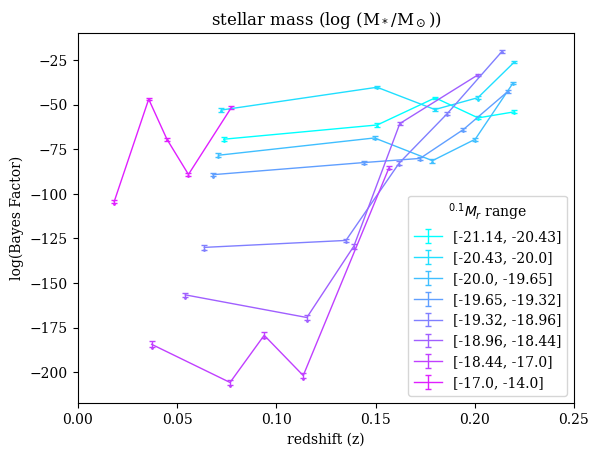

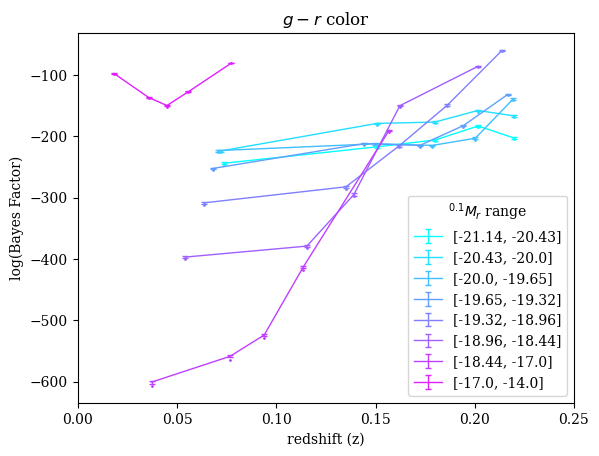

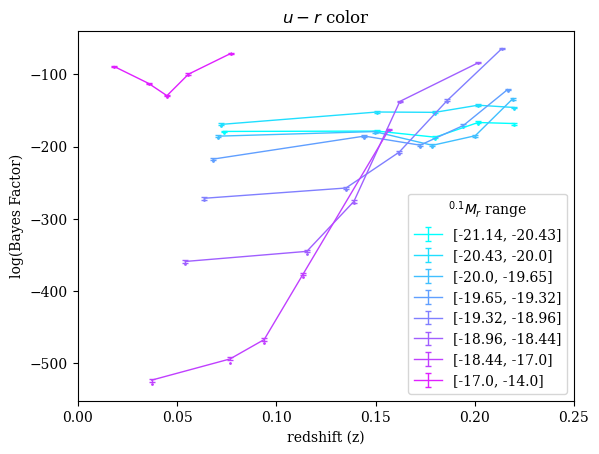

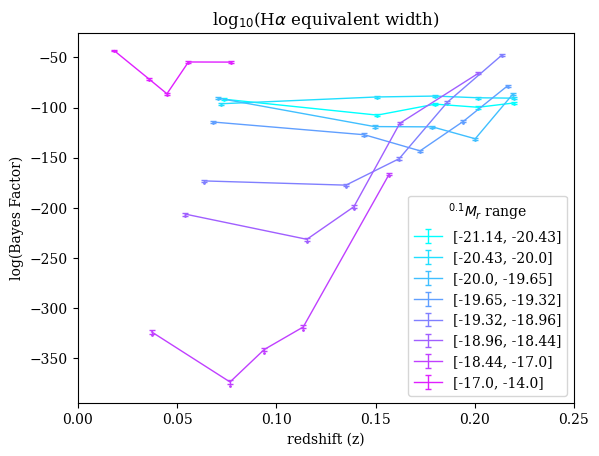

In [144]:

for bf_info, bf_info_jackknife, prop_name, title in zip(full_bfs, jackknife_full_bfs, 
                          ['log_mstar','g-r','u-r','halpha'],
                         [r'stellar mass (log (M$_*$/M$_\odot$))', r"$g-r$ color", r"$u-r$ color", r"log$_{10}$(H$\alpha$ equivalent width)"]
                        ):
    num_samples = max(bf_info_jackknife.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))
    bfs_total = np.reshape(bf_info[3]['factors'], (-1,5))


    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info_jackknife[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info_jackknife[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info_jackknife[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info_jackknife[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info_jackknife[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]

    for line_index, (bf_total, average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(bfs_total, average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, 
                                           color = rgba, label = f'[{mrmin_fmt}, {mrmax_fmt}]',
                                          capsize=2)
        plt.scatter(zmid, bf_total, color = rgba, s=1)
        
    plt.legend(title='$^{0.1}M_r$ range')
    plt.xlim(0,.25)
    plt.title(title)
    plt.xlabel('redshift (z)')
    plt.ylabel('log(Bayes Factor)')
    #plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

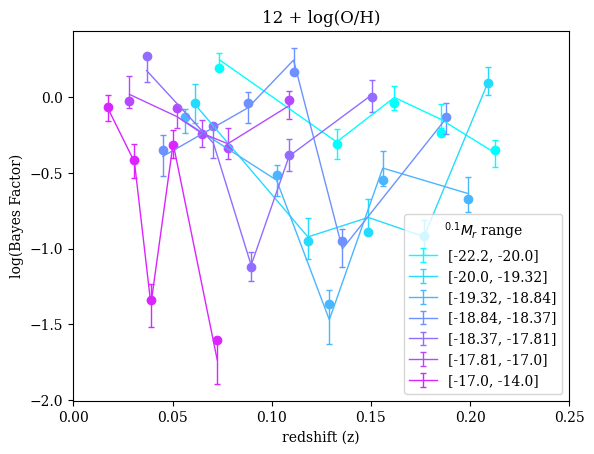

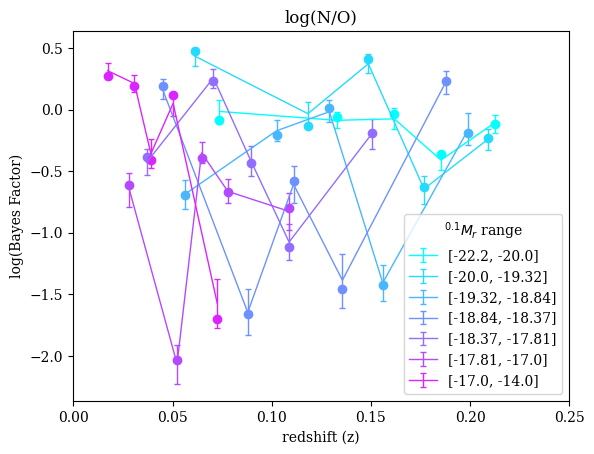

In [145]:

for bf_info, bf_info_jackknife, prop_name, title in zip(metal_bfs, jackknife_metal_bfs, 
                          ['oh_p50', 'no'],
                         [r"12 + log(O/H)", r"log(N/O)"]
                        ):
    num_samples = max(bf_info_jackknife.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))
    bfs_total = np.reshape(bf_info[3]['factors'], (-1,5))


    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info_jackknife[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info_jackknife[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info_jackknife[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info_jackknife[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info_jackknife[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]

    for line_index, (bf_total, average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(bfs_total, average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, 
                                           color = rgba, label = f'[{mrmin_fmt}, {mrmax_fmt}]',
                                          capsize=2)
        plt.scatter(zmid, bf_total, color = rgba, )
        
    plt.legend(title='$^{0.1}M_r$ range')
    plt.xlim(0,.25)
    plt.title(title)
    plt.xlabel('redshift (z)')
    plt.ylabel('log(Bayes Factor)')
    #plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

In [139]:
# code adapted from https://matplotlib.org/stable/gallery/statistics/errorbars_and_boxes.html
def make_error_boxes(xdata, ydata, xerror, yerror, facecolor='r',
                     edgecolor='none', alpha=0.5):

    # Loop over data points; create box from errors at each point
    errorboxes = [Rectangle((x - xe[0], y - ye[0]), xe.sum(), ye.sum())
                  for x, y, xe, ye in zip(xdata, ydata, xerror.T, yerror.T)]

    # Create patch collection with specified colour/alpha
    pc = PatchCollection(errorboxes, facecolor=facecolor, alpha=alpha,
                         edgecolor=edgecolor)

    # Add collection to Axes
    plt.gca().add_collection(pc)

    ## Plot errorbars
    #artists = ax.errorbar(xdata, ydata, xerr=xerror, yerr=yerror,
    #                      fmt='none', ecolor='k')

    #return artists


# Create figure and Axes

# Call function to create error boxes
#_ = make_error_boxes(ax, x, y, xerr, yerr)

# Average of Bayes Factor distrbutions
Here the average Bayes factor from the jacknife respampling is plotted instead of the Bayes factor of the full sample. Versions of the plots are included with and without redshift bin width markers

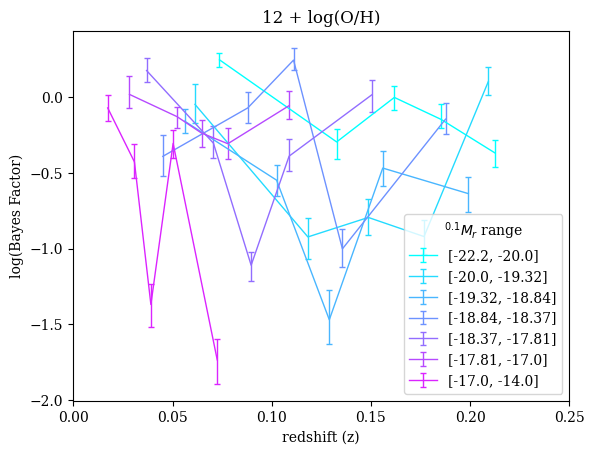

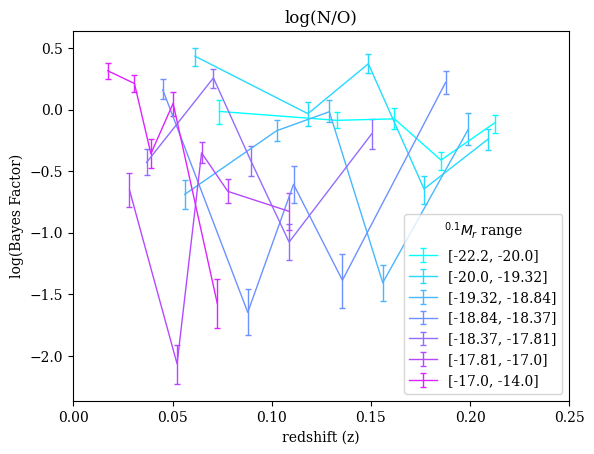

In [146]:

for bf_info, prop_name, title in zip(jackknife_metal_bfs, 
                          ['oh_p50', 'no'],
                         [r"12 + log(O/H)", r"log(N/O)"]
                        ):
    num_samples = max(bf_info.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))


    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]

    for line_index, (average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, 
                                           color = rgba, label = f'[{mrmin_fmt}, {mrmax_fmt}]',
                                          capsize=2)
    plt.legend(title='$^{0.1}M_r$ range')
    plt.xlim(0,.25)
    plt.title(title)
    plt.xlabel('redshift (z)')
    plt.ylabel('log(Bayes Factor)')
    plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

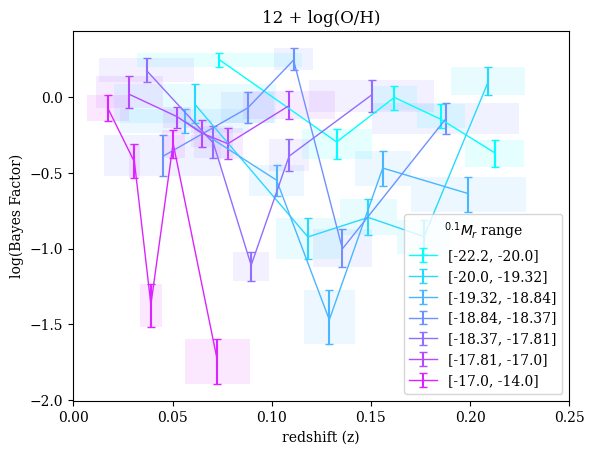

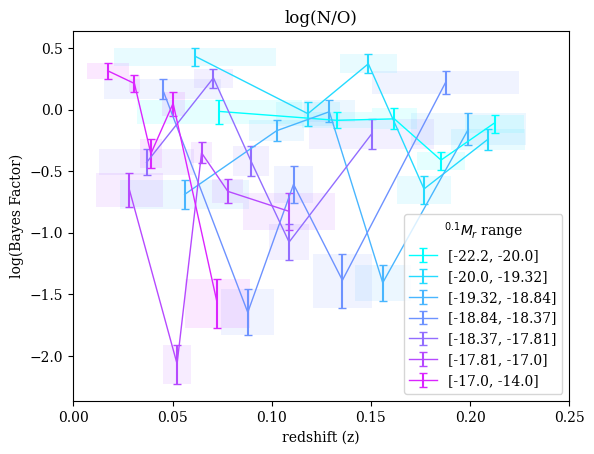

In [147]:

for bf_info, prop_name, title in zip(jackknife_metal_bfs, 
                          ['oh_p50', 'no'],
                         [r"12 + log(O/H)", r"log(N/O)"]
                        ):
    num_samples = max(bf_info.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))


    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]

    for line_index, (average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        """markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, 
                                           color = rgba, label = mknum(mrmid),
                                          capsize=2)"""
        bin_widths = (zmax - zmin)/2
        bin_widths = np.array([bin_widths, bin_widths])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf, yerr = error,
                                           linewidth = 1, elinewidth=1.5, color=rgba, 
                                           label = f'[{mrmin_fmt}, {mrmax_fmt}]', capsize=3)
        #[bar.set_alpha(0.5) for bar in bars]
        #[cap.set_alpha(0.5) for cap in caps]
        make_error_boxes( zmid, bf, bin_widths, error, facecolor=rgba, alpha = 0.1)
        #plt.plot(zmid, np.average(average_mr_bin,axis=1), color = rgba, label = mknum(mrmid))
    plt.legend(title='$^{0.1}M_r$ range')
    plt.xlim(0,.25)
    plt.title(title)
    plt.xlabel('redshift (z)')
    plt.ylabel('log(Bayes Factor)')
    plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife2_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

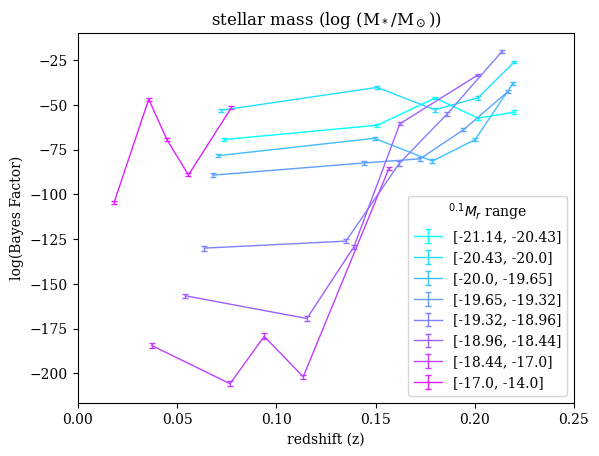

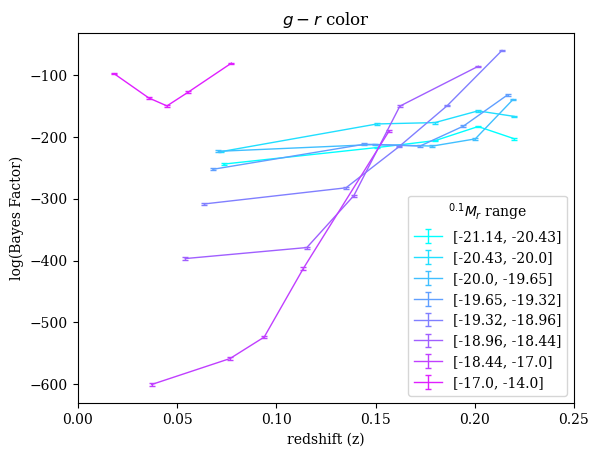

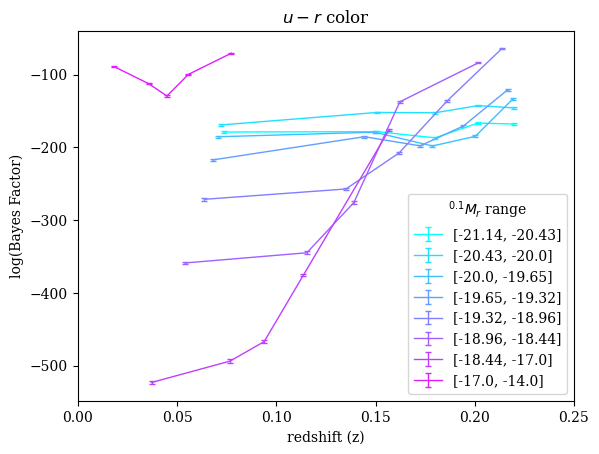

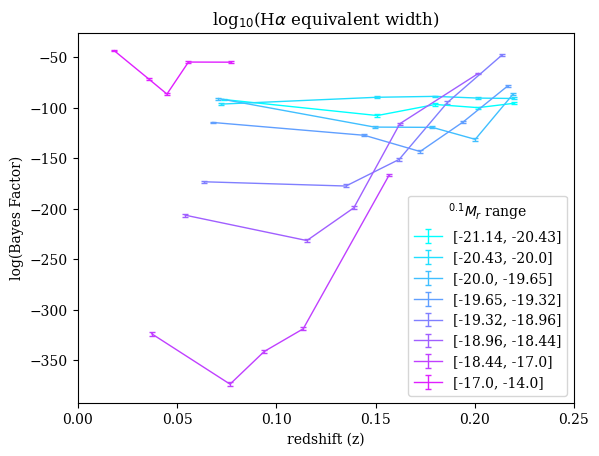

In [148]:

for bf_info, prop_name, title in zip(jackknife_full_bfs, 
                          ['log_mstar','g-r','u-r','halpha'],
                         [r'stellar mass (log (M$_*$/M$_\odot$))', r"$g-r$ color", r"$u-r$ color", r"log$_{10}$(H$\alpha$ equivalent width)"]
                        ):
    num_samples = max(bf_info.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))


    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]

    for line_index, (average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, 
                                           color = rgba, label = f'[{mrmin_fmt}, {mrmax_fmt}]',
                                          capsize=2)
        #bin_widths = (zmax - zmin)/2
        #bin_widths = np.array([bin_widths, bin_widths])
        #markers, caps, bars = plt.errorbar(zmid, bf, xerr=bin_widths, linewidth = 0, elinewidth=1, color=rgba)
        #[bar.set_alpha(0.5) for bar in bars]
        #[cap.set_alpha(0.5) for cap in caps]
        #make_error_boxes( zmid, bf, bin_widths, error, facecolor=rgba)
        #plt.plot(zmid, np.average(average_mr_bin,axis=1), color = rgba, label = mknum(mrmid))
    plt.legend(title='$^{0.1}M_r$ range')
    plt.xlim(0,.25)
    plt.title(title)
    plt.xlabel('redshift (z)')
    plt.ylabel('log(Bayes Factor)')
    plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

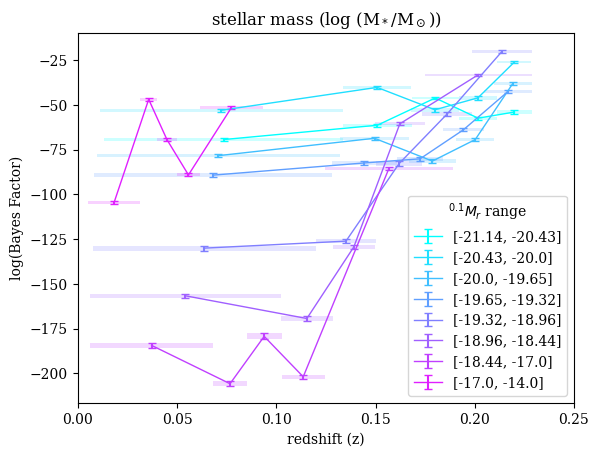

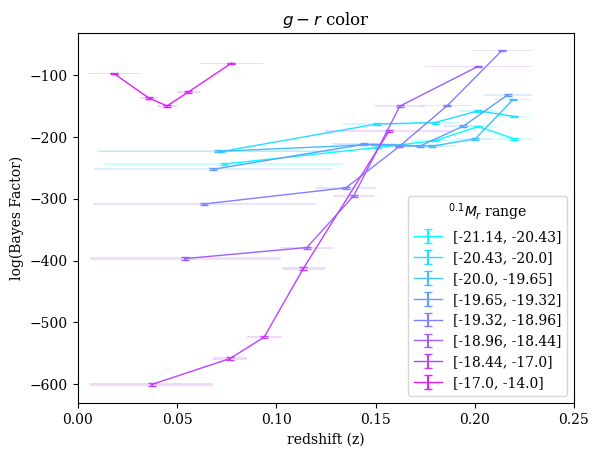

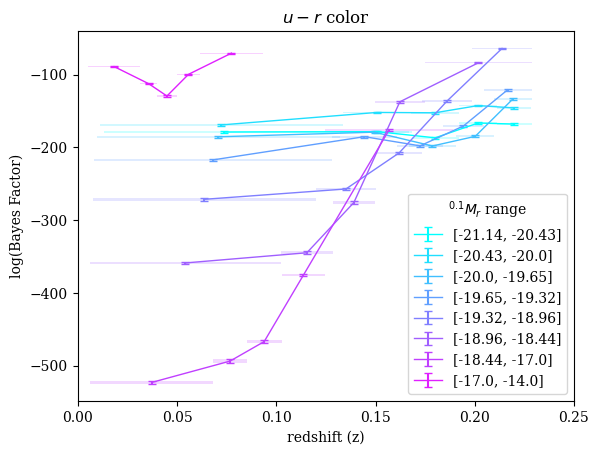

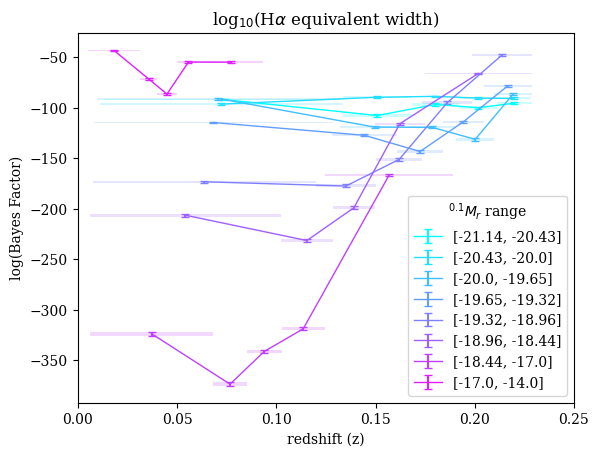

In [149]:

for bf_info, prop_name, title in zip(jackknife_full_bfs, 
                          ['log_mstar','g-r','u-r','halpha'],
                         [r'stellar mass (log (M$_*$/M$_\odot$))', r"$g-r$ color", r"$u-r$ color", r"log$_{10}$(H$\alpha$ equivalent width)"]
                        ):
    num_samples = max(bf_info.keys()) + 1
    num_mr_bins = 8

    average = np.zeros((num_mr_bins, 5, num_samples))


    for sample in range (num_samples):
    
        bfs = np.reshape(bf_info[sample]['factors'], (-1,5))
        zmins = np.reshape(bf_info[sample]['zmin'], (-1,5))
        zmaxs = np.reshape(bf_info[sample]['zmax'], (-1,5))
        mrmins = np.reshape(bf_info[sample]['mrmin'], (-1,5))[:,0]
        mrmaxs = np.reshape(bf_info[sample]['mrmax'], (-1,5))[:,0]
        mrmids = (mrmins + mrmaxs)/2
        num_lines = bfs.shape[0]

        
        
        for line_index, (bf, zmin, zmax, mrmid) in enumerate(zip(bfs, zmins, zmaxs, mrmids)):
            rgba = cmap(line_index/num_lines)
            zmid = (zmin + zmax)/2
            #error = (zmax - zmin)/2
            #m, b = np.polyfit(zmid, bf, 1)
            #plt.plot(zmid, bf, color = rgba, label = f'{mknum(mrmid)}, {mknum(b)}')
            #plt.scatter(zmid, bf, color = rgba)
            average[line_index,:,sample] = bf
            #markers, caps, bars = plt.errorbar(zmid, bf, xerr=error, linewidth = 0, elinewidth=1)
            #[bar.set_alpha(0.5) for bar in bars]
            #[cap.set_alpha(0.5) for cap in caps]

    for line_index, (average_mr_bin, zmin, zmax, mrmin, mrmax) in enumerate(zip(average, zmins, zmaxs, mrmins, mrmaxs)):
        rgba = cmap(line_index/num_lines)
        zmid = (zmin + zmax)/2
        quantiles = np.quantile(average_mr_bin, [.16,.84], axis=1)
        bf = np.average(average_mr_bin,axis=1)
        error = np.array([bf - quantiles[0], quantiles[1] - bf])
        """markers, caps, bars = plt.errorbar(zmid, bf
                                           , yerr=error, linewidth = 1, elinewidth=1, 
                                           color = rgba, label = mknum(mrmid),
                                          capsize=2)"""
        bin_widths = (zmax - zmin)/2
        bin_widths = np.array([bin_widths, bin_widths])
        mrmin_fmt = mknum(mrmin)
        mrmax_fmt = mknum(mrmax)
        markers, caps, bars = plt.errorbar(zmid, bf, yerr = error,
                                           linewidth = 1, elinewidth=1.5, color=rgba, 
                                           label = f'[{mrmin_fmt}, {mrmax_fmt}]', capsize=3)
        #[bar.set_alpha(0.5) for bar in bars]
        #[cap.set_alpha(0.5) for cap in caps]
        make_error_boxes( zmid, bf, bin_widths, error, facecolor=rgba, alpha = 0.2)
        #plt.plot(zmid, np.average(average_mr_bin,axis=1), color = rgba, label = mknum(mrmid))
    plt.legend(title='$^{0.1}M_r$ range')
    plt.xlim(0,.25)
    plt.title(title)
    plt.xlabel('redshift (z)')
    plt.ylabel('log(Bayes Factor)')
    plt.savefig(f"/global/homes/h/hrincon/galaxy_environment/images/jackknife2_{prop_name}.pdf", bbox_inches = "tight", dpi=400)
    plt.show()

### Plotting with Histograms

normalized counts

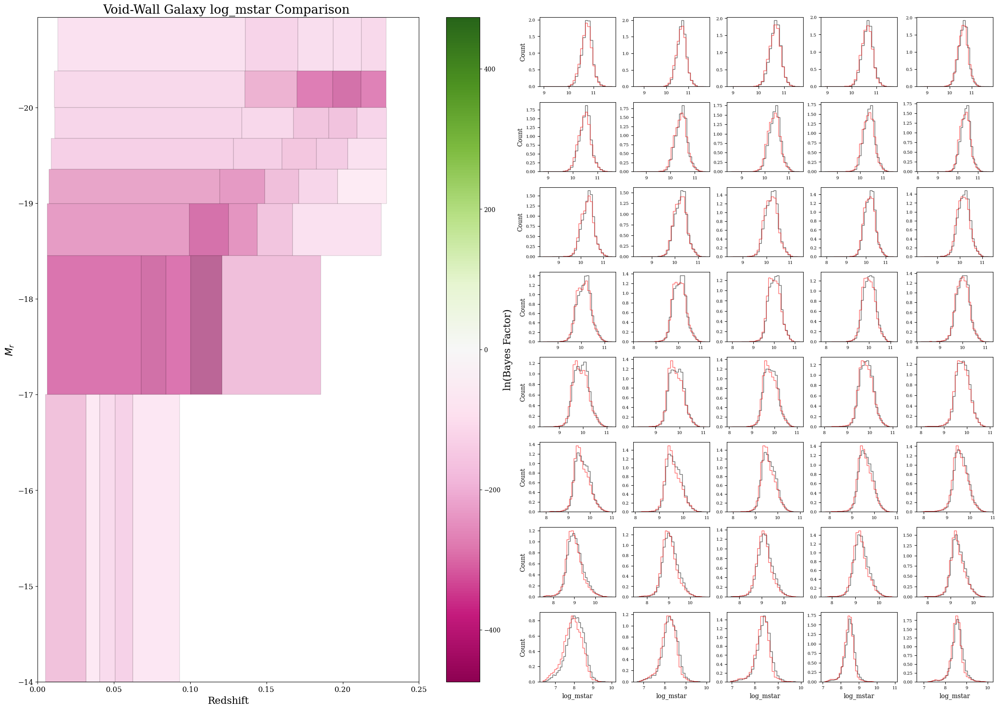

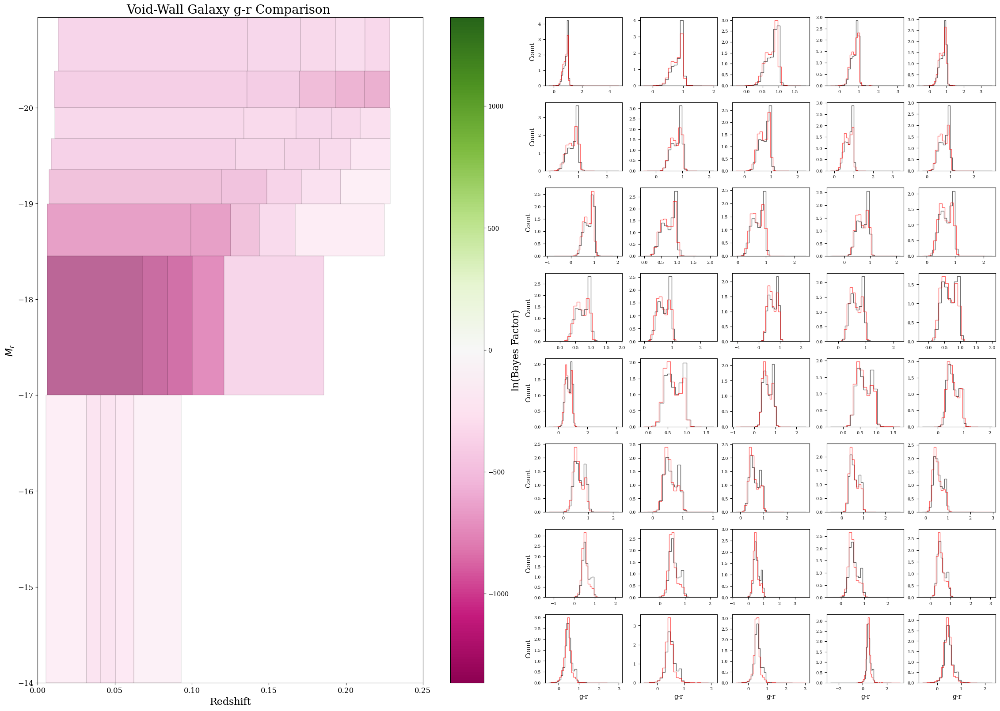

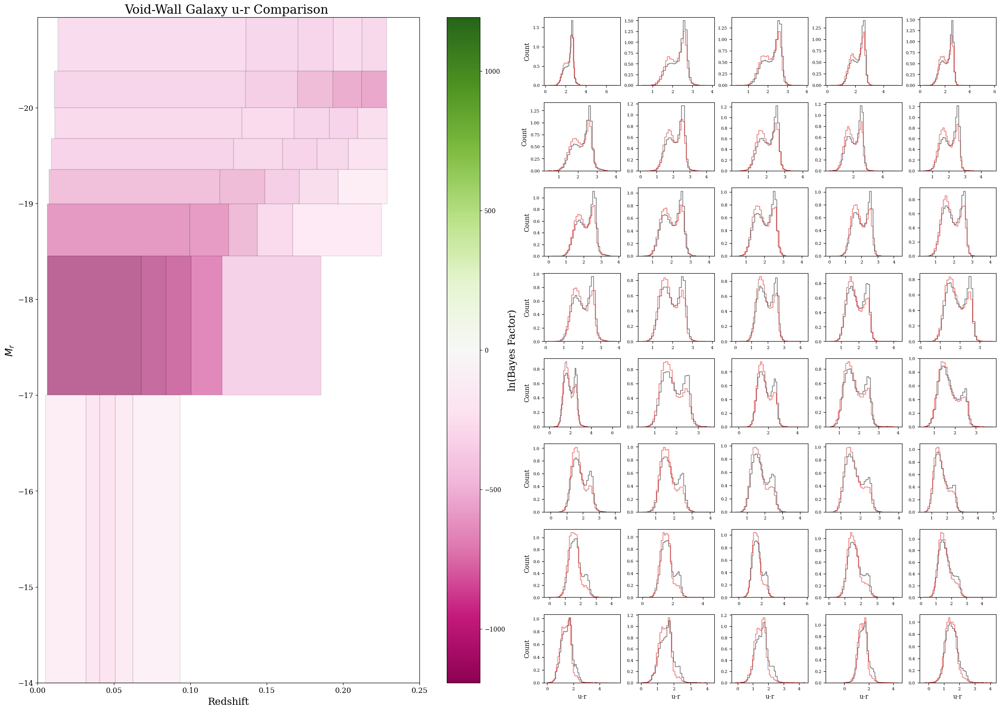

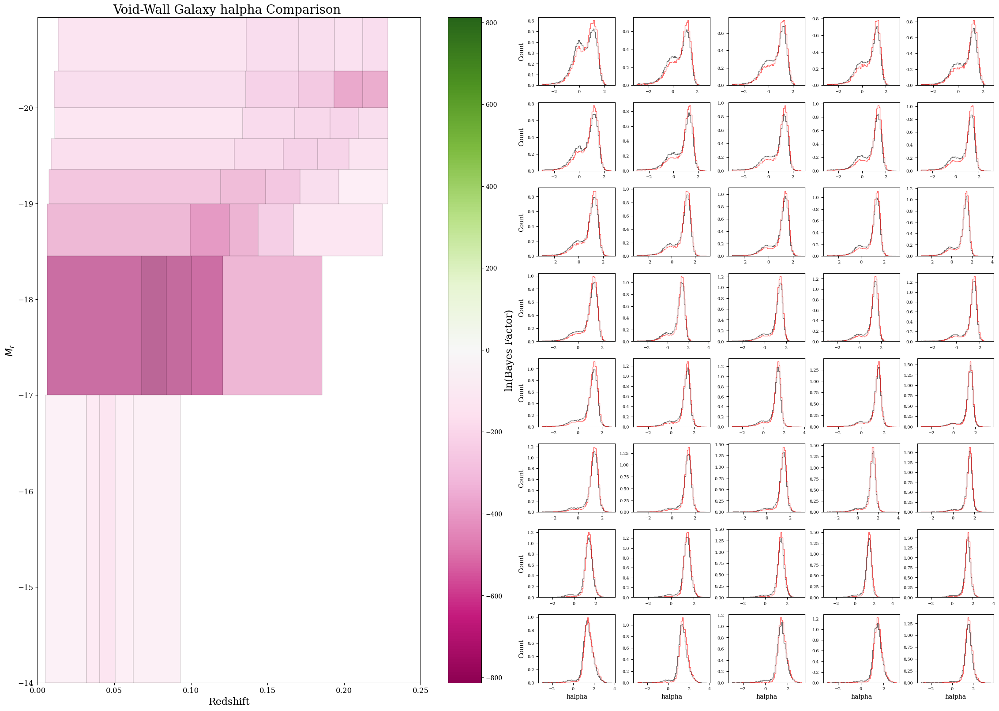

In [155]:
#Plot heatmap and density histograms
for property in ['log_mstar','g-r','u-r','halpha']:
    plot_heatmap_and_hist(property, heatmap_mr_bins, num_z_bins=5, sample='BGS')

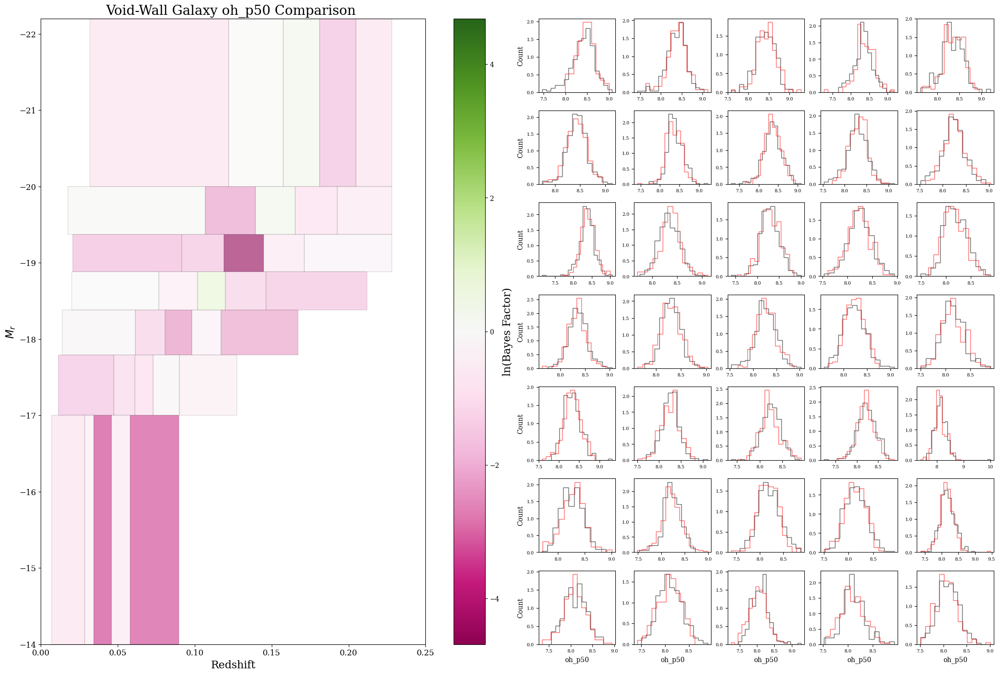

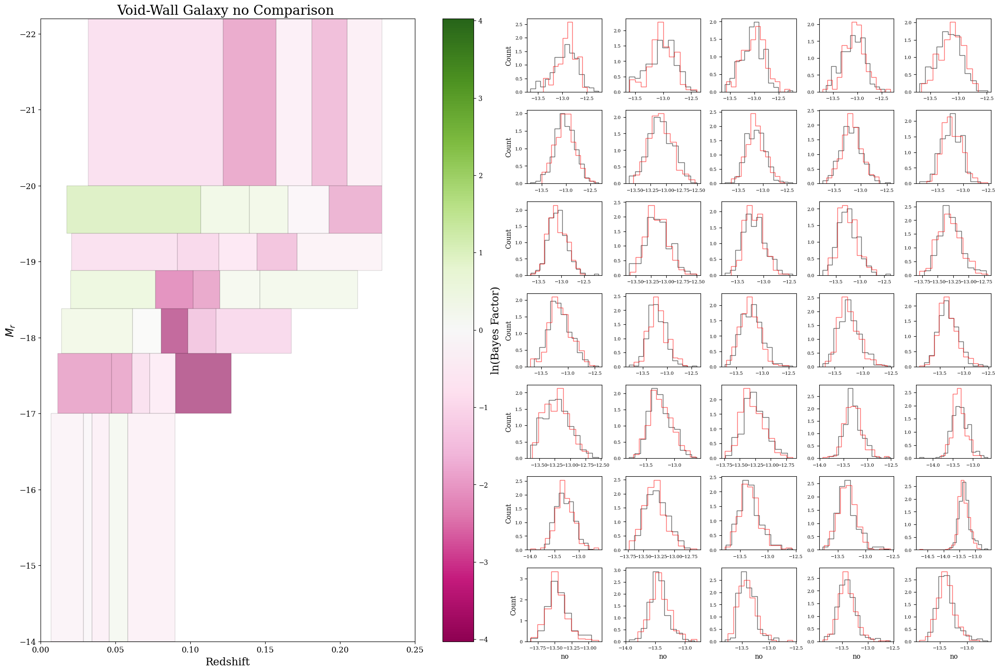

In [193]:
#Plot Metallicity heatmaps and density histograms
for property in ['oh_p50', 'no']:
    plot_heatmap_and_hist(property, heatmap_mr_bins_metal, num_z_bins=5, sample='BGS')

absolute counts

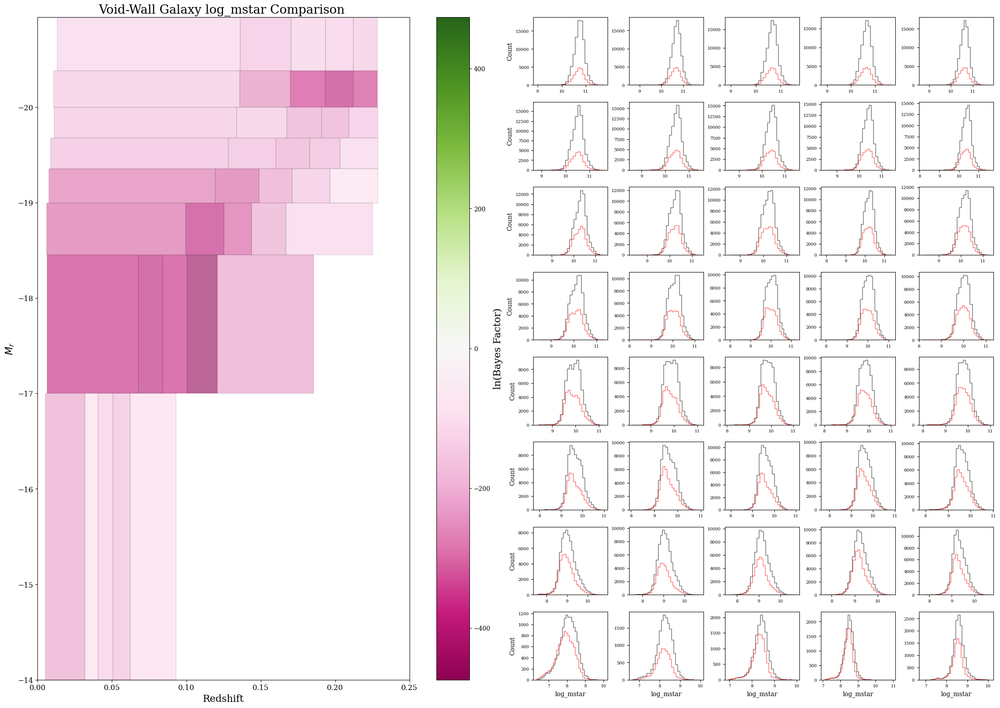

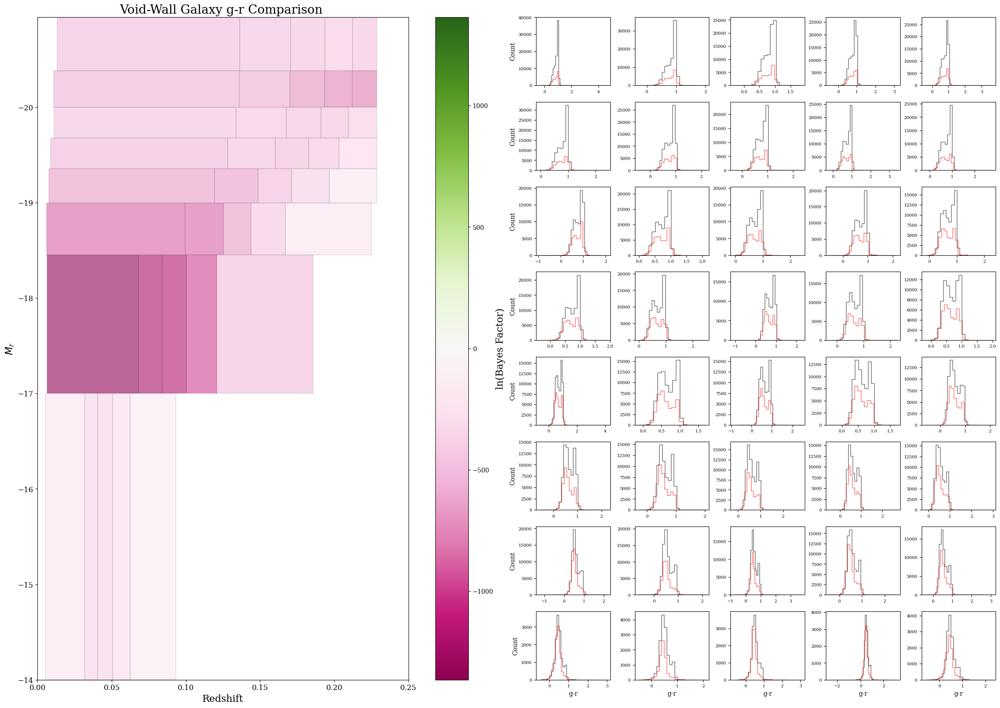

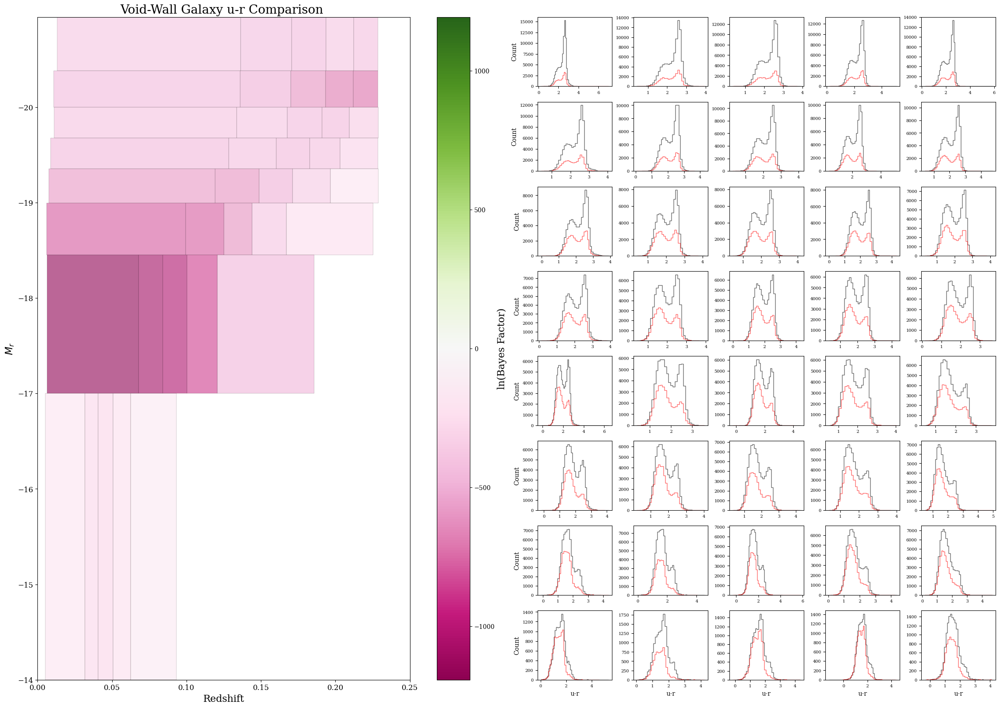

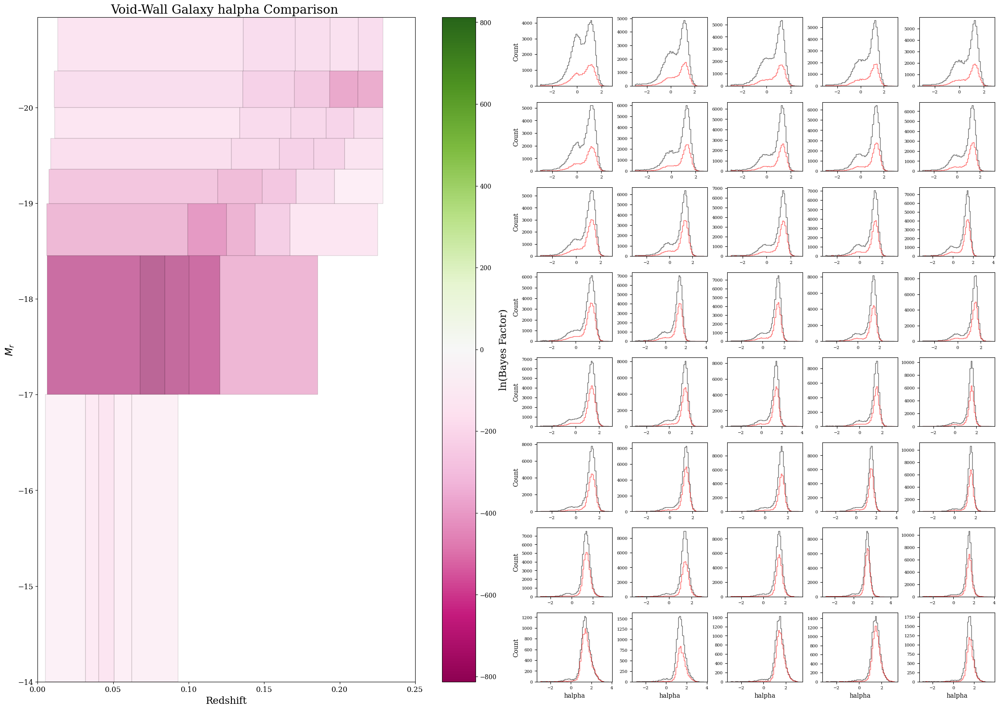

In [153]:
#Plot heatmap and counts histograms
for property in ['log_mstar','g-r','u-r','halpha']:
    plot_heatmap_and_hist(property, heatmap_mr_bins, num_z_bins=5, sample='BGS', density = False)

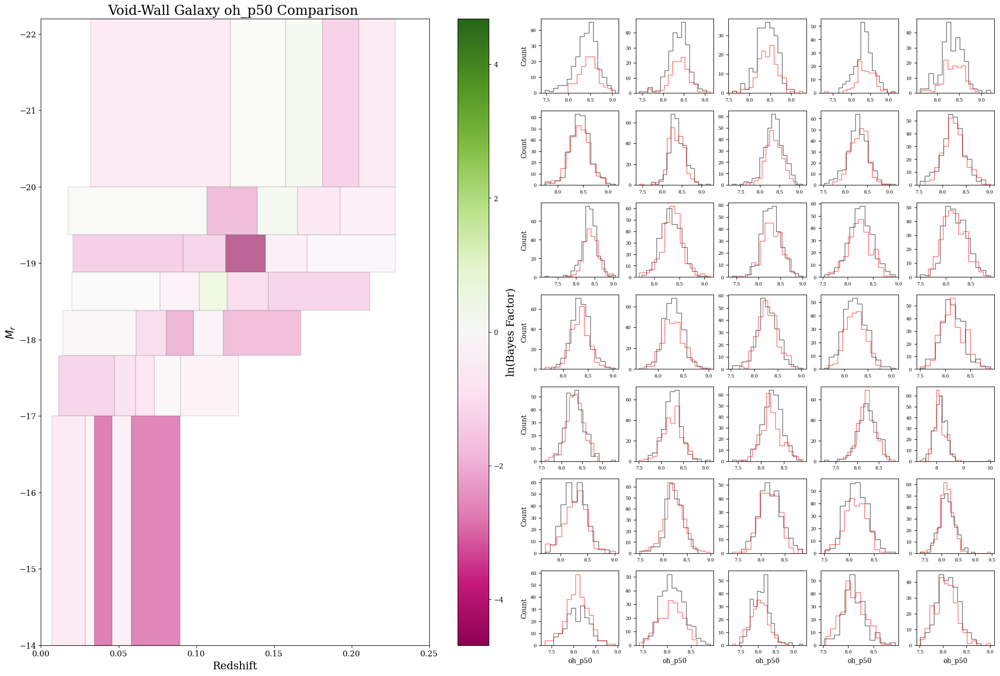

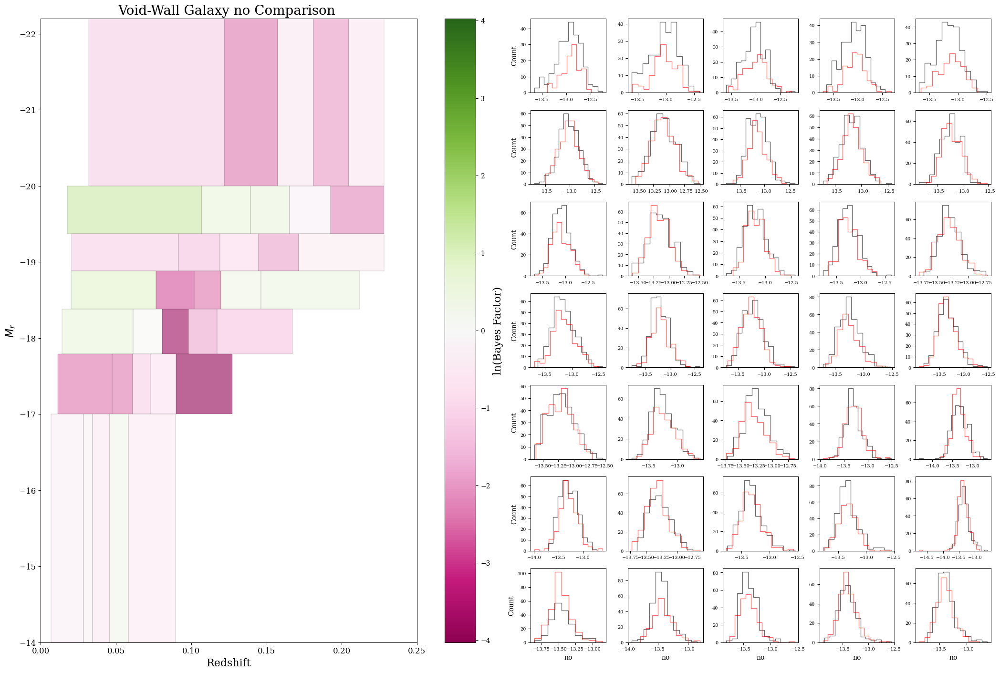

In [194]:
#Plot Metallicity heatmaps and counts histograms
for property in ['oh_p50', 'no']:
    plot_heatmap_and_hist(property, heatmap_mr_bins_metal, num_z_bins=5, sample='BGS', density = False)

# Miscellaneous

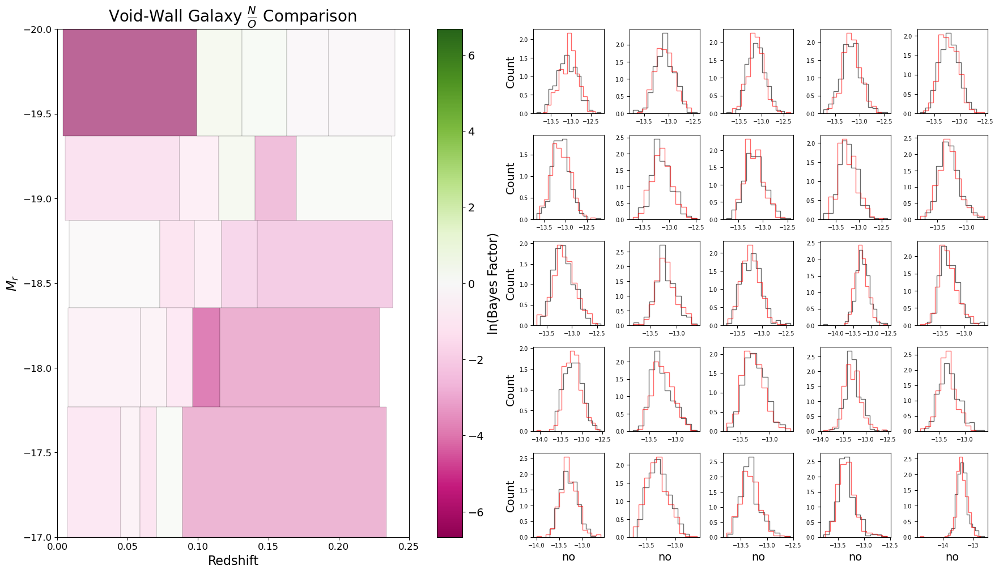

In [52]:
plot_heatmap_and_hist('no', num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-17, sample='BGS', lim17 = False)

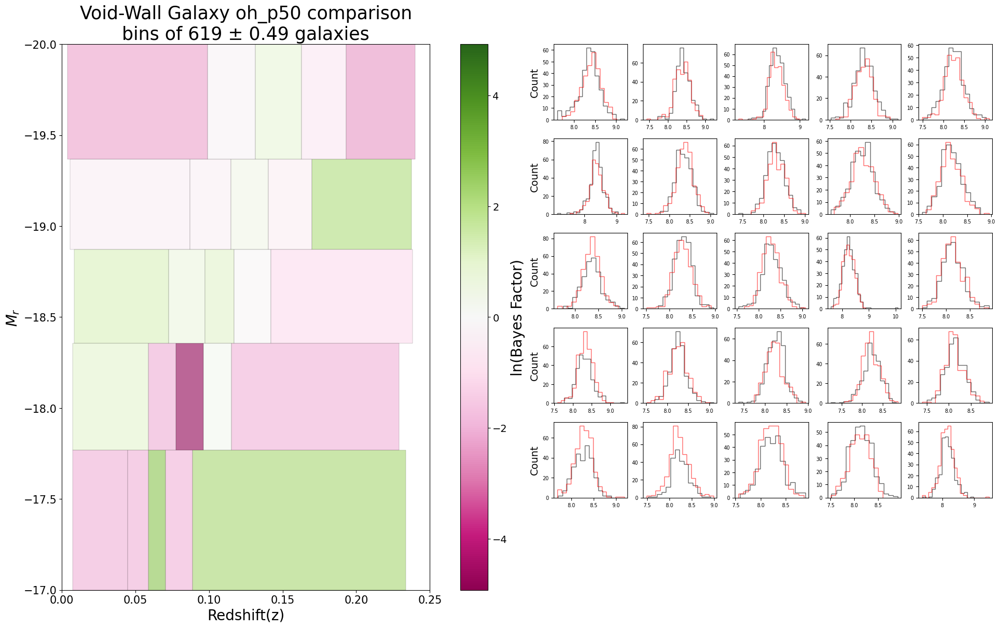

In [27]:
plot_heatmap_and_hist('oh_p50', num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-17, sample='BGS', lim17 = False)

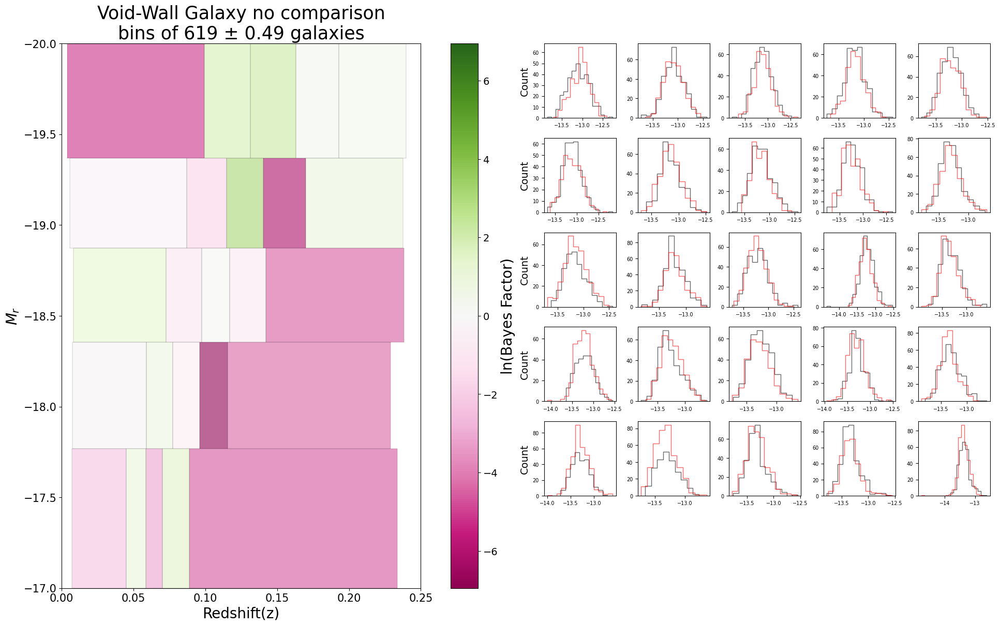

In [29]:
plot_heatmap_and_hist('no', num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-17, sample='BGS', lim17 = False)

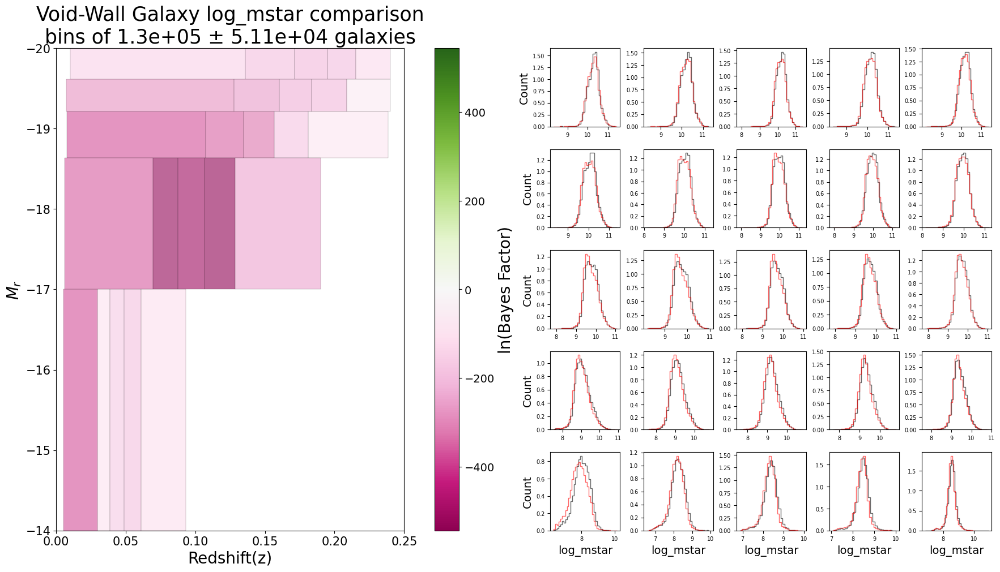

In [21]:
plot_heatmap_and_hist('log_mstar', num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-14, sample='BGS')

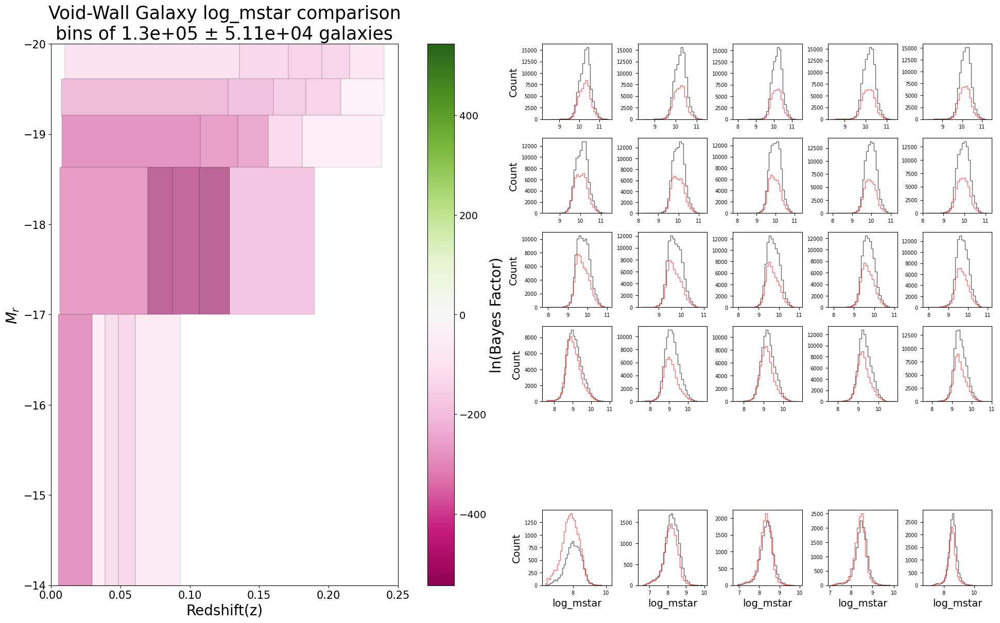

In [31]:
plot_heatmap_and_hist('log_mstar', num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-14, sample='BGS')

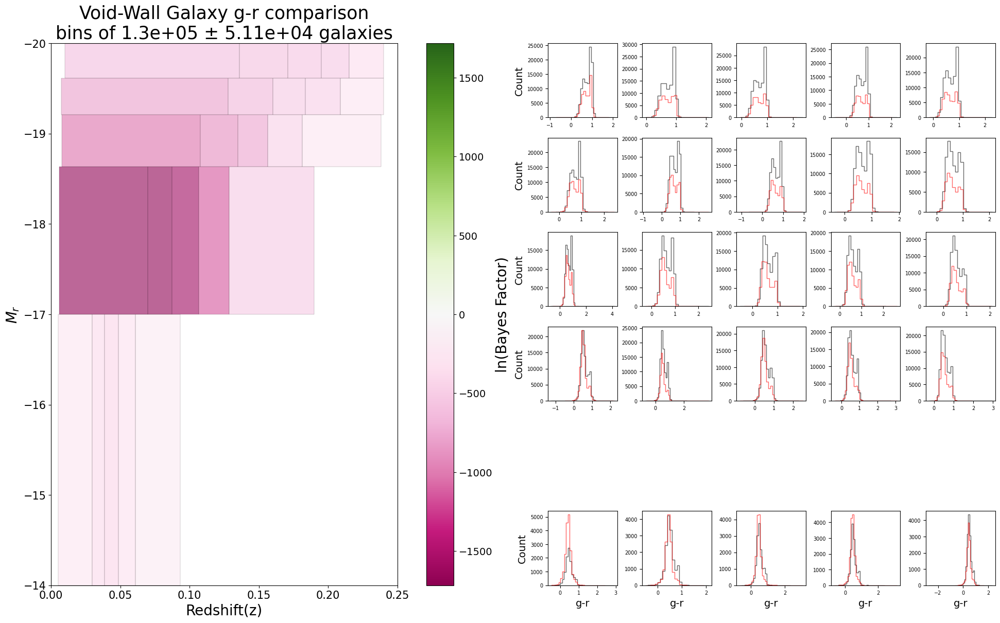

In [32]:
plot_heatmap_and_hist('g-r', num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-14, sample='BGS')

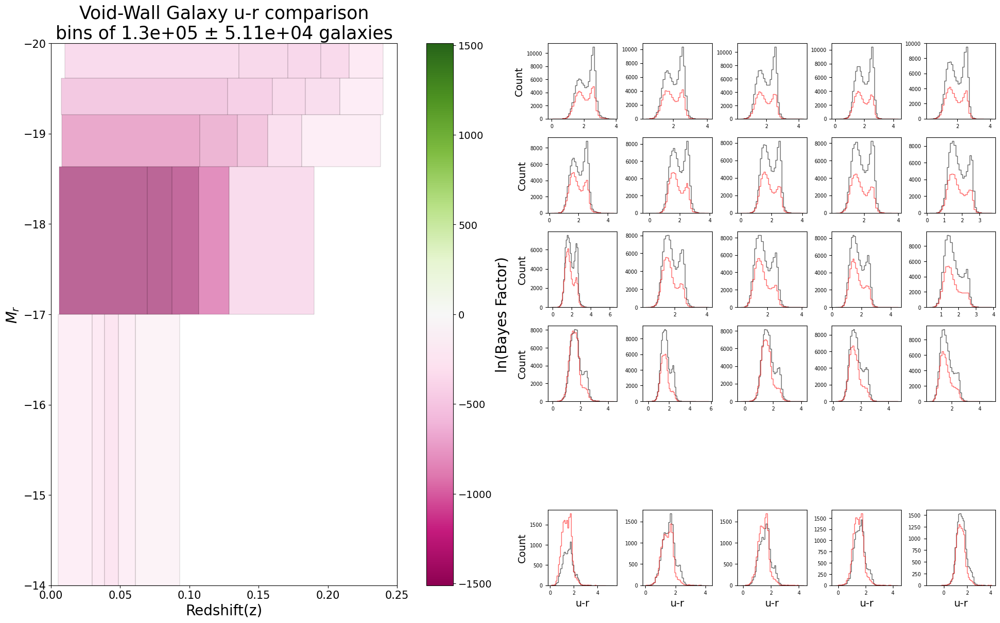

In [33]:
plot_heatmap_and_hist('u-r', num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-14, sample='BGS')

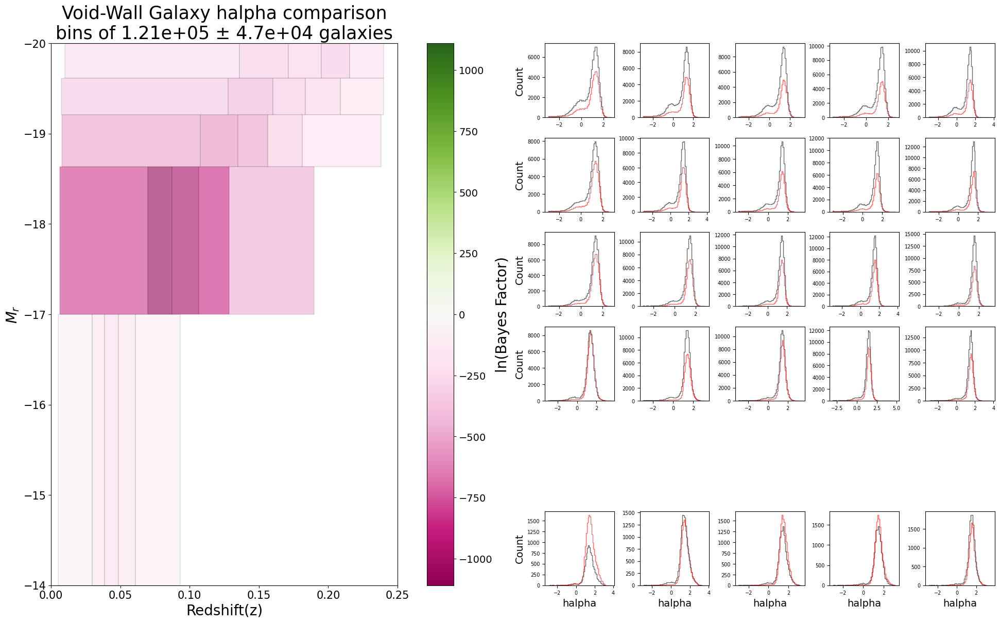

In [34]:
plot_heatmap_and_hist('halpha', num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-14, sample='BGS')

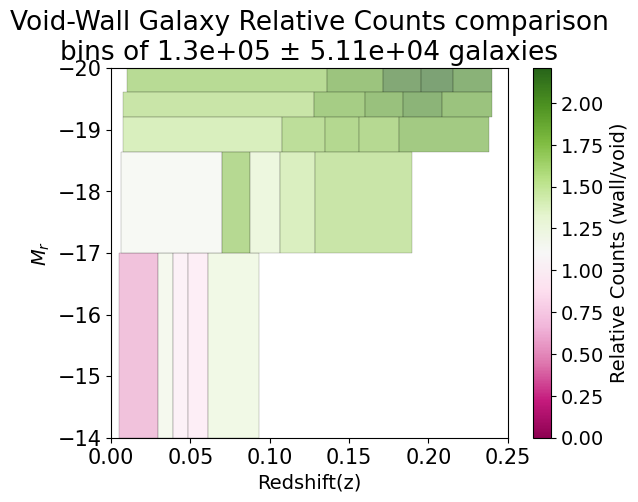

In [24]:
plot_relative_counts(num_mr_bins=5, num_z_bins=5, color='PiYG', sample='BGS')

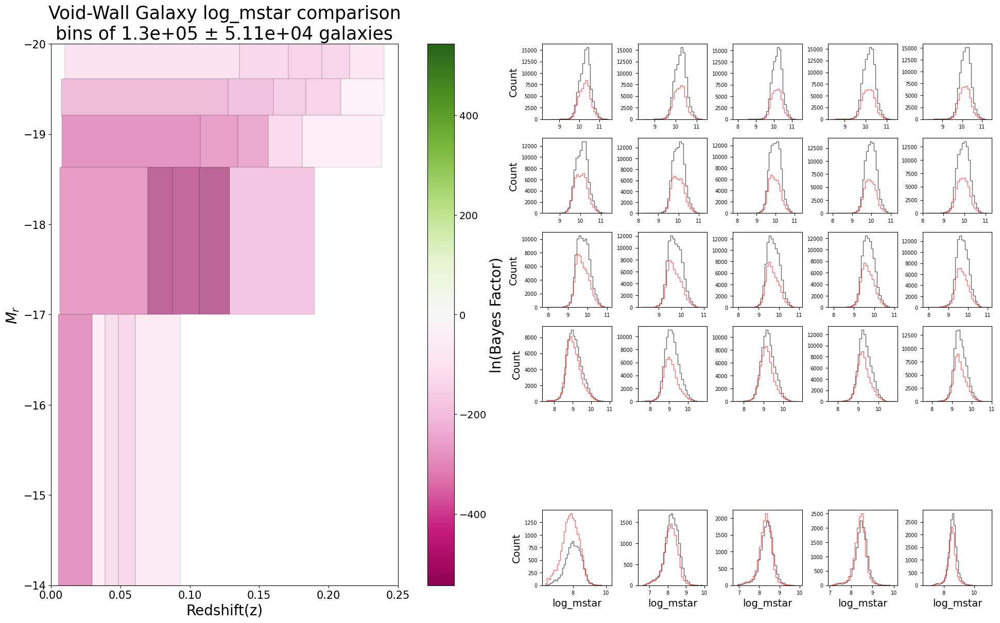

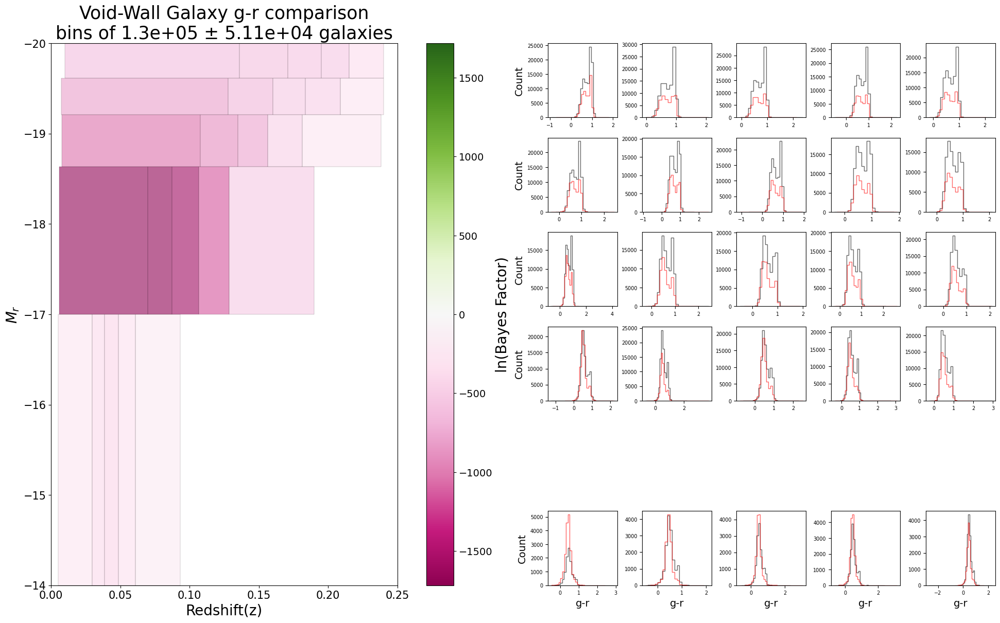

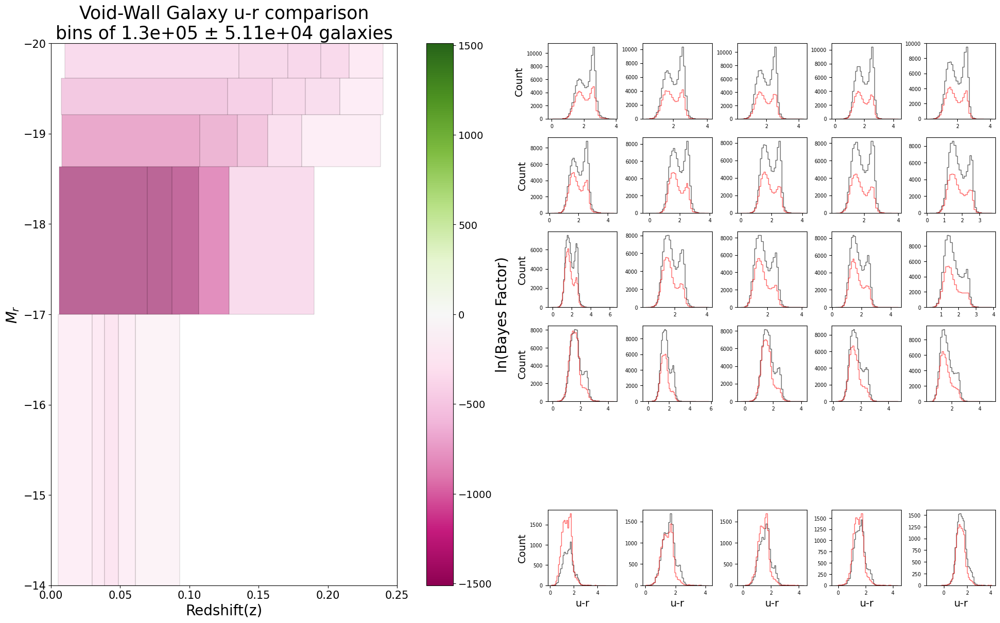

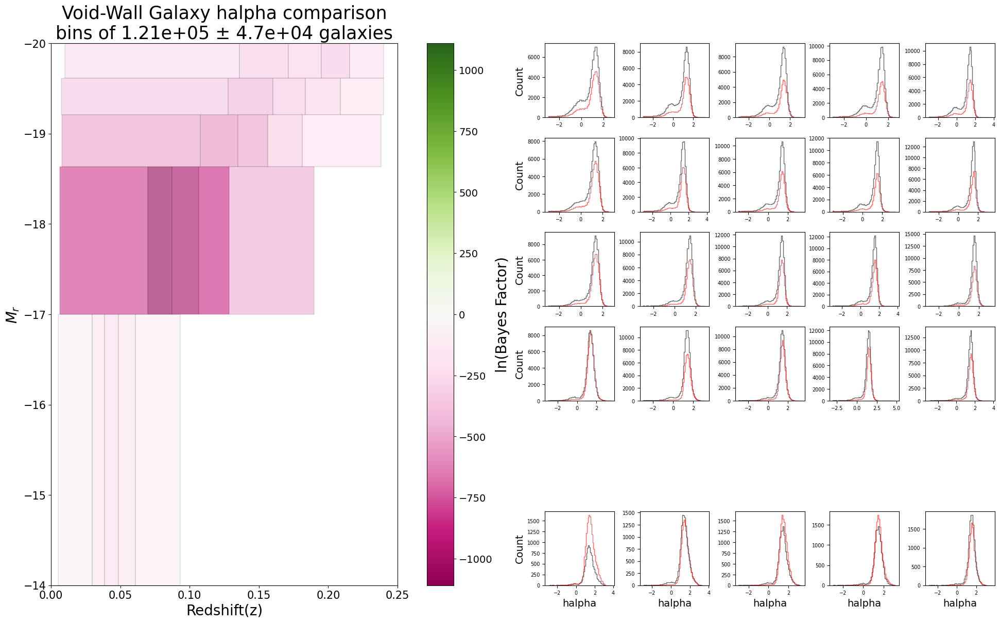

In [26]:
for variable in ['log_mstar','g-r','u-r','halpha']:
    plot_heatmap_and_hist(variable, num_mr_bins=5, num_z_bins=5, mr_min=-20, mr_max=-14, sample='BGS')

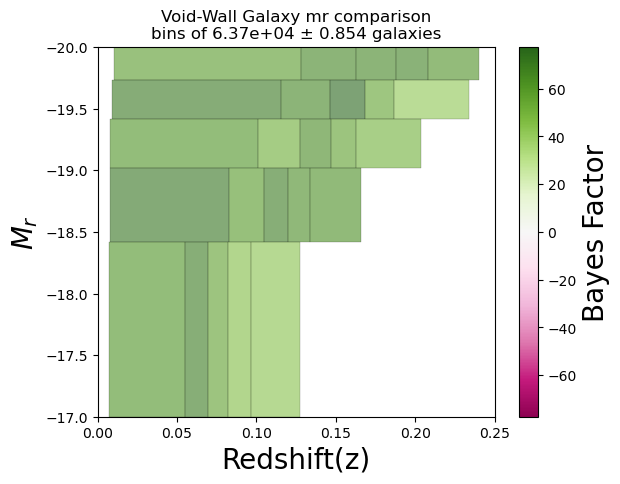

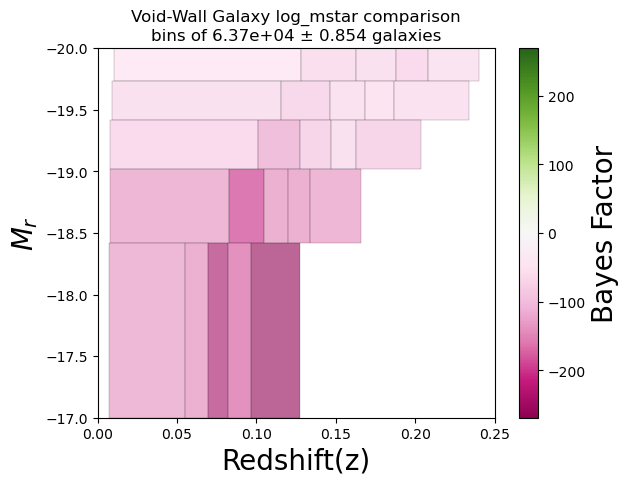

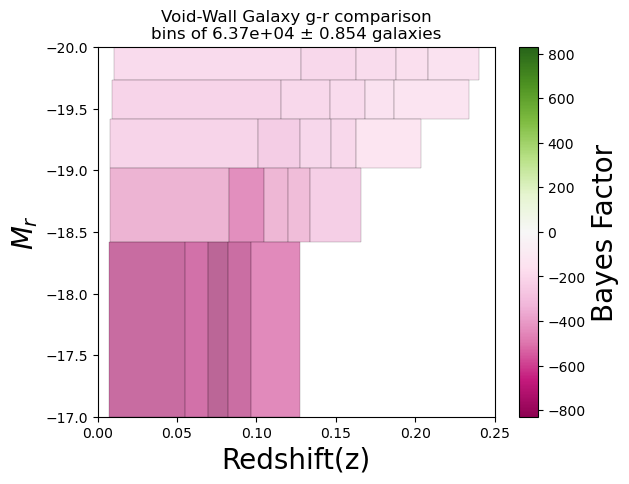

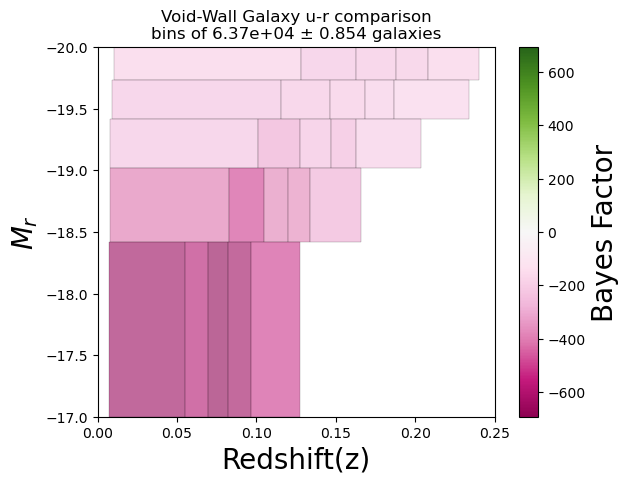

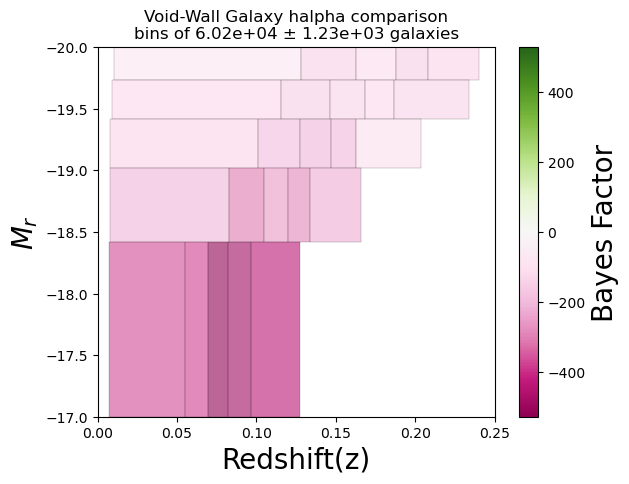

In [12]:
for variable in ['mr','log_mstar','g-r','u-r','halpha']:
    plot_bayes_factor_heatmap(variable, num_mr_bins=6, num_z_bins=6, linewidth=.2, axsize=20, color='PiYG')

In [52]:
def check_sample_binning (mr_min=-20, mr_max=-17, sample= 'BGS', num_mr_bins=5, num_z_bins=5):

    plt.figure(figsize=(5, 4), dpi=200, facecolor='none')
    
    void_property = get_property('mr', 'VF', 'void', sample)
    wall_property = get_property('mr', 'VF', 'wall', sample)
    void_redshift = get_property('z', 'VF', 'void', sample)
    wall_redshift = get_property('z', 'VF', 'wall',sample)
    all_redshift = get_property('z', 'VF', 'all',sample)
    void_mr = get_property('mr', 'VF', 'void', sample)
    wall_mr = get_property('mr', 'VF', 'wall', sample)
    all_mr = get_property('mr', 'VF', 'all', sample)
    
    counts=[] 
    counts_wall = []
    counts_void = []
    
    mr_mask = (all_mr >= mr_min) & (all_mr <= mr_max)
    mr_bins = np.quantile(all_mr[mr_mask],
                            np.linspace(0, 1, num_mr_bins+1))

    for mrmin, mrmax in zip(mr_bins[:-1], mr_bins[1:]):
        # Determine redshift bins
        void_pre_bin = get_mr_z_bin(void_redshift, 0, np.inf, void_mr, mrmin, mrmax, void_redshift, 'redshift')
        wall_pre_bin = get_mr_z_bin(wall_redshift, 0, np.inf, wall_mr, mrmin, mrmax, wall_redshift, 'redshift')
        combined_pre_bin = get_mr_z_bin(all_redshift, 0, np.inf, all_mr, mrmin, mrmax, all_redshift, 'redshift')

        if len(combined_pre_bin) == 0:
            continue

        z_bins = np.quantile(combined_pre_bin, np.linspace(0, 1, num_z_bins+1))

        for zmin, zmax in zip(z_bins[:-1], z_bins[1:]):
            void_bin = get_mr_z_bin(void_redshift, zmin, zmax, void_mr, mrmin, mrmax, void_property, 'mr')
            wall_bin = get_mr_z_bin(wall_redshift, zmin, zmax, wall_mr, mrmin, mrmax, wall_property, 'mr')
            
            rect = Rectangle(
                (zmin, mrmin),               # lower-left corner
                zmax - zmin,               
                mrmax - mrmin,               
                linewidth=1,
                edgecolor='red',
                facecolor='none',
                alpha=0.8
            )
    
            plt.gca().add_patch(rect)
    
    plt.scatter(all_redshift, all_mr, s=.000005, color='black', alpha =.6)
    plt.xlabel('Redshift', fontsize = 16, color = 'whitesmoke')
    plt.xlim(0, .24)
    plt.ylabel(r'$M_r$', fontsize = 16, color = 'whitesmoke')
    plt.ylim(mr_max,mr_min)
    plt.tick_params(axis='both', labelcolor='whitesmoke', color = 'whitesmoke')
    plt.title('BGS Galaxies', fontsize = 20, color = 'whitesmoke')


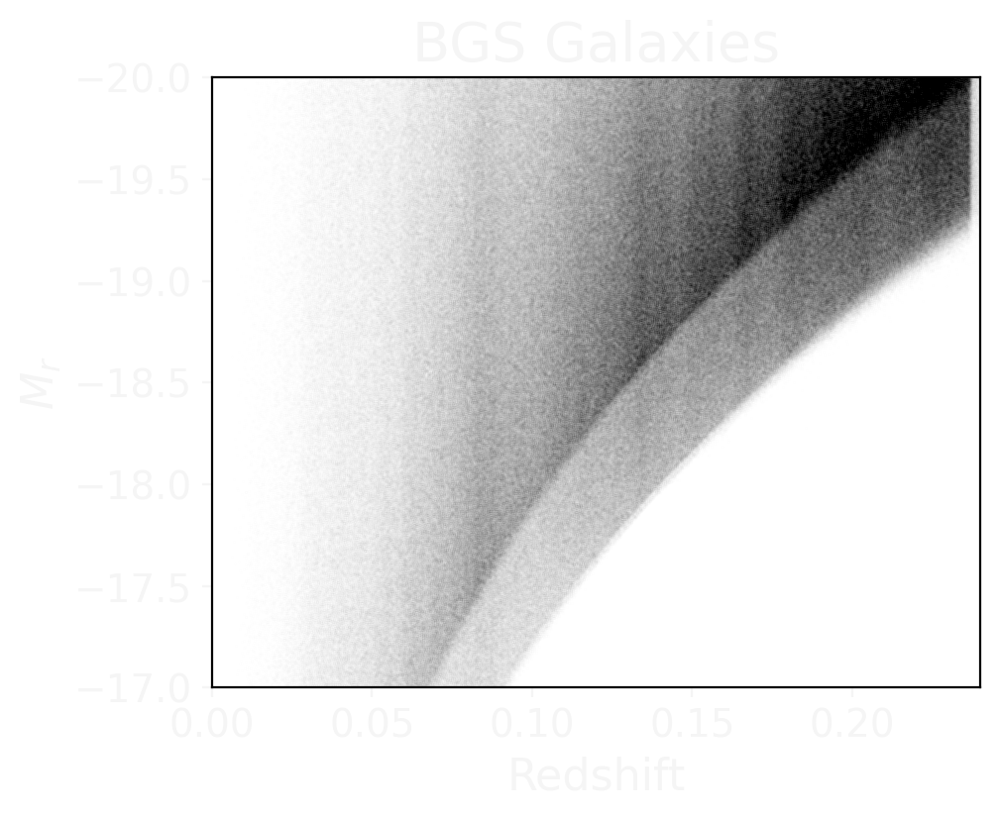

In [53]:
check_sample_binning(mr_min=-20, mr_max=-17)

In [75]:
print(counts_wall)

[19433, 22042, 21509, 24461, 25682, 23752, 25297, 18503, 21151, 20441, 22012, 24380, 25512, 21863, 18868, 19745, 20435, 20375, 21132, 24077, 22958, 18849, 17512, 21403, 19800, 19537, 20898, 21030, 19704, 16853, 17750, 20982, 19087, 19782, 18677, 17905, 19317, 15677, 16328, 16791, 19371, 20189, 14924, 14036, 16260, 20420, 20680, 15652, 15636]


In [76]:
print(counts_void)

[10213, 10213, 10214, 10213, 10214, 10213, 10213, 10213, 10213, 10214, 10213, 10214, 10213, 10213, 10213, 10213, 10213, 10214, 10213, 10213, 10213, 10213, 10213, 10213, 10214, 10213, 10213, 10213, 10213, 10213, 10214, 10213, 10214, 10213, 10213, 10213, 10213, 10214, 10213, 10214, 10213, 10213, 10213, 10213, 10214, 10213, 10214, 10213, 10213]


Estimated Counts =20087.081632653062


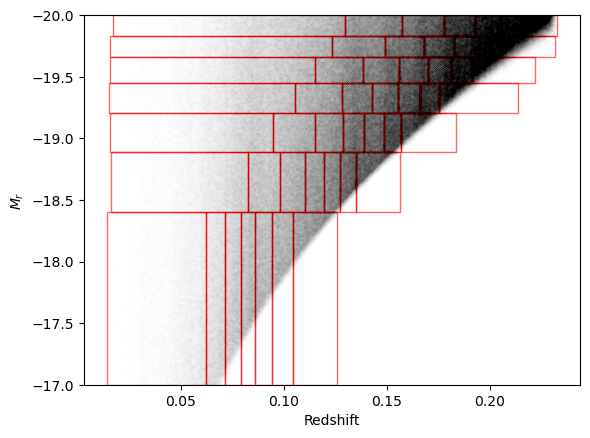

In [101]:
rshift = get_property('z', 'VF', 'all', 'BGS Bright')
mr = get_property('mr', 'VF', 'all', 'BGS Bright')
void_property = get_property('mr', 'VF', 'void', 'BGS Bright')
wall_property = get_property('mr', 'VF', 'wall', 'BGS Bright')
void_redshift = get_property('z', 'VF', 'void', 'BGS Bright')
wall_redshift = get_property('z', 'VF', 'wall', 'BGS Bright')
galaxy_redshift = get_property('z', 'VF', 'all', 'BGS Bright')
void_mr = get_property('mr', 'VF', 'void', 'BGS Bright')
wall_mr = get_property('mr', 'VF', 'wall', 'BGS Bright')
galaxy_mr = get_property('mr', 'VF', 'all', 'BGS Bright')



counts_wall = []
counts_void = []
# Define magnitude bins (M_r)
mr_mask = (void_mr >= -20) & (void_mr <= -17)
mr_bins = np.quantile(void_mr[mr_mask],
                      np.linspace(0, 1, 8))

for mrmin, mrmax in zip(mr_bins[:-1], mr_bins[1:]):
    # Pre-select redshift range for quantiles
    pre_bin = get_mr_z_bin(galaxy_redshift, 0, np.inf, galaxy_mr, mrmin, mrmax, galaxy_redshift, 'redshift')

    z_bins = np.quantile(pre_bin, np.linspace(0, 1, 8))

    for zmin, zmax in zip(z_bins[:-1], z_bins[1:]):
        void_bin = get_mr_z_bin(void_redshift, zmin, zmax, void_mr, mrmin, mrmax, void_property, 'mr')
        wall_bin = get_mr_z_bin(wall_redshift, zmin, zmax, wall_mr, mrmin, mrmax, wall_property, 'mr')


        rect = Rectangle(
            (zmin, mrmin),               # lower-left corner
            zmax - zmin,               
            mrmax - mrmin,               
            linewidth=1,
            edgecolor='red',
            facecolor='none',
            alpha=0.6
        )

        plt.gca().add_patch(rect)

        if len(void_bin) > 0 and len(wall_bin) > 0:
            # Downsample to equal sizes
            min_len = min(len(void_bin), len(wall_bin))
            np.random.seed(0)
            counts_wall.append(len(wall_bin))
            counts_void.append(len(void_bin))
            void_bin = np.random.choice(void_bin, min_len, replace=False)
            wall_bin = np.random.choice(wall_bin, min_len, replace=False)
            counts.append(2*min_len)

plt.scatter(rshift, mr, s=.0001, color='black', alpha=.2)
plt.xlabel('Redshift')
plt.ylabel(r'$M_r$')
plt.ylim(-20,-17)
plt.gca().invert_yaxis()

print("Estimated Counts ="+str(np.mean(counts)))

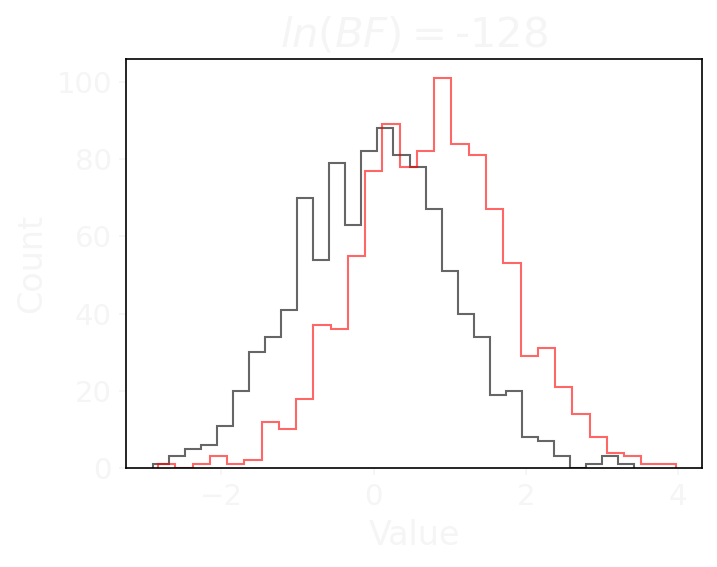

In [121]:
# Generate random normal data
data1 = np.random.normal(loc=0, scale=1, size=1000)   # mean=0, std=1
data2 = np.random.normal(loc=.75, scale=1, size=1000) # different distribution
BF = get_bayes_factor(data1, data2, log_BF = True)

# Create figure
plt.figure(figsize=(5, 4), dpi=150, facecolor = 'none')

# Plot histograms
plt.hist(data1, histtype='step', bins=30, alpha=0.6, color='black')
plt.hist(data2, histtype='step', bins=30, alpha=0.6, color='red')

# Labels and styling
plt.xlabel('Value', fontsize = 16, color = 'whitesmoke')
plt.ylabel('Count', fontsize = 16, color = 'whitesmoke')
plt.title(r'$ln(BF)=$'+f"{BF:.3g}", fontsize = 20, color = 'whitesmoke')
plt.tick_params(axis='both', labelcolor='whitesmoke', color = 'whitesmoke')
plt.tight_layout()

plt.show()

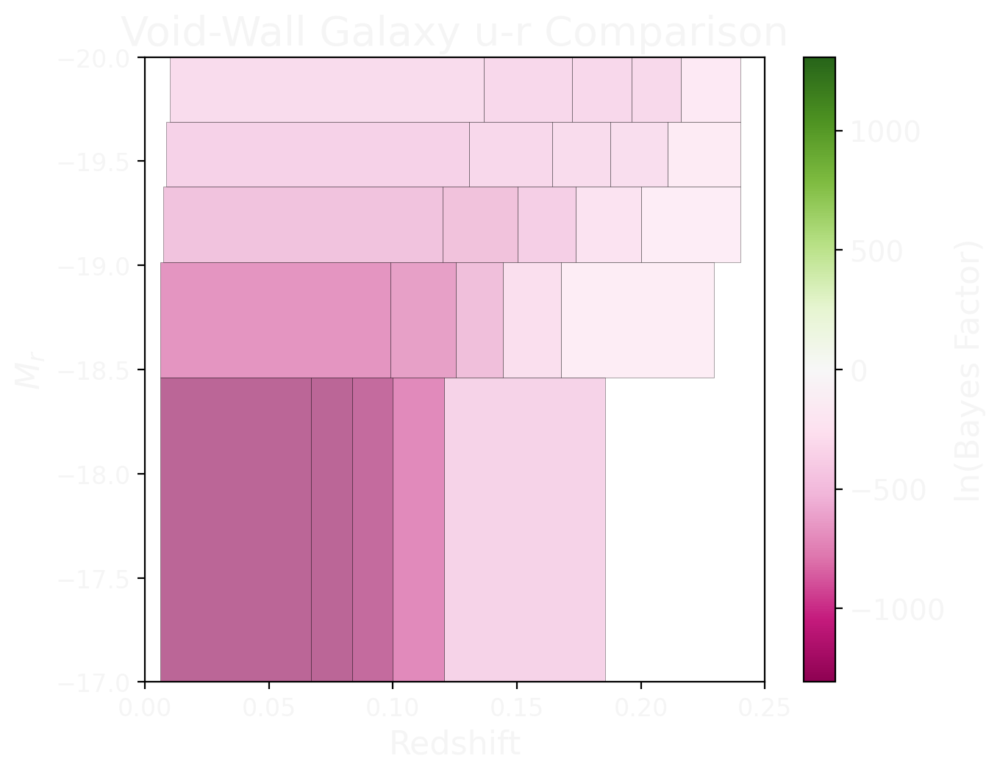

In [139]:
plot_heatmap_diagnostic('u-r', num_mr_bins=5, num_z_bins=5, linewidth=.2, axsize=20, color='PiYG', sample='BGS', ax=None, mr_min=-20, mr_max=-17, lim17=False)